# 9r_young_adults_sex: net migration at ages 20–39 by sex after the quakes, and socio-economic factors (Tohoku, Kumamoto)

5r figures 30 and 32–34 used all ages. This notebook repeats them for **ages 20–39**, separately for **men and women**.

**Net migration: the residual method of 4r/5r**
- **Population split:** each municipality's population by sex is split into single years with `ungroup::pclm2D`, **without** the national offset, over counts 2006–2026. Both λ are chosen by BIC, with `kr` = 2, rescaled to keep every published band.
- **Deaths:** split into single years by sex with 1D `pclm`.
- **Residual:** net migration of a single-year cohort = its population at the next count − its population now + its deaths in between. The 2011 excess deaths go to the interval 2011-03-31 → 2012-03-31, and the 2012 interval is 0.75 years, both as in 5r.
- **Ages 20–39 at the interval's starting count:** rate = 1000 · Σ net migration ÷ Σ starting population over those cohorts.
- **Both sexes** = men + women (both residuals summed).

**Outcomes, as in 5r figure 30**
- **x:** the intervals starting 2010 and 2011, summed, minus twice the mean annual rate of the intervals starting 2006 to 2009.
- **y:** the same for the intervals starting 2013 and 2014.
- **Units:** per 1,000, two years. The 2013 interval is affected by the reference-date issue (`doc/caution.md` §1).

**Socio-economic analysis (figures 2–3).** As in 5r figures 32–33, done for men and women separately:
- **Sample:** the 32 Tohoku municipalities of sheet `6_社会経済37` (全壊率 ≥ 1), minus the evacuation-order 南相馬市 and 双葉町, so n = 30.
- **Explanatory variables:** the sheet's pre-quake indicators and the same sex's 2010–11 loss.
- **Analyses:** univariate Spearman; one indicator at a time adjusted for the loss; a full multivariable model; backward AIC; leave-one-out error.

**Why no offset.** The national single-year shape ends in 2020, and the offset fits of 5r stop at the 2016 count. Ages 20–39 are unaffected by the no-offset split (6r). The 1944–50 band-edge problem is at ages 55–79.

For Kumamoto, all figures use the reported movers by sex (住民基本台帳人口移動報告, 2014–2025), not the residual. Figure 23 compares women aged 20–39 with the rest of the population. Figures 19–22 repeat the women's analysis with a reproductive-value-weighted outcome (national Fisher reproductive value). Figures 8–17 show all ages by sex (age profile, stacked change, heatmaps by group and by municipality) for both disasters. Figures 5–7 are the 20–39 by-sex versions of 5r figures 25 and 34 and 3r figure 13. Figure 4 and the Kumamoto table repeat the analysis for Kumamoto (2016–17 vs 2020–21 and 2022–23, relative to 2014–15); its socio-economic sheet has only 5 municipalities, too few for regression.

Figures: `res/9r_<NN>_<item>.png`. The 2D fits by sex are cached in `output/9r_pclm2d_tohoku_sex_2006_2026.qs2`; delete the file to refit (with `OPENBLAS_NUM_THREADS=1`, set in the Dockerfile; see the setup cell).

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

root <- if (dir.exists("dt")) "." else ".."
# Parallel fits (parallel::mclapply) need one BLAS thread per worker, otherwise every forked
# worker starts one OpenBLAS thread per core and refitting the caches is ~10x slower.
# The Dockerfile sets OPENBLAS_NUM_THREADS=1; outside the container, run
# OPENBLAS_NUM_THREADS=1 jupyter nbconvert ... (setting it inside R after startup has no effect).
if (Sys.getenv("OPENBLAS_NUM_THREADS") != "1")
  warning("OPENBLAS_NUM_THREADS is not 1: refitting the pclm caches will be about 10x slower.", call. = FALSE)
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "9r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}
top_age <- 105

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Population: Basic Resident Register (住民基本台帳), Japanese residents, by sex. Deaths: Vital Statistics (人口動態統計), ",
                   "Japanese, by residence and sex. Net migration = residual (population change + deaths), 2D split without national offset.")
kum_note <- paste0("Migrants: 住民基本台帳人口移動報告 (Statistics Bureau, e-Stat), Japanese movers between municipalities, by sex and age at the move. ",
                   "Population: Basic Resident Register (住民基本台帳), Japanese residents, 1 January, by sex.")
sex_levels <- c("Both sexes", "Men", "Women")
sex_cols <- c("Both sexes" = "#5c5c58", "Men" = "#2a78d6", "Women" = "#eb6834")

perm_rho <- function(x, y, B = 10000, seed = 0) {
  rho <- cor(x, y, method = "spearman")
  set.seed(seed)
  null <- replicate(B, cor(x, sample(y), method = "spearman"))
  c(rho = rho, p = (1 + sum(abs(null) >= abs(rho))) / (B + 1))
}

In [2]:
# Tohoku study municipalities and groups (as in 5r)
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 %in% c("東日本", "福島")) |>
  transmute(code = 市町村コード, muni = 市町村, pref = 県, short = sub("^.+郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`),
            evacuation = 避難指示あり %in% c("TRUE", "True", "1")) |>
  mutate(group = case_when(pref == "福島県" & evacuation ~ "福島 避難指示 (evacuation order)",
                           pref != "福島県" & zenkai_rate >= 1 ~ "岩手・宮城 全壊率 ≥ 1",
                           TRUE ~ "Other listed (Tohoku)"),
         short_lab = paste0(short, ifelse(evacuation, "†", "")))
group_levels <- c("岩手・宮城 全壊率 ≥ 1", "福島 避難指示 (evacuation order)", "Other listed (Tohoku)")
group_cols <- setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels)
study |> count(group) |> as.data.frame()

counts <- 2006:2026
sex_map <- c("男" = "Men", "女" = "Women")
pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex %in% names(sex_map), year %in% counts) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age_band = as.character(age_band), n = pop)
dth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex %in% names(sex_map), year %in% 2006:2025) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age_band = as.character(age_band), n)
stopifnot(setequal(unique(pop5$sex), c("Men", "Women")), setequal(unique(dth5$sex), c("Men", "Women")))
bind_rows(pop5 |> filter(age_band == "total") |> mutate(series = "population"),
          dth5 |> filter(age_band == "total") |> mutate(series = "deaths")) |>
  group_by(series, sex) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"), total = sum(n), .groups = "drop") |>
  as.data.frame()

group,n
<chr>,<int>
Other listed (Tohoku),91
岩手・宮城 全壊率 ≥ 1,22
福島 避難指示 (evacuation order),10


series,sex,municipalities,years,total
<chr>,<chr>,<int>,<chr>,<dbl>
deaths,Men,123,2006–2025,577649
deaths,Women,123,2006–2025,561187
population,Men,123,2006–2026,45351295
population,Women,123,2006–2026,47698368


In [3]:
# Single-year splits (functions as in 5r, without the national offset)
band_table <- function(bands, counts) {
  keep <- !bands %in% c("total", "unknown")
  if (any(bands == "80_84")) keep <- keep & bands != "80+"
  tibble(band = bands[keep], n = counts[keep]) |>
    mutate(lower = as.integer(sub("[_+].*", "", band))) |>
    arrange(lower)
}
ungroup_bands <- function(bands, counts) {
  b <- band_table(bands, counts)
  ages <- 0:(top_age - 1)
  band <- findInterval(ages, b$lower)
  if (sum(b$n) == 0) return(tibble(age = ages, fit = 0))
  m <- pclm(x = b$lower, y = pmax(b$n, 1e-4), nlast = top_age - max(b$lower), verbose = FALSE)
  raw <- unname(fitted(m))
  tibble(age = ages, fit = raw * (b$n / pmax(tapply(raw, band, sum), 1e-12))[band])
}
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90_94", "95_99", "100+"), "80+", b)
fit2d_plain <- function(g) {
  b <- g |> group_by(year) |>
    filter(age_band != "total", !(age_band == "80+" & any(age_band == "80_84"))) |> ungroup() |>
    mutate(band = to80(age_band)) |>
    group_by(year, band) |> summarise(n = sum(n), .groups = "drop") |>
    mutate(lower = as.integer(sub("[_+].*", "", band)))
  Y <- b |> select(year, lower, n) |> pivot_wider(names_from = year, values_from = n) |> arrange(lower)
  yrs <- as.integer(colnames(Y)[-1])
  m <- tryCatch(suppressWarnings(
    pclm2D(Y$lower, as.data.frame(Y[, -1]), nlast = top_age - max(Y$lower), verbose = FALSE,
           control = list(lambda = c(NA, NA), kr = 2, int.lambda = c(0.1, 1e5)))),
    error = function(e) NULL)
  if (is.null(m)) return(NULL)
  raw <- as.matrix(fitted(m))
  if (any(!is.finite(raw)) || any(raw <= 0)) return(NULL)
  band <- findInterval(0:(top_age - 1), Y$lower)
  bind_rows(lapply(seq_along(yrs), function(j) {
    sc <- (Y[[j + 1]] / tapply(raw[, j], band, sum))[band]
    tibble(year = yrs[j], age = 0:(top_age - 1), fit = raw[, j] * sc)
  }))
}

cache9 <- file.path(root, "output/9r_pclm2d_tohoku_sex_2006_2026.qs2")
if (file.exists(cache9)) {
  f9 <- qs_read(cache9)
} else {
  t0 <- Sys.time()
  ncores <- max(1, parallel::detectCores() - 1)
  grp <- split(pop5, list(pop5$code, pop5$sex), drop = TRUE)
  pop_fits <- parallel::mclapply(grp, function(g) {
    r <- fit2d_plain(g)
    method <- "pclm2D"
    if (is.null(r)) {   # fallback: 1D pclm per year
      r <- g |> group_by(year) |> group_modify(function(h, k) ungroup_bands(h$age_band, h$n)) |> ungroup()
      method <- "1D pclm (2D failed)"
    }
    mutate(r, code = g$code[1], sex = g$sex[1], method = method, .before = 1)
  }, mc.cores = ncores, mc.preschedule = FALSE)
  dgrp <- split(dth5, list(dth5$code, dth5$sex, dth5$year), drop = TRUE)
  dth_fits <- parallel::mclapply(dgrp, function(g)
    ungroup_bands(g$age_band, g$n) |> mutate(code = g$code[1], sex = g$sex[1], year = g$year[1], .before = 1),
    mc.cores = ncores)
  f9 <- list(pop = bind_rows(pop_fits), deaths = bind_rows(dth_fits))
  message("Fits in ", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(f9, cache9)
}
f9$pop |> distinct(code, sex, method) |> count(sex, method) |> as.data.frame()
# Check: the splits keep the published totals
chk9 <- f9$pop |> group_by(code, sex, year) |> summarise(fit = sum(fit), .groups = "drop") |>
  inner_join(pop5 |> filter(age_band == "total") |> select(code, sex, year, n), by = c("code", "sex", "year"))
cat("Population: max |fit − published total| =", signif(max(abs(chk9$fit - chk9$n)), 3), "\n")

sex,method,n
<chr>,<chr>,<int>
Men,pclm2D,123
Women,pclm2D,123


Population: max |fit − published total| = 9.09e-13 


In [4]:
# Deaths per interval (as in 5r): 2011 excess deaths to the interval 2011-03-31 -> 2012-03-31
excess_to <- 2011
DI9 <- f9$deaths |> group_by(sex) |> group_modify(function(dd, k) {
  Dw <- dd |> select(code, year, age, D = fit) |> pivot_wider(names_from = year, values_from = D, names_prefix = "D")
  dt_ <- function(y) Dw[[paste0("D", y)]]
  B <- 0.5 * (dt_(2009) + dt_(2010)); E <- dt_(2011) - B
  bind_rows(lapply(2006:2025, function(s) {
    d <- if (s == 2010) 0.75 * dt_(2010) + 0.25 * B + (excess_to == 2010) * E
         else if (s == 2011) 0.75 * B + 0.25 * dt_(2012) + (excess_to == 2011) * E
         else if (s < 2011) 0.75 * dt_(s) + 0.25 * dt_(s + 1)
         else if (s == 2012) 0.75 * dt_(2012) else dt_(s)
    tibble(code = Dw$code, age = Dw$age, start = s, Dint = d)
  }))
}) |> ungroup()

# Residual per single-year cohort (as compute_res() in 5r); age = age at the interval's starting count
make_res <- function(P9, DI9) P9 |> rename(start = count, P0 = P) |>
  inner_join(P9 |> transmute(code, sex, start = count - 1, age = age - 1, P1_next = P), by = c("code", "sex", "start", "age")) |>
  left_join(P9 |> transmute(code, sex, start = count - 1, age, P1_same = P), by = c("code", "sex", "start", "age")) |>
  inner_join(DI9 |> group_by(code, sex, start) |> arrange(age, .by_group = TRUE) |>
               mutate(Dc = 0.5 * (Dint + lead(Dint, default = 0))) |> ungroup() |> select(code, sex, start, age, Dc),
             by = c("code", "sex", "start", "age")) |>
  mutate(span = ifelse(start == 2012, 0.75, 1),
         P1 = ifelse(start == 2012, 0.75 * P1_next + 0.25 * coalesce(P1_same, P1_next), P1_next),
         NM = P1 - P0 + Dc)
P9 <- f9$pop |> select(code, sex, count = year, age, P = fit)
res9 <- make_res(P9, DI9)

# Ages 20-39 at the interval start, by sex and both sexes (men + women)
y9 <- res9 |> filter(age >= 20, age <= 39) |>
  group_by(code, sex, start, span) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop")
y9 <- bind_rows(y9, y9 |> group_by(code, start, span) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
                  mutate(sex = "Both sexes")) |>
  mutate(cum = 1000 * NM / P0, rate = cum / span) |>
  group_by(code, sex) |> mutate(base = mean(rate[start %in% 2006:2009])) |> ungroup()
sc9 <- y9 |> group_by(code, sex) |>
  summarise(base = first(base),
            x = sum(cum[start %in% 2010:2011]) - 2 * first(base),
            y = sum(cum[start %in% 2013:2014]) - 2 * first(base),
            n_int = sum(start %in% c(2010, 2011, 2013, 2014)),
            pop2039_2010 = P0[start == 2010], .groups = "drop") |>
  inner_join(study, by = "code") |>
  mutate(sex = factor(sex, levels = sex_levels), group = factor(group, levels = group_levels))
stopifnot(all(sc9$n_int == 4), nrow(sc9) == 3 * nrow(study))

# Table: group medians (per 1,000, 2 years), and the pre-quake baseline (per 1,000 per year)
sc9 |> group_by(sex, group) |>
  summarise(n = n(), median_base = round(median(base), 1), median_x = round(median(x), 1), median_y = round(median(y), 1),
            y_below_0 = sum(y < 0), .groups = "drop") |> as.data.frame()

sex,group,n,median_base,median_x,median_y,y_below_0
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<int>
Both sexes,岩手・宮城 全壊率 ≥ 1,22,-12.8,-37.9,29.3,4
Both sexes,福島 避難指示 (evacuation order),10,-12.9,-39.3,-3.1,6
Both sexes,Other listed (Tohoku),91,-15.7,7.6,14.6,22
Men,岩手・宮城 全壊率 ≥ 1,22,-11.8,-35.7,31.6,4
Men,福島 避難指示 (evacuation order),10,-12.1,-63.0,-6.0,6
Men,Other listed (Tohoku),91,-13.8,9.1,14.4,23
Women,岩手・宮城 全壊率 ≥ 1,22,-14.4,-41.2,25.1,4
Women,福島 避難指示 (evacuation order),10,-21.2,-41.1,0.0,5
Women,Other listed (Tohoku),91,-16.1,1.4,11.8,29


## Figure 1: ages 20–39, net migration in 2010–11 vs 2013–14, relative to 2006–09, by sex

5r figure 30 for ages 20–39 at the interval start: one point per listed Tohoku municipality, one panel per sex (both sexes = men + women).
- **Axes:** per 1,000 of each interval's starting population of the age group, summed over two intervals, minus twice the 2006–09 mean annual rate.
- **Statistics:** Spearman ρ (permutation test, 10,000 draws, seed 0) and the dashed OLS line exclude the 福島 evacuation-order municipalities (†).
- **Dotted line y = −x:** where the 2013–14 gain would exactly make up the 2010–11 loss.
- **Small towns are noisy:** 20–39 is only a few hundred people per sex there, so single points can move by ±20.

sex,n,rho,p,slope
<fct>,<int>,<dbl>,<dbl>,<dbl>
Both sexes,113,0.19,0.0480,0.12
Men,113,0.18,0.0560,0.17
Women,113,0.34,0.0004,0.22


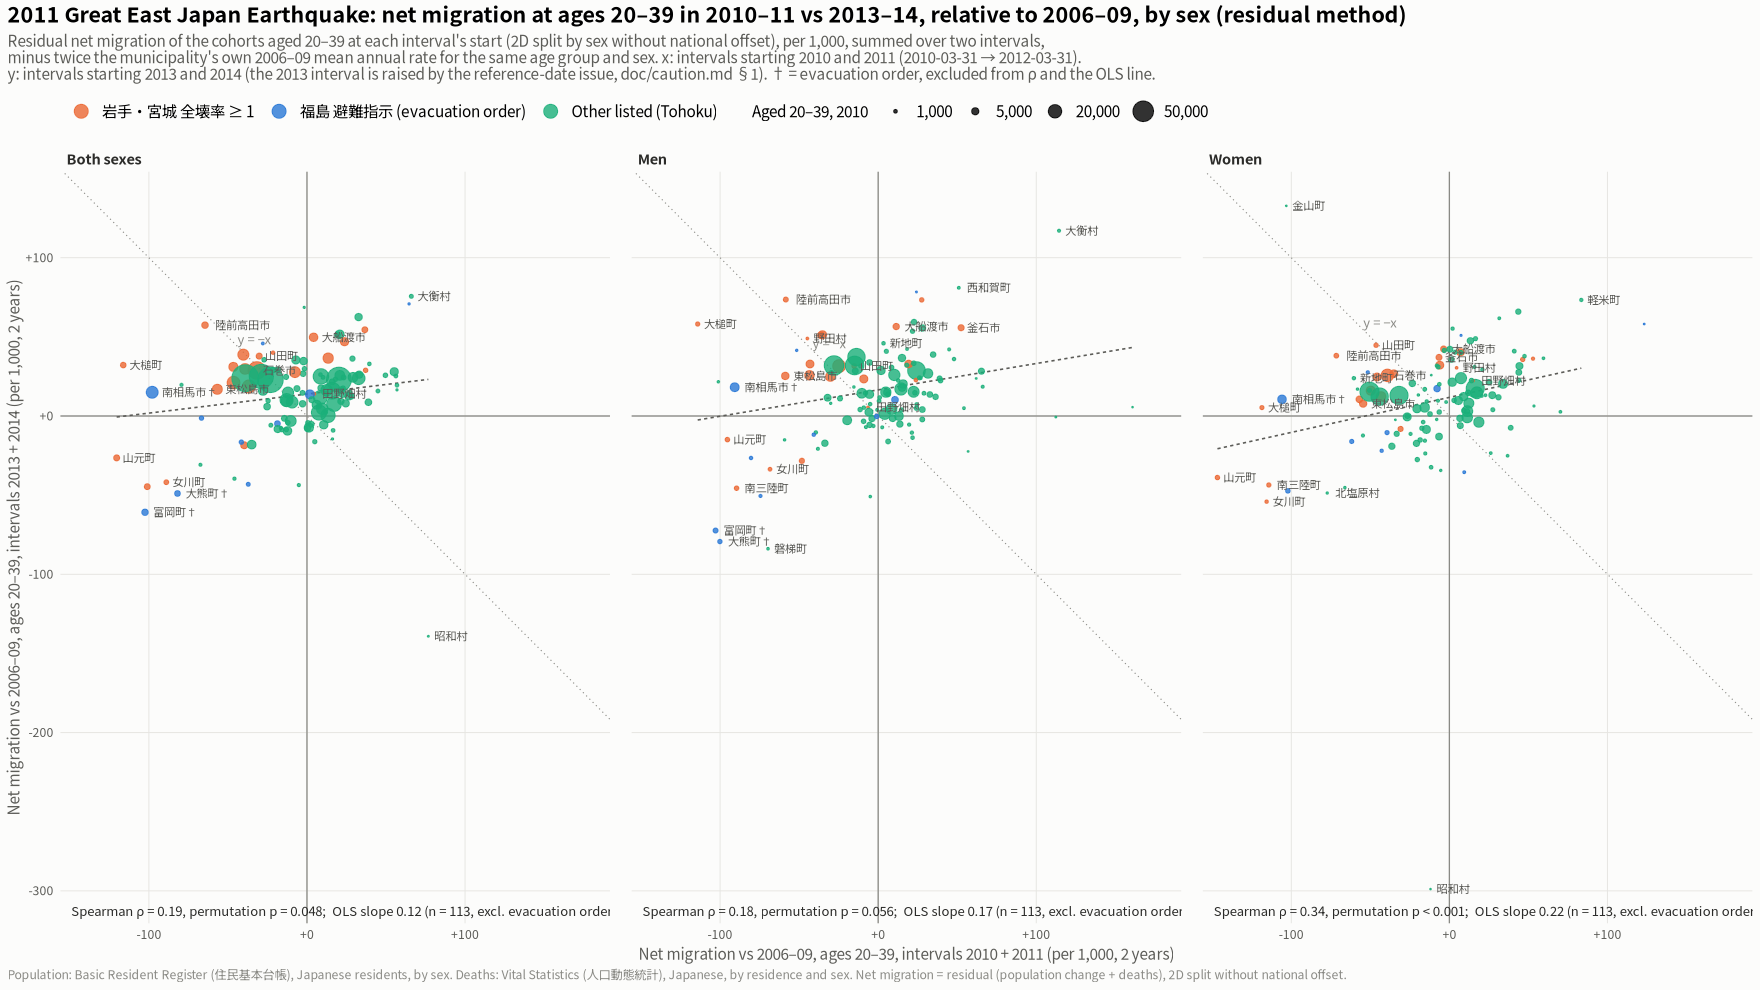

In [5]:
fit9 <- sc9 |> filter(!evacuation)
stat9 <- fit9 |> group_by(sex) |> group_modify(function(d, k) {
  pr <- perm_rho(d$x, d$y)
  tibble(n = nrow(d), rho = pr[["rho"]], p = pr[["p"]], slope = coef(lm(y ~ x, data = d))[[2]])
}) |> ungroup() |>
  mutate(lab = sprintf("Spearman ρ = %.2f, permutation p %s;  OLS slope %.2f (n = %d, excl. evacuation order)",
                       rho, ifelse(p < 0.001, "< 0.001", sprintf("= %.3f", p)), slope, n))
stat9 |> select(-lab) |> mutate(across(c(rho, slope), \(v) round(v, 2)), p = signif(p, 2)) |> as.data.frame()

lab9 <- sc9 |> group_by(sex) |> filter(zenkai_rate >= 5 | rank(x) <= 5 | rank(y) <= 3 | rank(-y) <= 2) |> ungroup()
ann9 <- sc9 |> group_by(sex) |> summarise(xa = min(x), .groups = "drop")
p1 <- ggplot(sc9, aes(x, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_abline(slope = -1, intercept = 0, colour = ink3, linewidth = 0.35, linetype = "13") +
  geom_text(data = ann9, aes(x = xa * 0.4, y = -xa * 0.4, label = "y = −x"), hjust = -0.2, size = 3, colour = ink3, family = jp_font) +
  geom_smooth(data = fit9, method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pop2039_2010), alpha = 0.8) +
  geom_text(data = lab9, aes(label = short_lab), size = 2.6, colour = ink2, family = jp_font,
            hjust = -0.18, vjust = 0.5, check_overlap = TRUE) +
  geom_text(data = stat9, aes(x = -Inf, y = -Inf, label = lab), inherit.aes = FALSE,
            hjust = -0.02, vjust = -0.8, size = 3, colour = ink, family = jp_font) +
  facet_wrap(~sex, nrow = 1) +
  scale_x_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.03, 0.1))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_size_area(max_size = 8, breaks = c(1e3, 5e3, 2e4, 5e4), labels = scales::comma, name = "Aged 20–39, 2010") +
  labs(title = "2011 Great East Japan Earthquake: net migration at ages 20–39 in 2010–11 vs 2013–14, relative to 2006–09, by sex (residual method)",
       subtitle = paste0("Residual net migration of the cohorts aged 20–39 at each interval's start (2D split by sex without national offset), per 1,000, summed over two intervals,\n",
                         "minus twice the municipality's own 2006–09 mean annual rate for the same age group and sex. ",
                         "x: intervals starting 2010 and 2011 (2010-03-31 → 2012-03-31).\n",
                         "y: intervals starting 2013 and 2014 (the 2013 interval is raised by the reference-date issue, doc/caution.md §1). † = evacuation order, excluded from ρ and the OLS line."),
       x = "Net migration vs 2006–09, ages 20–39, intervals 2010 + 2011 (per 1,000, 2 years)",
       y = "Net migration vs 2006–09, ages 20–39, intervals 2013 + 2014 (per 1,000, 2 years)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p1, "01_2039_net_1011_vs_1314_by_sex", width = 20, height = 8.5)

## Figures 2–3: socio-economic indicators and net migration of 20–39-year-olds in 2013–14, by sex (全壊率 ≥ 1)

5r figures 32–33 for ages 20–39, run separately for men, women and both sexes.

**Data and sample**
- **Outcome:** y from figure 1, for the same sex.
- **Sample:** the Tohoku rows of sheet `6_社会経済37` (32 municipalities with 全壊率 ≥ 1), minus 南相馬市 and 双葉町 (evacuation order): n = 30.
- **Missing values:** `DID人口比` blank = 0 (no densely inhabited district). `持ち家率` (blank for 10 of the 30) is univariate only.

**Analyses**
1. **Univariate:** Spearman ρ with a permutation test, Holm-adjusted across the 11 variables within each sex.
2. **Adjusted one at a time:** y ~ the same sex's 2010–11 loss + indicator; the slope per 1 SD.
3. **Full model:** y ~ 2010–11 loss + 8 indicators (`持ち家率` and `職住自足率（従業地/常住就業者）` left out as in 5r).
   - Checks: backward AIC, and leave-one-out RMSE against the loss-only model, with the stepwise selection repeated inside each fold.

The sheet also has the protocol's recovery outcomes (`女性20-39 2〜5年目の差の合計`, `20-39 2〜5年目の差の合計`: gap vs matched controls, years 2–5). The first table compares them with y.

In [6]:
se_vars <- c("市町村内の働く場所÷住民の働き手(%)", "事業所数/人口千人", "通勤流出率", "失業率", "第1次産業比", "第2次産業比",
             "職住自足率（従業地/常住就業者）", "納税者1人当たり課税所得(万円)", "持ち家率", "DID人口比")
se_raw <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"), sheet = "6_社会経済37", col_types = "text")
stopifnot(all(se_vars %in% names(se_raw)))
se9 <- se_raw |> filter(災害 %in% c("東日本", "福島")) |>
  transmute(code = 市町村コード, across(all_of(se_vars), as.numeric),
            prot_2039 = as.numeric(`20-39 2〜5年目の差の合計`), prot_f2039 = as.numeric(`女性20-39 2〜5年目の差の合計`)) |>
  mutate(`DID人口比` = coalesce(`DID人口比`, 0))
loss_var <- "2010–11 net migration vs 2006–09 (same sex, 20–39)"
d9 <- sc9 |> filter(!evacuation) |> inner_join(se9, by = "code") |> mutate(!!loss_var := x)
stopifnot(all(table(d9$sex) == 30))

cat("Spearman of y with the protocol's recovery outcomes (gap vs matched controls, years 2-5):\n")
d9 |> group_by(sex) |>
  summarise(vs_20_39 = round(cor(y, prot_2039, method = "spearman"), 2),
            vs_women_20_39 = round(cor(y, prot_f2039, method = "spearman"), 2), .groups = "drop") |> as.data.frame()

expl9 <- c(loss_var, se_vars)
zs <- function(v) (v - mean(v, na.rm = TRUE)) / sd(v, na.rm = TRUE)
fit_one <- function(d, v, adj) {
  dd <- d |> transmute(y, v = zs(.data[[v]]), loss = zs(x)) |> filter(!is.na(v))
  f <- if (adj == "none" || v == loss_var) y ~ v else y ~ v + loss
  m <- lm(f, data = dd); ci <- confint(m)["v", ]
  tibble(variable = v, model = adj, n = nrow(dd), beta = coef(m)[["v"]], lo = ci[[1]], hi = ci[[2]],
         p = summary(m)$coefficients["v", 4])
}
full_vars <- setdiff(expl9, c("持ち家率", "職住自足率（従業地/常住就業者）"))
key9 <- setNames(full_vars, paste0("v", seq_along(full_vars)))

out9 <- lapply(sex_levels, function(s) {
  d <- d9 |> filter(sex == s)
  uni <- bind_rows(lapply(expl9, function(v) {
    dd <- d |> filter(!is.na(.data[[v]])); pr <- perm_rho(dd[[v]], dd$y)
    tibble(variable = v, n = nrow(dd), rho = pr[["rho"]], p_perm = pr[["p"]])
  })) |> mutate(p_holm = p.adjust(p_perm, "holm"))
  adj <- bind_rows(lapply(c("none", "loss"), function(a) bind_rows(lapply(expl9, fit_one, d = d, adj = a))))
  X <- d |> transmute(y, across(all_of(full_vars), zs)); names(X) <- c("y", names(key9))
  m_full <- lm(y ~ ., data = X)
  full <- tibble(term = names(key9), variable = unname(key9), model = "full", n = nrow(X), beta = coef(m_full)[term],
                 lo = confint(m_full)[term, 1], hi = confint(m_full)[term, 2], p = summary(m_full)$coefficients[term, 4])
  m_step <- step(m_full, trace = 0)
  loo <- function(ff) sqrt(mean(sapply(seq_len(nrow(X)), function(i) { m <- ff(X[-i, ]); (X$y[i] - predict(m, X[i, ]))^2 })))
  list(uni = mutate(uni, sex = s), adj = bind_rows(adj, select(full, -term)) |> mutate(sex = s),
       summary = tibble(sex = s, r2_full = summary(m_full)$r.squared, adj_r2_full = summary(m_full)$adj.r.squared,
                        step_keeps = paste(key9[attr(terms(m_step), "term.labels")], collapse = "; "),
                        loo_null = loo(function(d) lm(y ~ 1, d)), loo_loss = loo(function(d) lm(y ~ v1, d)),
                        loo_full = loo(function(d) lm(y ~ ., d)), loo_step = loo(function(d) step(lm(y ~ ., d), trace = 0))))
})
uni9 <- bind_rows(lapply(out9, `[[`, "uni")); adj9 <- bind_rows(lapply(out9, `[[`, "adj")); sum9 <- bind_rows(lapply(out9, `[[`, "summary"))

cat("\nUnivariate Spearman (n = 30; 持ち家率 n = 20), by sex:\n")
uni9 |> transmute(sex, variable, rho = round(rho, 2), p = signif(p_perm, 2), p_holm = signif(p_holm, 2)) |>
  pivot_wider(names_from = sex, values_from = c(rho, p, p_holm)) |> as.data.frame()
cat("\nSlope per 1 SD (per 1,000, 2 years): unadjusted / adjusted for the 2010-11 loss / full model, with p:\n")
adj9 |> transmute(sex, variable, model, est = sprintf("%+.1f (p %.2g)", beta, p)) |>
  pivot_wider(names_from = c(sex, model), values_from = est) |> as.data.frame()
cat("\nModel summaries (LOO = leave-one-out RMSE, per 1,000, 2 years):\n")
sum9 |> mutate(across(where(is.numeric), \(v) round(v, 2))) |> as.data.frame()

Spearman of y with the protocol's recovery outcomes (gap vs matched controls, years 2-5):


sex,vs_20_39,vs_women_20_39
<fct>,<dbl>,<dbl>
Both sexes,0.86,0.69
Men,0.79,0.56
Women,0.83,0.81



Univariate Spearman (n = 30; 持ち家率 n = 20), by sex:


variable,rho_Both sexes,rho_Men,rho_Women,p_Both sexes,p_Men,p_Women,p_holm_Both sexes,p_holm_Men,p_holm_Women
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"2010–11 net migration vs 2006–09 (same sex, 20–39)",0.27,0.16,0.49,0.150,0.390,0.0075,1.00,1,0.075
市町村内の働く場所÷住民の働き手(%),0.21,0.18,0.30,0.250,0.350,0.1000,1.00,1,0.780
事業所数/人口千人,0.43,0.31,0.51,0.014,0.091,0.0038,0.16,1,0.042
通勤流出率,-0.20,-0.12,-0.30,0.280,0.530,0.0970,1.00,1,0.780
失業率,0.15,0.14,0.09,0.430,0.440,0.6400,1.00,1,1.000
第1次産業比,-0.17,-0.29,-0.09,0.370,0.120,0.6400,1.00,1,1.000
第2次産業比,-0.24,-0.17,-0.40,0.210,0.380,0.0280,1.00,1,0.250
職住自足率（従業地/常住就業者）,0.10,-0.02,0.30,0.600,0.940,0.1000,1.00,1,0.780
納税者1人当たり課税所得(万円),-0.15,-0.04,-0.11,0.430,0.810,0.5500,1.00,1,1.000



Slope per 1 SD (per 1,000, 2 years): unadjusted / adjusted for the 2010-11 loss / full model, with p:


variable,Both sexes_none,Both sexes_loss,Both sexes_full,Men_none,Men_loss,Men_full,Women_none,Women_loss,Women_full
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"2010–11 net migration vs 2006–09 (same sex, 20–39)",+12.7 (p 0.007),+12.7 (p 0.007),+9.0 (p 0.077),+9.2 (p 0.097),+9.2 (p 0.097),+6.3 (p 0.27),+16.5 (p 0.00026),+16.5 (p 0.00026),+11.9 (p 0.017)
市町村内の働く場所÷住民の働き手(%),+5.6 (p 0.26),+3.3 (p 0.47),+2.5 (p 0.8),+5.5 (p 0.33),+3.4 (p 0.55),+9.4 (p 0.44),+5.5 (p 0.27),+3.7 (p 0.36),-4.0 (p 0.66)
事業所数/人口千人,+7.6 (p 0.12),+5.4 (p 0.23),+0.4 (p 0.96),+6.8 (p 0.22),+5.2 (p 0.35),-3.6 (p 0.76),+8.1 (p 0.1),+5.8 (p 0.15),+4.1 (p 0.66)
通勤流出率,-5.6 (p 0.26),-3.4 (p 0.46),-4.7 (p 0.52),-4.0 (p 0.47),-2.2 (p 0.7),-1.5 (p 0.86),-6.9 (p 0.16),-4.8 (p 0.23),-8.5 (p 0.21)
失業率,+8.2 (p 0.095),+6.3 (p 0.16),+3.0 (p 0.61),+9.2 (p 0.097),+8.0 (p 0.14),+1.3 (p 0.86),+7.7 (p 0.12),+5.0 (p 0.22),+5.9 (p 0.3)
第1次産業比,-5.9 (p 0.24),-6.5 (p 0.14),-21.5 (p 0.05),-7.4 (p 0.19),-7.8 (p 0.15),-32.1 (p 0.018),-4.4 (p 0.38),-5.1 (p 0.2),-9.4 (p 0.33)
第2次産業比,-7.2 (p 0.14),-3.4 (p 0.47),-9.2 (p 0.19),-5.4 (p 0.34),-3.8 (p 0.5),-14.8 (p 0.077),-9.5 (p 0.053),-3.0 (p 0.51),-3.0 (p 0.64)
職住自足率（従業地/常住就業者）,+2.1 (p 0.67),-0.6 (p 0.9),NA,+1.2 (p 0.84),-1.6 (p 0.78),NA,+2.8 (p 0.58),+1.0 (p 0.8),NA
納税者1人当たり課税所得(万円),-1.8 (p 0.72),-1.2 (p 0.79),-17.1 (p 0.12),-2.2 (p 0.7),-1.7 (p 0.76),-25.2 (p 0.062),-1.3 (p 0.79),-0.6 (p 0.88),-8.6 (p 0.39)



Model summaries (LOO = leave-one-out RMSE, per 1,000, 2 years):


sex,r2_full,adj_r2_full,step_keeps,loo_null,loo_loss,loo_full,loo_step
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Both sexes,0.54,0.33,"2010–11 net migration vs 2006–09 (same sex, 20–39); 第1次産業比; 第2次産業比; 納税者1人当たり課税所得(万円)",26.83,24.97,30.48,31.27
Men,0.46,0.22,"2010–11 net migration vs 2006–09 (same sex, 20–39); 市町村内の働く場所÷住民の働き手(%); 第1次産業比; 第2次産業比; 納税者1人当たり課税所得(万円); DID人口比",30.15,30.76,37.18,38.39
Women,0.61,0.43,"2010–11 net migration vs 2006–09 (same sex, 20–39); 通勤流出率; 第1次産業比; 第2次産業比; 納税者1人当たり課税所得(万円)",27.08,22.06,26.13,30.15


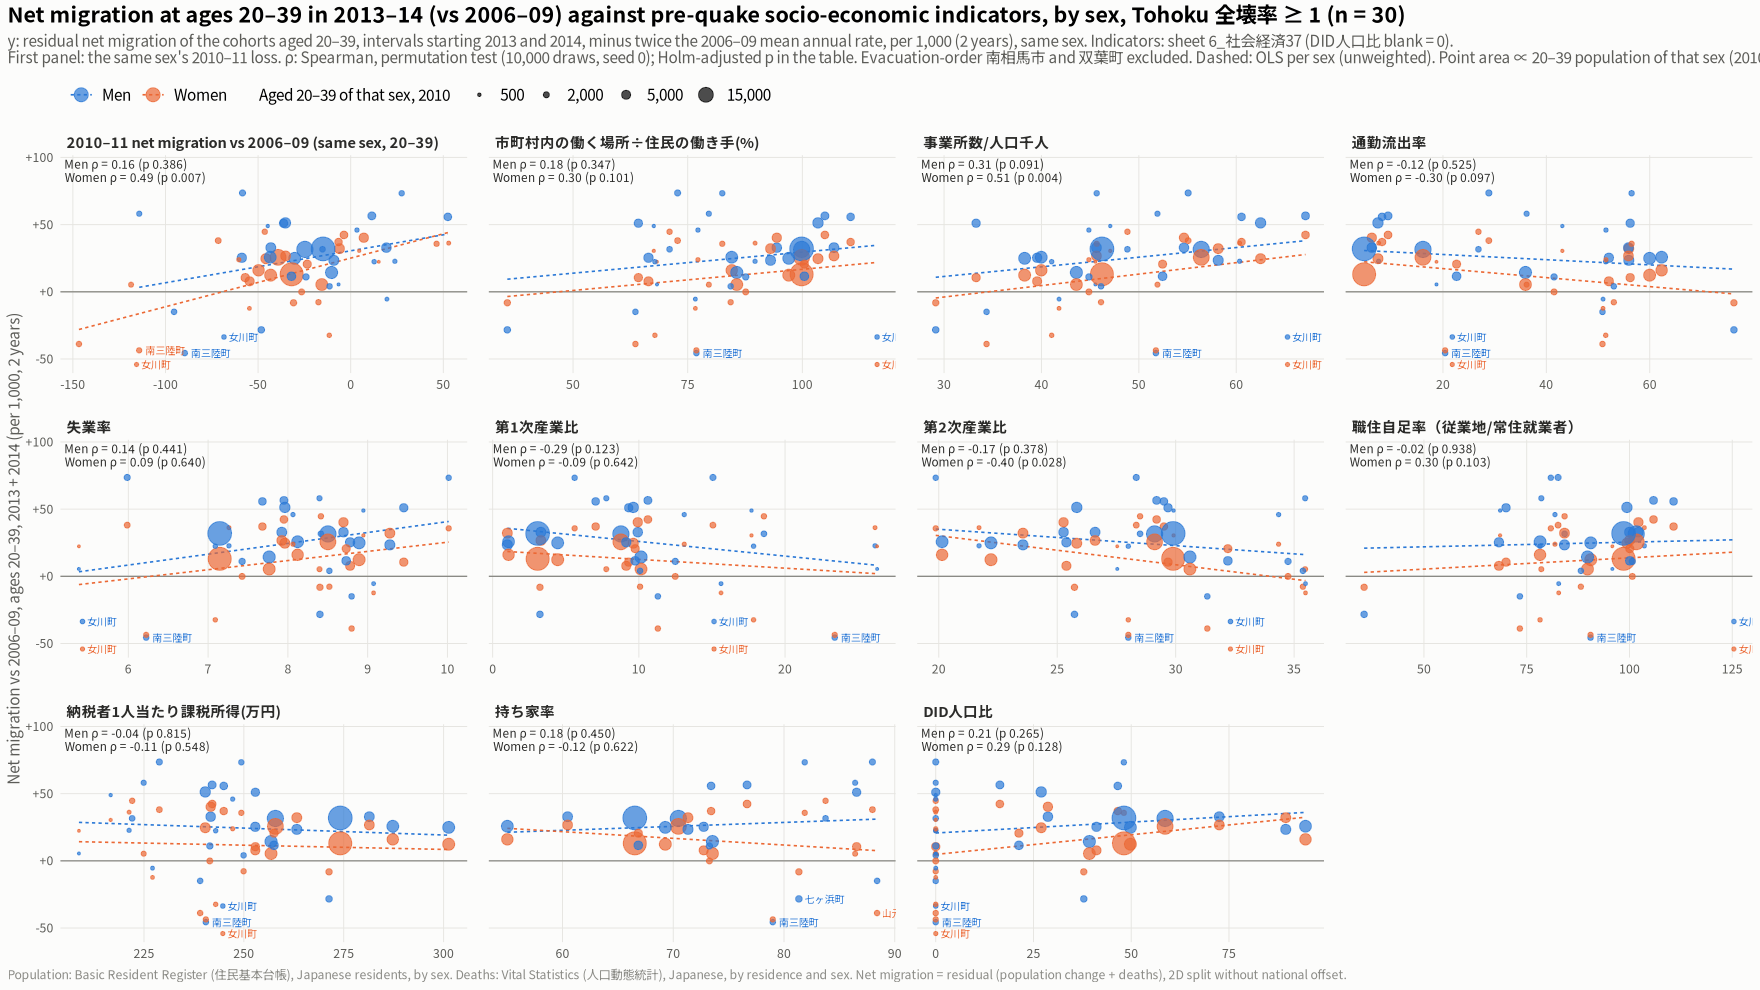

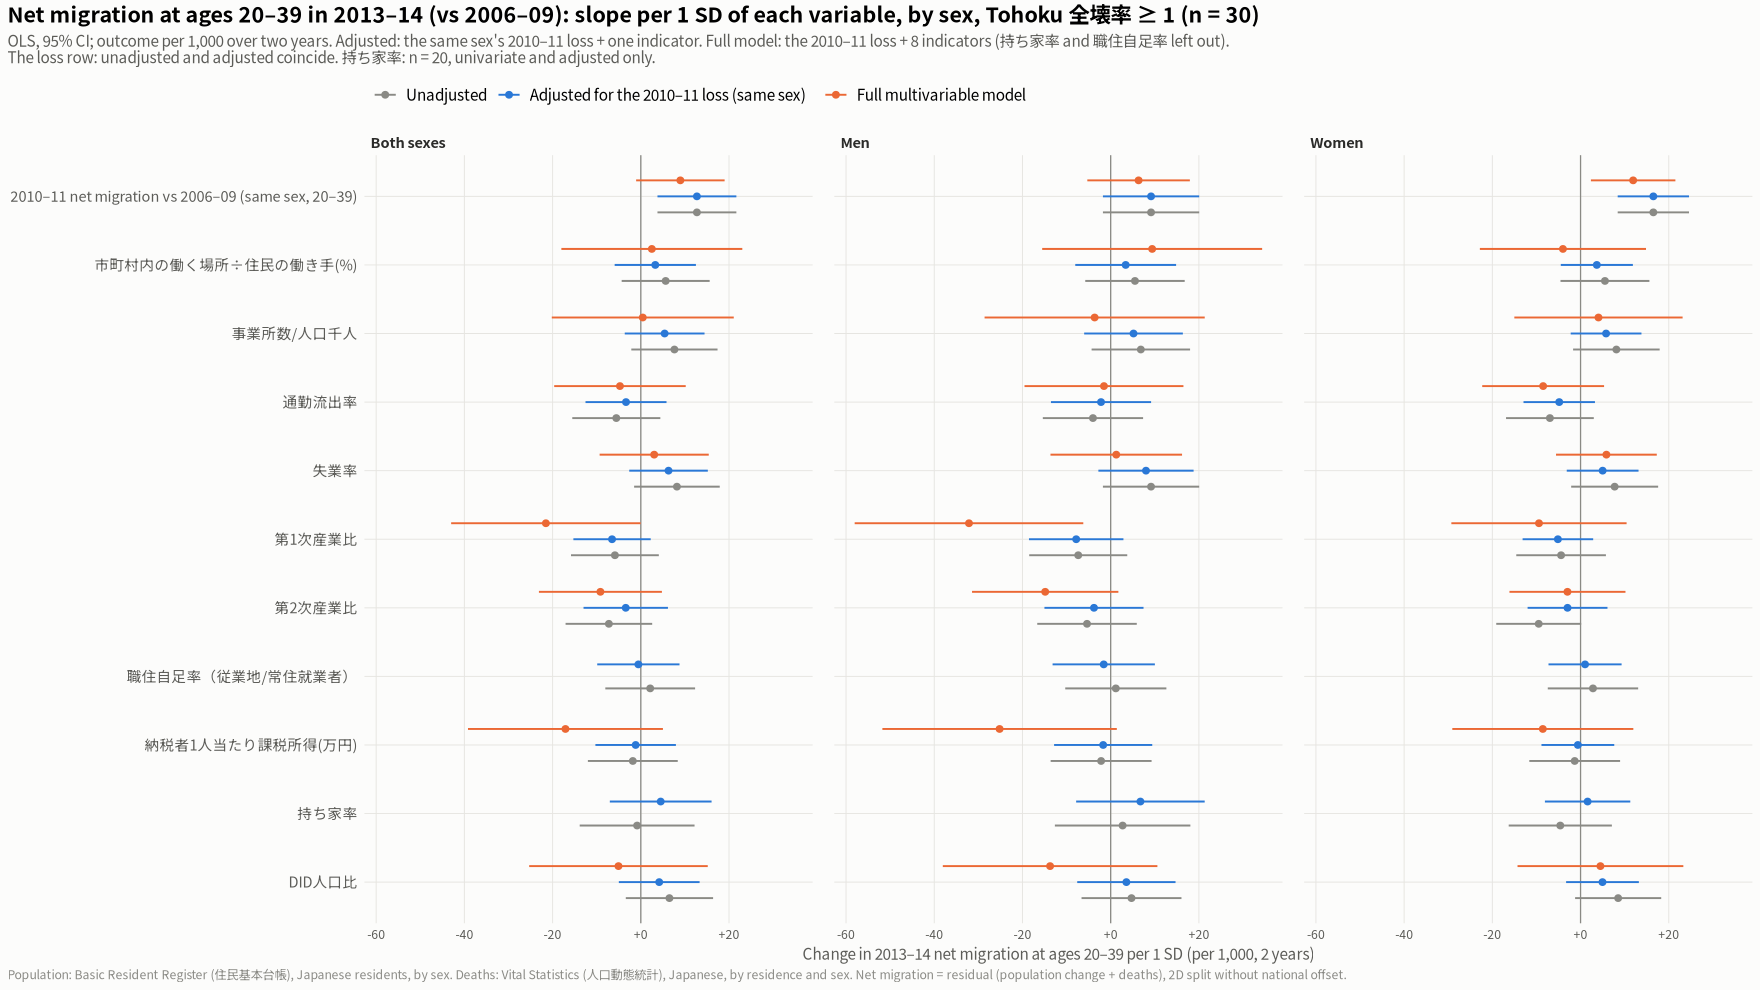

In [7]:
# Figure 2: outcome vs each variable, men and women overlaid
long9 <- d9 |> filter(sex != "Both sexes") |>
  select(code, short_lab, sex, y, pop2039_2010, all_of(expl9)) |>
  pivot_longer(all_of(expl9), names_to = "variable", values_to = "value") |>
  filter(!is.na(value)) |> mutate(variable = factor(variable, levels = expl9))
st9 <- uni9 |> filter(sex != "Both sexes") |>
  group_by(variable) |>
  summarise(lab = paste(sprintf("%s ρ = %.2f (p %s)", sex, rho, ifelse(p_perm < 0.001, "< 0.001", sprintf("%.3f", p_perm))), collapse = "\n"),
            .groups = "drop") |>
  mutate(variable = factor(variable, levels = expl9))
p2 <- ggplot(long9, aes(value, y, colour = sex)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, linewidth = 0.5, linetype = "22") +
  geom_point(aes(size = pop2039_2010), alpha = 0.7) +
  geom_text(data = long9 |> group_by(variable, sex) |> filter(rank(y) <= 2) |> ungroup(),
            aes(label = short_lab), size = 2.3, family = jp_font, hjust = -0.15, check_overlap = TRUE, show.legend = FALSE) +
  geom_text(data = st9, aes(x = -Inf, y = Inf, label = lab), inherit.aes = FALSE, hjust = -0.03, vjust = 1.2,
            size = 2.7, colour = ink, family = jp_font, lineheight = 0.95) +
  facet_wrap(~variable, scales = "free_x", ncol = 4) +
  scale_colour_manual(values = sex_cols[c("Men", "Women")], name = NULL, guide = guide_legend(order = 1, override.aes = list(size = 4))) +
  scale_size_area(max_size = 7, breaks = c(500, 2000, 5000, 15000), labels = scales::comma,
                  name = "Aged 20–39 of that sex, 2010", guide = guide_legend(order = 2)) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.05, 0.22))) +
  labs(title = "Net migration at ages 20–39 in 2013–14 (vs 2006–09) against pre-quake socio-economic indicators, by sex, Tohoku 全壊率 ≥ 1 (n = 30)",
       subtitle = paste0("y: residual net migration of the cohorts aged 20–39, intervals starting 2013 and 2014, minus twice the 2006–09 mean annual rate, per 1,000 (2 years), same sex. ",
                         "Indicators: sheet 6_社会経済37 (DID人口比 blank = 0).\n",
                         "First panel: the same sex's 2010–11 loss. ρ: Spearman, permutation test (10,000 draws, seed 0); Holm-adjusted p in the table. ",
                         "Evacuation-order 南相馬市 and 双葉町 excluded. Dashed: OLS per sex (unweighted). Point area ∝ 20–39 population of that sex (2010)."),
       x = NULL, y = "Net migration vs 2006–09, ages 20–39, 2013 + 2014 (per 1,000, 2 years)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), strip.text = element_text(size = 9.5))
show_save(p2, "02_2039_socioecon_vs_net_1314_by_sex", width = 18, height = 12.5)

# Figure 3: slopes per 1 SD, by sex
mlabs9 <- c(none = "Unadjusted", loss = "Adjusted for the 2010–11 loss (same sex)", full = "Full multivariable model")
f3 <- adj9 |> mutate(model = factor(mlabs9[model], levels = mlabs9), variable = factor(variable, levels = rev(expl9)),
                     sex = factor(sex, levels = sex_levels))
p3 <- ggplot(f3, aes(beta, variable, colour = model)) +
  geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_errorbar(aes(xmin = lo, xmax = hi), width = 0, orientation = "y", linewidth = 0.6, position = position_dodge(width = 0.7)) +
  geom_point(size = 1.8, position = position_dodge(width = 0.7)) +
  facet_wrap(~sex, nrow = 1) +
  scale_colour_manual(values = setNames(c("#8a8a85", "#2a78d6", "#eb6834"), mlabs9), name = NULL) +
  scale_x_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "Net migration at ages 20–39 in 2013–14 (vs 2006–09): slope per 1 SD of each variable, by sex, Tohoku 全壊率 ≥ 1 (n = 30)",
       subtitle = paste0("OLS, 95% CI; outcome per 1,000 over two years. Adjusted: the same sex's 2010–11 loss + one indicator. ",
                         "Full model: the 2010–11 loss + 8 indicators (持ち家率 and 職住自足率 left out).\n",
                         "The loss row: unadjusted and adjusted coincide. 持ち家率: n = 20, univariate and adjusted only."),
       x = "Change in 2013–14 net migration at ages 20–39 per 1 SD (per 1,000, 2 years)", y = NULL, caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), axis.text.y = element_text(size = 9.5))
show_save(p3, "03_2039_socioecon_slopes_by_sex", width = 20, height = 9)

# Kumamoto (2016): the same at ages 20–39 by sex

For Kumamoto the **reported migration data** are used (as in 3r), not the residual. The 住民基本台帳人口移動報告 has municipal movers by 5-year age and sex for every year from 2014, so nothing needs to be estimated.
- **Rate:** (in − out) Japanese movers between municipalities ÷ the 1 January population (住基, Japanese residents) of the same sex and band, per 1,000.
  - Movers aged 80–84, 85–89 and 90+ are summed into 80+. In-movers of unknown age are left out (as in 3r).
  - **Age is age at the move.** The bands are not followed as cohorts.
- **Baseline:** the intervals starting 2014 and 2015 (calendar years).
- **x:** calendar years 2016 + 2017 minus twice the baseline.
- **y:** two windows, 2020 + 2021 and 2022 + 2023 (as 3r figures 15–16).
  - 2020–21 includes the July 2020 Kuma River floods (人吉市, 球磨村 and neighbours).
- **Socio-economic regression:** not possible. Sheet `6_社会経済37` has only the 5 Kumamoto municipalities with 全壊率 ≥ 1 (西原村, 南阿蘇村, 御船町, 嘉島町, 益城町). Their values are listed in a table instead.

**Check against the residual.** The sex-specific residual (2D split without offset, cached in `output/9r_pclm2d_kumamoto_sex_2011_2026.qs2`) is still computed. It is compared with the reported 20–39 outcomes in the first table.

In [8]:
kstudy <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                             sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 == "熊本") |>
  transmute(code = 市町村コード, muni = 市町村, short = sub("^.+郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`)) |>
  mutate(group = case_when(zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)", code == "43100" ~ "熊本市",
                           TRUE ~ "Other listed (Kumamoto)"))
kgroup_levels <- c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)")
kgroup_cols <- setNames(c("#eb6834", "#2a78d6", "#1baf7a"), kgroup_levels)

kpop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% kstudy$code, basis == "japanese", sex %in% names(sex_map), year %in% 2011:2026) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age_band = as.character(age_band), n = pop)
kdth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% kstudy$code, sex %in% names(sex_map), year %in% 2011:2025) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age_band = as.character(age_band), n)

stopifnot(setequal(unique(kpop5$sex), c("Men", "Women")), setequal(unique(kdth5$sex), c("Men", "Women")))
cache9k <- file.path(root, "output/9r_pclm2d_kumamoto_sex_2011_2026.qs2")
if (file.exists(cache9k)) {
  f9k <- qs_read(cache9k)
} else {
  t0 <- Sys.time()
  ncores <- max(1, parallel::detectCores() - 1)
  pop_fits <- parallel::mclapply(split(kpop5, list(kpop5$code, kpop5$sex), drop = TRUE), function(g) {
    r <- fit2d_plain(g); method <- "pclm2D"
    if (is.null(r)) {
      r <- g |> group_by(year) |> group_modify(function(h, k) ungroup_bands(h$age_band, h$n)) |> ungroup()
      method <- "1D pclm (2D failed)"
    }
    mutate(r, code = g$code[1], sex = g$sex[1], method = method, .before = 1)
  }, mc.cores = ncores, mc.preschedule = FALSE)
  dth_fits <- parallel::mclapply(split(kdth5, list(kdth5$code, kdth5$sex, kdth5$year), drop = TRUE), function(g)
    ungroup_bands(g$age_band, g$n) |> mutate(code = g$code[1], sex = g$sex[1], year = g$year[1], .before = 1),
    mc.cores = ncores)
  f9k <- list(pop = bind_rows(pop_fits), deaths = bind_rows(dth_fits))
  message("Kumamoto fits in ", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 1), " min")
  qs_save(f9k, cache9k)
}
f9k$pop |> distinct(code, sex, method) |> count(sex, method) |> as.data.frame()

DI9k <- f9k$deaths |> group_by(sex) |> group_modify(function(dd, k) {
  Dw <- dd |> select(code, year, age, D = fit) |> pivot_wider(names_from = year, values_from = D, names_prefix = "D")
  dk <- function(y) Dw[[paste0("D", y)]]
  bind_rows(lapply(2011:2025, function(s) {
    d <- if (s == 2011) 0.75 * dk(2011) + 0.25 * dk(2012) else if (s == 2012) 0.75 * dk(2012) else dk(s)
    tibble(code = Dw$code, age = Dw$age, start = s, Dint = d)
  }))
}) |> ungroup()
res9k <- make_res(f9k$pop |> select(code, sex, count = year, age, P = fit), DI9k)

# Reported migration by sex, 2014-2025: (in - out) Japanese movers / 1 January population, published 5-year bands.
# `age` = the band's lower bound (80 = 80+), so the band helpers below work as for single ages.
band_lo <- function(b) as.integer(sub("[_+].*", "", b))
mv_k <- qs_read(file.path(root, "dt/idou_age_sex_5yr_long.qs2")) |>
  filter(code %in% kstudy$code, level == "municipality", mover == "japanese", sex %in% names(sex_map), year %in% 2014:2025,
         !as.character(age_band) %in% c("total", "origin_unknown")) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age = pmin(band_lo(as.character(age_band)), 80), direction, n) |>
  group_by(code, sex, year, age) |>
  summarise(NM = sum(n[direction == "in"]) - sum(n[direction == "out"]), .groups = "drop")
pp_k <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% kstudy$code, basis == "japanese", sex %in% names(sex_map), year %in% 2014:2025) |>
  mutate(age_band = as.character(age_band)) |>
  filter(age_band %in% c(paste0(seq(0, 75, 5), "_", seq(4, 79, 5)), "80+")) |>
  transmute(code, sex = unname(sex_map[as.character(sex)]), year, age = band_lo(age_band), P0 = pop)
rep_k <- inner_join(mv_k, pp_k, by = c("code", "sex", "year", "age")) |>
  transmute(code, sex, start = year, span = 1, age, NM, P0)
stopifnot(!anyNA(rep_k$NM), nrow(rep_k) == nrow(kstudy) * 2 * 12 * 17)

# Check: residual vs reported, ages 20-39 by sex and year (all ages at the start / at the move)
cmp_k <- inner_join(
  res9k |> filter(age >= 20, age <= 39, start %in% 2014:2025) |> group_by(code, sex, start) |>
    summarise(residual = 1000 * sum(NM) / sum(P0), .groups = "drop"),
  rep_k |> filter(age >= 20, age <= 39) |> group_by(code, sex, start) |>
    summarise(reported = 1000 * sum(NM) / sum(P0), .groups = "drop"), by = c("code", "sex", "start"))
cat("Ages 20-39, municipality x year, residual vs reported (per 1,000):\n")
cmp_k |> group_by(sex) |>
  summarise(n = n(), corr = round(cor(residual, reported), 2), mean_residual = round(mean(residual), 1),
            mean_reported = round(mean(reported), 1), sd_gap = round(sd(residual - reported), 1), .groups = "drop") |> as.data.frame()

yk <- rep_k |> filter(age >= 20, age <= 39) |>
  group_by(code, sex, start, span) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop")
yk <- bind_rows(yk, yk |> group_by(code, start, span) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
                  mutate(sex = "Both sexes")) |>
  mutate(cum = 1000 * NM / P0, rate = cum / span) |>
  group_by(code, sex) |> mutate(base = mean(rate[start %in% 2014:2015])) |> ungroup()
ywin <- c("2020 + 2021" = "2020:2021", "2022 + 2023" = "2022:2023")
sck <- bind_rows(lapply(names(ywin), function(w) {
  yy <- eval(parse(text = ywin[[w]]))
  yk |> group_by(code, sex) |>
    summarise(base = first(base), x = sum(cum[start %in% 2016:2017]) - 2 * first(base),
              y = sum(cum[start %in% yy]) - 2 * first(base),
              n_int = sum(start %in% c(2014:2017, yy)), pop2039_2016 = P0[start == 2016], .groups = "drop") |>
    mutate(window = w)
})) |>
  inner_join(kstudy, by = "code") |>
  mutate(sex = factor(sex, levels = sex_levels), group = factor(group, levels = kgroup_levels),
         window = factor(window, levels = names(ywin)))
stopifnot(all(sck$n_int == 6), nrow(sck) == 2 * 3 * nrow(kstudy))

sck |> group_by(window, sex, group) |>
  summarise(n = n(), median_base = round(median(base), 1), median_x = round(median(x), 1), median_y = round(median(y), 1),
            .groups = "drop") |> as.data.frame()

sex,method,n
<chr>,<chr>,<int>
Men,pclm2D,45
Women,pclm2D,45


Ages 20-39, municipality x year, residual vs reported (per 1,000):


sex,n,corr,mean_residual,mean_reported,sd_gap
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Men,540,0.86,-14.8,-14.9,13.9
Women,540,0.87,-19.4,-22.6,14.6


window,sex,group,n,median_base,median_x,median_y
<fct>,<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>
2020 + 2021,Both sexes,High damage (全壊率 ≥ 1),5,5.8,-97.1,32.6
2020 + 2021,Both sexes,熊本市,1,-2.5,0.5,3.6
2020 + 2021,Both sexes,Other listed (Kumamoto),39,-21.0,1.2,-3.0
2020 + 2021,Men,High damage (全壊率 ≥ 1),5,11.0,-95.1,8.2
2020 + 2021,Men,熊本市,1,-4.8,6.5,6.3
2020 + 2021,Men,Other listed (Kumamoto),39,-16.2,-3.3,-3.4
2020 + 2021,Women,High damage (全壊率 ≥ 1),5,0.6,-93.7,40.1
2020 + 2021,Women,熊本市,1,-0.2,-5.1,1.1
2020 + 2021,Women,Other listed (Kumamoto),39,-25.5,-1.3,-4.0


## Figure 4: Kumamoto, ages 20–39, net migration in 2016–17 vs 2020–21 and 2022–23, relative to 2014–15, by sex

- **Layout:** rows are the y windows; columns are both sexes, men and women.
- **Statistics:** Spearman ρ (permutation test, 10,000 draws, seed 0) and the dashed OLS line use all 45 municipalities.
- **Labels:** the five high-damage municipalities and the extremes.

window,sex,n,rho,p,slope
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>
2020 + 2021,Both sexes,45,0.26,0.09,0.08
2020 + 2021,Men,45,0.16,0.31,0.12
2020 + 2021,Women,45,-0.04,0.79,-0.16
2022 + 2023,Both sexes,45,0.08,0.61,-0.20
2022 + 2023,Men,45,0.09,0.55,0.02
2022 + 2023,Women,45,-0.02,0.89,-0.03


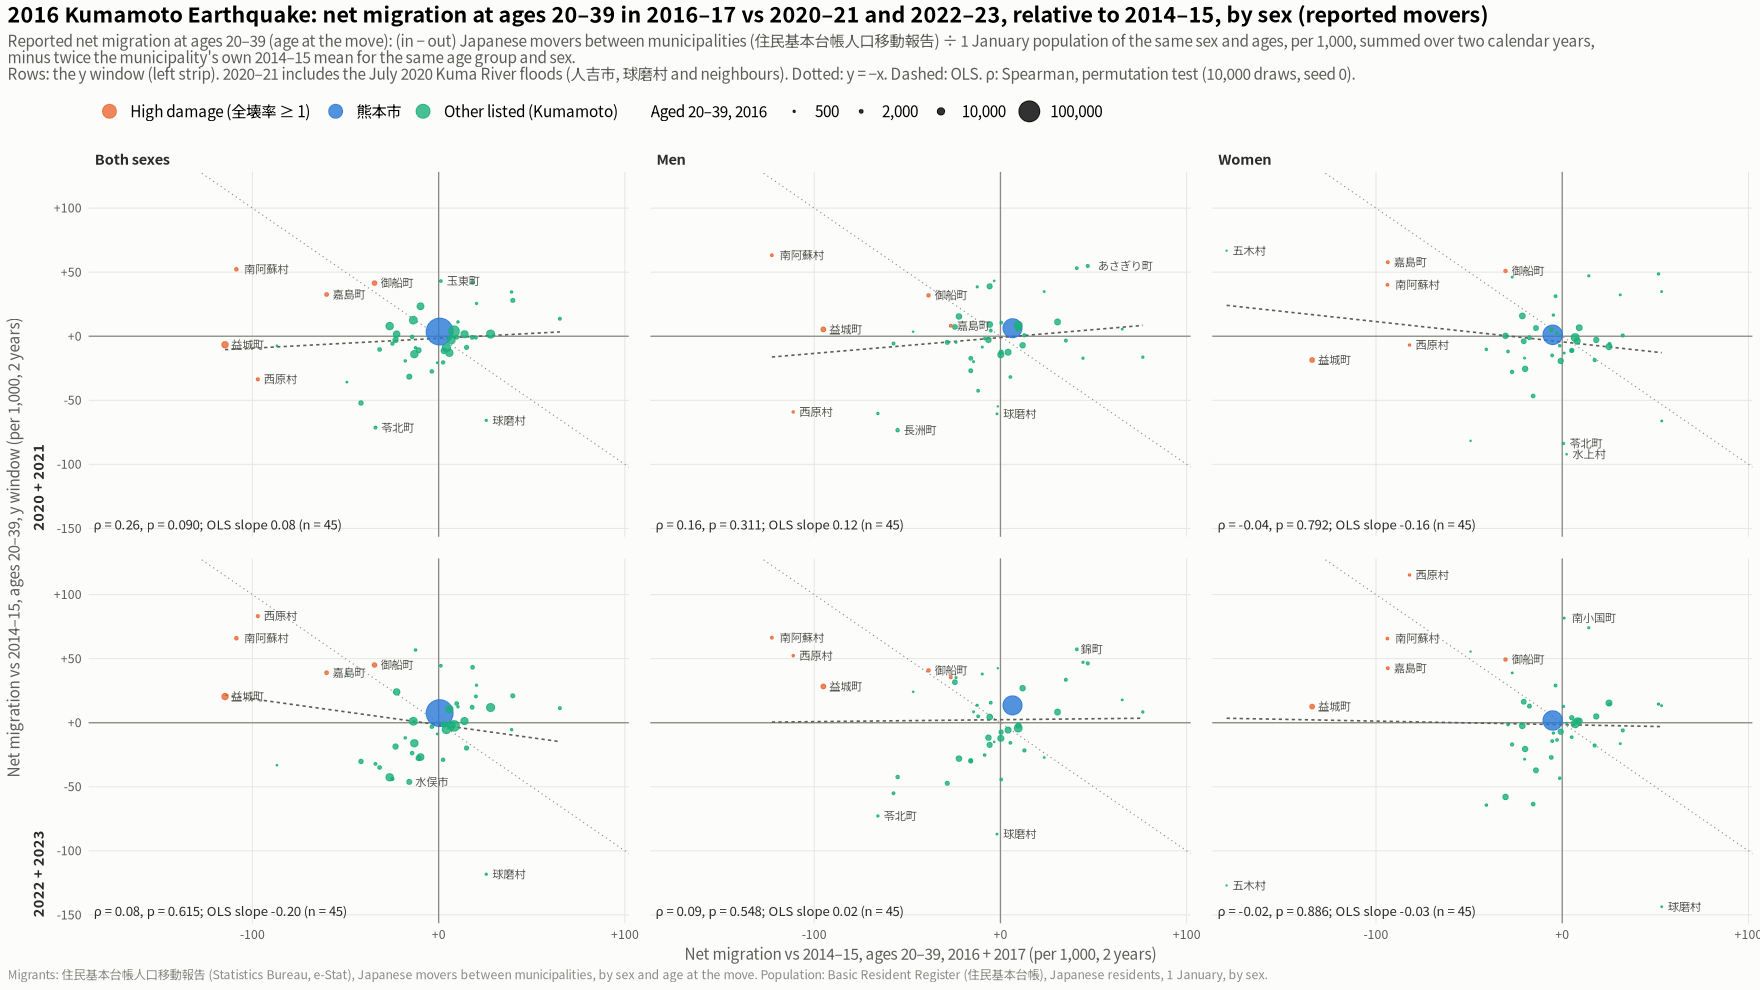

In [9]:
statk <- sck |> group_by(window, sex) |> group_modify(function(d, k) {
  pr <- perm_rho(d$x, d$y)
  tibble(n = nrow(d), rho = pr[["rho"]], p = pr[["p"]], slope = coef(lm(y ~ x, data = d))[[2]])
}) |> ungroup() |>
  mutate(lab = sprintf("ρ = %.2f, p %s; OLS slope %.2f (n = %d)",
                       rho, ifelse(p < 0.001, "< 0.001", sprintf("= %.3f", p)), slope, n))
statk |> select(-lab) |> mutate(across(c(rho, slope), \(v) round(v, 2)), p = signif(p, 2)) |> as.data.frame()

labk <- sck |> group_by(window, sex) |> filter(zenkai_rate >= 1 | rank(x) <= 2 | rank(y) <= 2 | rank(-y) <= 2) |> ungroup()
p4 <- ggplot(sck, aes(x, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_abline(slope = -1, intercept = 0, colour = ink3, linewidth = 0.35, linetype = "13") +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pop2039_2016), alpha = 0.8) +
  geom_text(data = labk, aes(label = short), size = 2.6, colour = ink2, family = jp_font,
            hjust = -0.18, vjust = 0.5, check_overlap = TRUE) +
  geom_text(data = statk, aes(x = -Inf, y = -Inf, label = lab), inherit.aes = FALSE,
            hjust = -0.02, vjust = -0.8, size = 3, colour = ink, family = jp_font) +
  facet_grid(window ~ sex, switch = "y") +
  scale_x_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.03, 0.1))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_colour_manual(values = kgroup_cols, name = NULL) +
  scale_size_area(max_size = 8, breaks = c(500, 2e3, 1e4, 1e5), labels = scales::comma, name = "Aged 20–39, 2016") +
  labs(title = "2016 Kumamoto Earthquake: net migration at ages 20–39 in 2016–17 vs 2020–21 and 2022–23, relative to 2014–15, by sex (reported movers)",
       subtitle = paste0("Reported net migration at ages 20–39 (age at the move): (in − out) Japanese movers between municipalities (住民基本台帳人口移動報告) ÷ 1 January population of the same sex and ages, per 1,000, summed over two calendar years,\n",
                         "minus twice the municipality's own 2014–15 mean for the same age group and sex.\n",
                         "Rows: the y window (left strip). 2020–21 includes the July 2020 Kuma River floods (人吉市, 球磨村 and neighbours). ",
                         "Dotted: y = −x. Dashed: OLS. ρ: Spearman, permutation test (10,000 draws, seed 0)."),
       x = "Net migration vs 2014–15, ages 20–39, 2016 + 2017 (per 1,000, 2 years)",
       y = "Net migration vs 2014–15, ages 20–39, y window (per 1,000, 2 years)", caption = kum_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), strip.placement = "outside") +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p4, "04_kumamoto_2039_net_1617_vs_later_by_sex", width = 20, height = 13)

## Kumamoto socio-economic indicators (5 municipalities)

Sheet `6_社会経済37` covers only the 5 Kumamoto municipalities with 全壊率 ≥ 1, so no correlation or regression is attempted. The table lists their indicators next to the 20–39 outcomes by sex.

In [10]:
se_k <- se_raw |> filter(災害 == "熊本") |>
  transmute(code = 市町村コード, across(all_of(se_vars), \(v) round(as.numeric(v), 1)))
sck |> filter(code %in% se_k$code) |>
  transmute(code, short, zenkai_rate = round(zenkai_rate, 2), window, sex, x = round(x, 1), y = round(y, 1)) |>
  pivot_wider(names_from = c(sex, window), values_from = c(x, y)) |>
  select(code, short, zenkai_rate, any_of(c("x_Men_2020 + 2021", "x_Women_2020 + 2021")),
         starts_with("y_Men"), starts_with("y_Women")) |>
  rename(x_Men = `x_Men_2020 + 2021`, x_Women = `x_Women_2020 + 2021`) |>
  inner_join(se_k, by = "code") |> as.data.frame()

code,short,zenkai_rate,x_Men,x_Women,y_Men_2020 + 2021,y_Men_2022 + 2023,y_Women_2020 + 2021,y_Women_2022 + 2023,市町村内の働く場所÷住民の働き手(%),事業所数/人口千人,通勤流出率,失業率,第1次産業比,第2次産業比,職住自足率（従業地/常住就業者）,納税者1人当たり課税所得(万円),持ち家率,DID人口比
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
43432,西原村,7.25,-111.3,-82.0,-59.1,52.4,-6.9,115.3,97.8,52.5,50.4,3.2,15.8,25.9,108.9,380.4,NA,NA
43433,南阿蘇村,5.98,-122.7,-93.9,63.3,66.4,40.1,65.7,91.6,55.9,33.7,4.4,22.8,17.0,96.6,256.6,NA,NA
43441,御船町,2.51,-38.6,-30.5,31.9,40.9,50.9,49.3,72.9,42.5,55.8,4.2,10.5,25.1,81.3,252.3,68.0,NA
43442,嘉島町,2.54,-26.6,-93.7,8.2,35.5,57.8,42.6,163.1,69.8,62.2,4.5,8.4,21.6,151.2,296.9,NA,NA
43443,益城町,8.75,-95.1,-134.3,5.3,28.3,-18.6,12.6,97.3,32.3,58.3,5.3,8.6,22.2,96.8,274.6,53.7,67.3


# Figures 5–7: 全壊率 and the correlation matrix, by sex

The 20–39 by-sex counterparts of the all-ages figures used in the presentation:
- **Figure 5:** 5r figure 25 (Tohoku: 全壊率 vs net migration over the intervals starting 2010 + 2011, raw and relative to 2006–09). The statistics exclude the evacuation-order municipalities.
- **Figure 6:** 3r figure 13 (Kumamoto: 全壊率 vs net migration in 2016, raw and relative to 2014–15), from the reported movers. All 45 municipalities.
- **Figure 7:** 5r figure 34 (Spearman correlations among the 2013–14 outcome, 全壊率, the 2010–11 loss and the socio-economic indicators; Tohoku 全壊率 ≥ 1, n = 30), for men and women.

                               measure        sex   n   rho      p slope
1 Net migration, intervals 2010 + 2011 Both sexes 113 -0.26 0.0059 -4.70
2 Net migration, intervals 2010 + 2011        Men 113 -0.26 0.0053 -4.37
3 Net migration, intervals 2010 + 2011      Women 113 -0.24 0.0120 -5.08
4  Minus twice the 2006–09 annual mean Both sexes 113 -0.45 0.0001 -4.71
5  Minus twice the 2006–09 annual mean        Men 113 -0.43 0.0001 -4.38
6  Minus twice the 2006–09 annual mean      Women 113 -0.36 0.0001 -5.09
                      measure        sex  n   rho      p  slope
1         Net migration, 2016 Both sexes 45 -0.27 0.0750  -8.30
2         Net migration, 2016        Men 45 -0.29 0.0490  -8.66
3         Net migration, 2016      Women 45 -0.19 0.2200  -7.89
4 2016 minus the 2014–15 mean Both sexes 45 -0.46 0.0019 -11.15
5 2016 minus the 2014–15 mean        Men 45 -0.43 0.0035 -11.05
6 2016 minus the 2014–15 mean      Women 45 -0.39 0.0091 -11.20


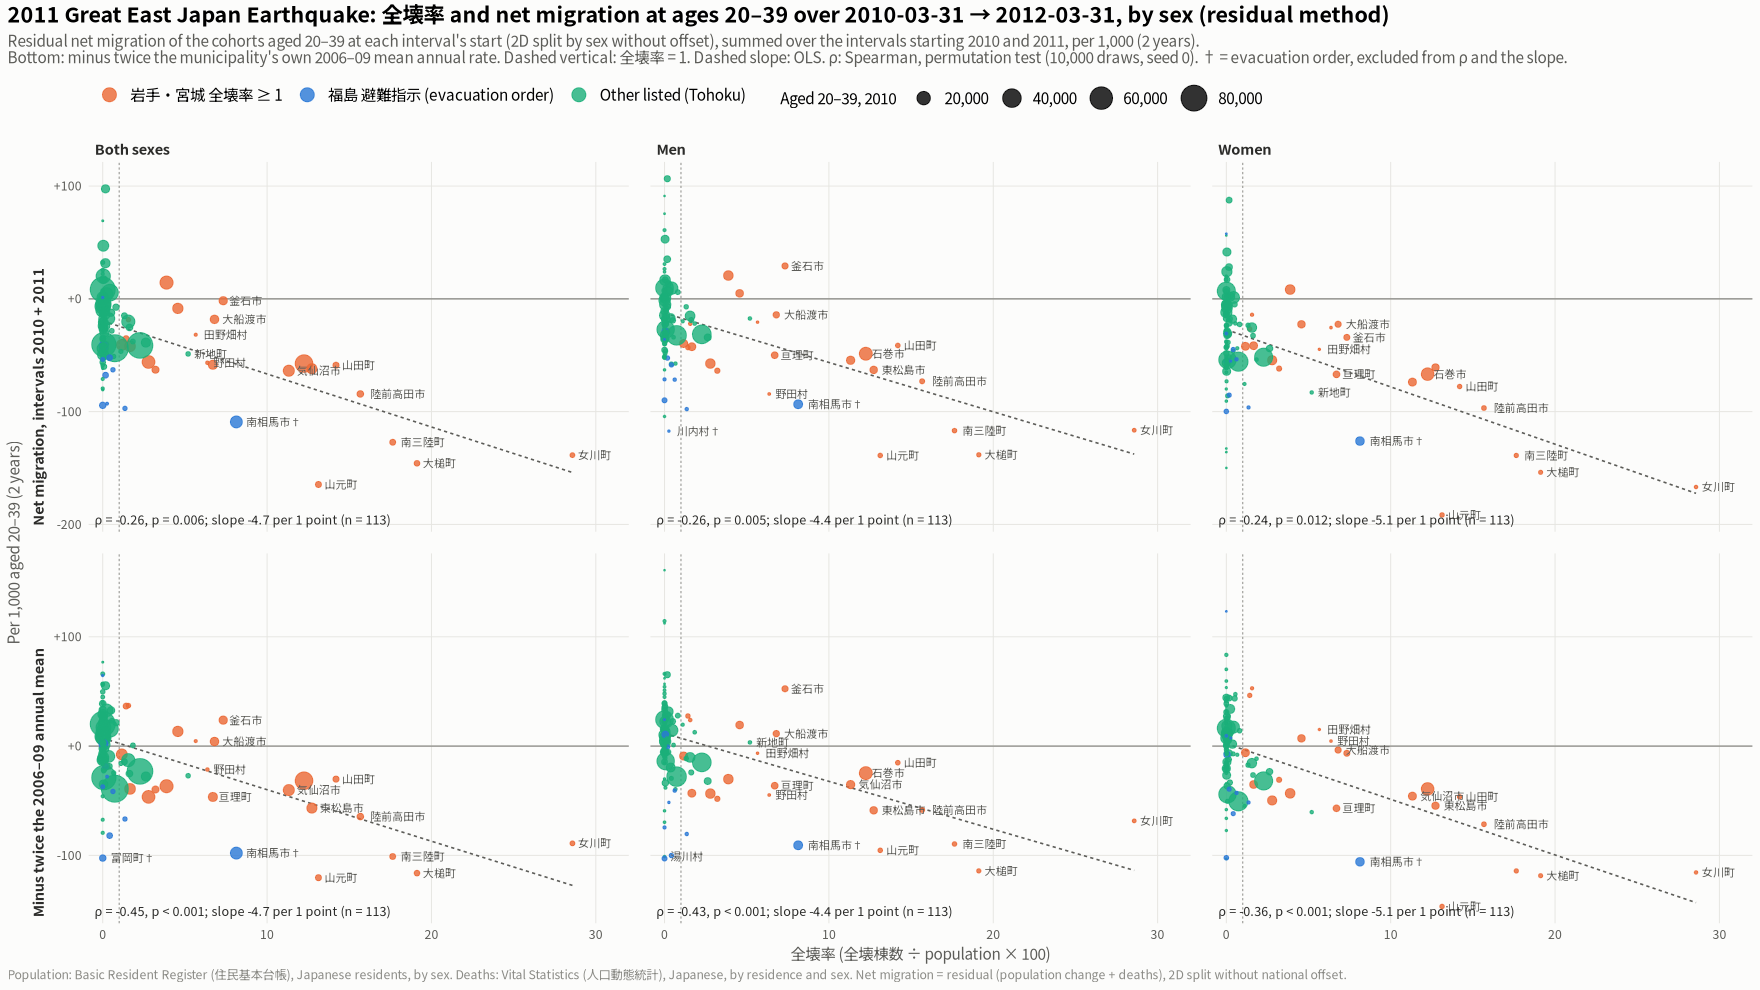

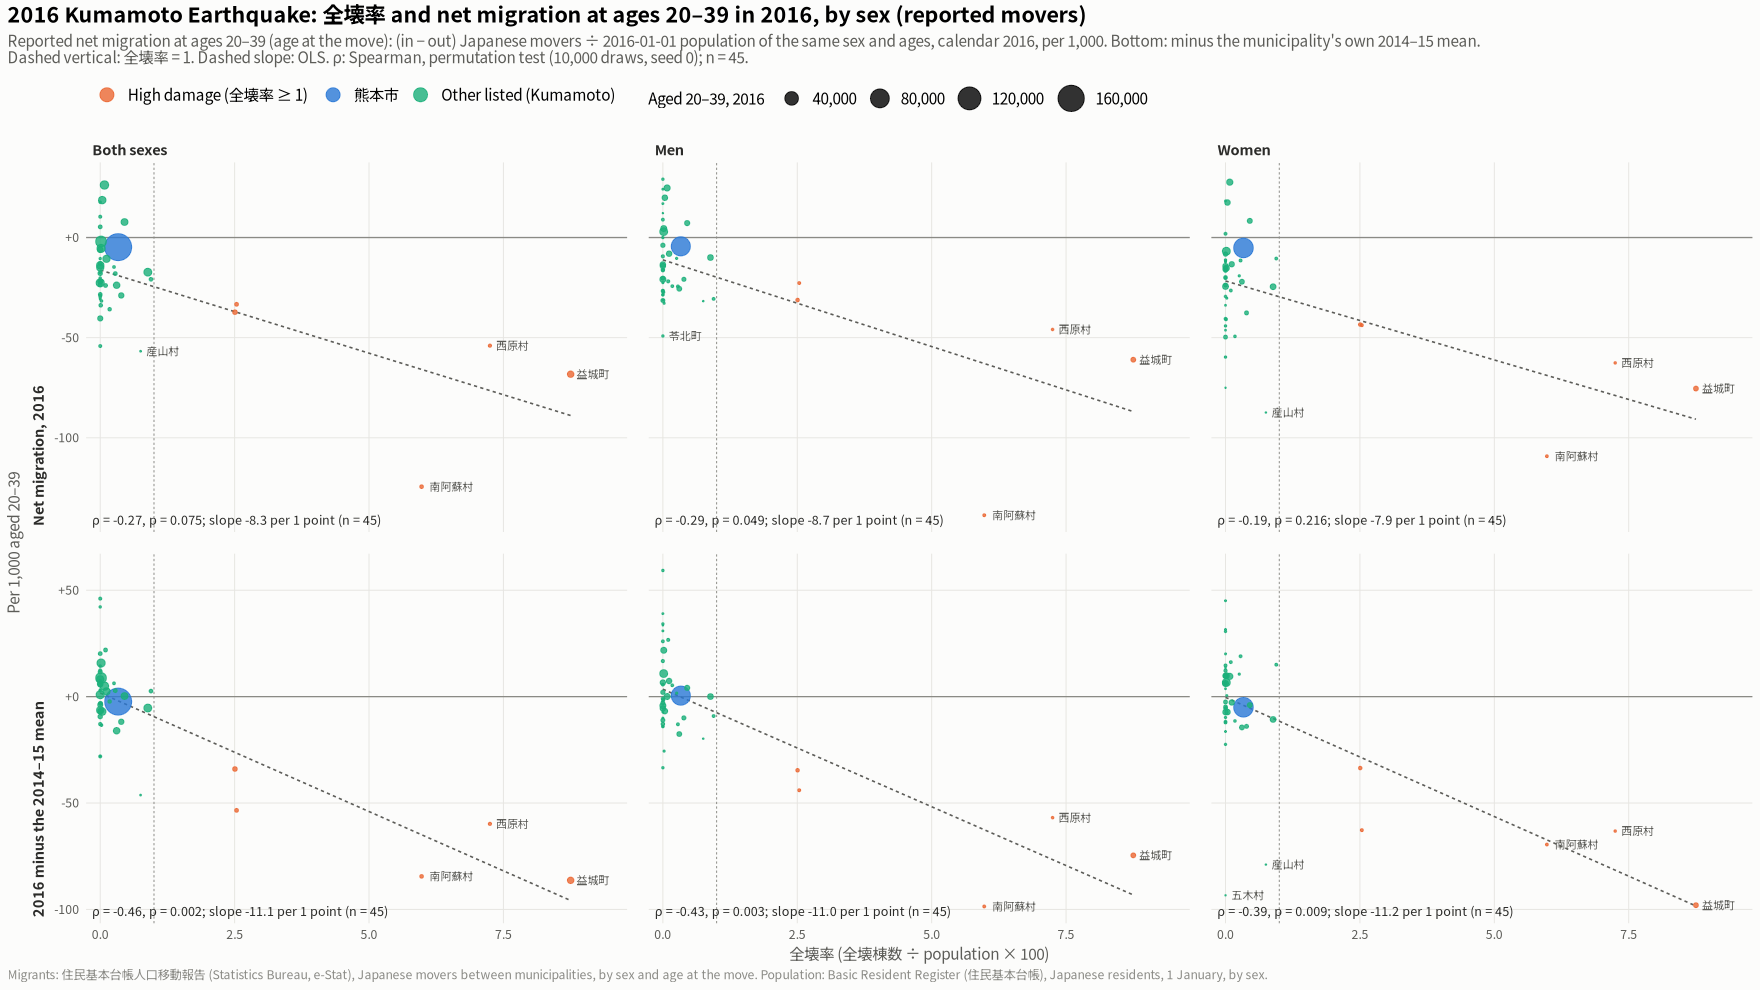

In [11]:
zen_plot <- function(d, title, sub, xlab, ylab, size_lab, fname, col_vals, height = 10, caption = src_note) {
  st <- d |> filter(!excluded) |> group_by(measure, sex) |> group_modify(function(dd, k) {
    pr <- perm_rho(dd$zenkai_rate, dd$v)
    tibble(n = nrow(dd), rho = pr[["rho"]], p = pr[["p"]], slope = coef(lm(v ~ zenkai_rate, data = dd))[[2]])
  }) |> ungroup() |>
    mutate(lab = sprintf("ρ = %.2f, p %s; slope %.1f per 1 point (n = %d)",
                         rho, ifelse(p < 0.001, "< 0.001", sprintf("= %.3f", p)), slope, n))
  print(st |> select(-lab) |> mutate(across(c(rho, slope), \(v) round(v, 2)), p = signif(p, 2)) |> as.data.frame())
  lab <- d |> group_by(measure, sex) |> filter(zenkai_rate >= 5 | rank(v) <= 3) |> ungroup()
  p <- ggplot(d, aes(zenkai_rate, v)) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_vline(xintercept = 1, colour = ink3, linewidth = 0.3, linetype = "22") +
    geom_smooth(data = d |> filter(!excluded), method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
    geom_point(aes(colour = group, size = size), alpha = 0.8) +
    geom_text(data = lab, aes(label = short_lab), size = 2.5, colour = ink2, family = jp_font, hjust = -0.18, check_overlap = TRUE) +
    geom_text(data = st, aes(x = -Inf, y = -Inf, label = lab), inherit.aes = FALSE, hjust = -0.02, vjust = -0.8,
              size = 2.9, colour = ink, family = jp_font) +
    facet_grid(measure ~ sex, scales = "free_y", switch = "y") +
    scale_x_continuous(expand = expansion(mult = c(0.03, 0.12))) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    scale_colour_manual(values = col_vals, name = NULL) +
    scale_size_area(max_size = 8, labels = scales::comma, name = size_lab) +
    labs(title = title, subtitle = sub, x = xlab, y = ylab, caption = caption) +
    base_theme() +
    theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), strip.placement = "outside") +
    guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
  show_save(p, fname, width = 20, height = height)
}

# Figure 5: Tohoku, 全壊率 vs ages 20-39 net migration over the intervals 2010 + 2011
m5 <- c(raw = "Net migration, intervals 2010 + 2011", rel = "Minus twice the 2006–09 annual mean")
d5 <- y9 |> group_by(code, sex) |>
  summarise(raw = sum(cum[start %in% 2010:2011]), rel = raw - 2 * first(base), size = P0[start == 2010], .groups = "drop") |>
  pivot_longer(c(raw, rel), names_to = "measure", values_to = "v") |>
  inner_join(study, by = "code") |>
  mutate(measure = factor(m5[measure], levels = m5), sex = factor(sex, levels = sex_levels),
         group = factor(group, levels = group_levels), excluded = evacuation)
zen_plot(d5, "2011 Great East Japan Earthquake: 全壊率 and net migration at ages 20–39 over 2010-03-31 → 2012-03-31, by sex (residual method)",
         paste0("Residual net migration of the cohorts aged 20–39 at each interval's start (2D split by sex without offset), summed over the intervals starting 2010 and 2011, ",
                "per 1,000 (2 years).\nBottom: minus twice the municipality's own 2006–09 mean annual rate. Dashed vertical: 全壊率 = 1. Dashed slope: OLS. ",
                "ρ: Spearman, permutation test (10,000 draws, seed 0). † = evacuation order, excluded from ρ and the slope."),
         "全壊率 (全壊棟数 ÷ population × 100)", "Per 1,000 aged 20–39 (2 years)", "Aged 20–39, 2010",
         "05_tohoku_zenkai_vs_2039_net_2010_11_by_sex", group_cols)

# Figure 6: Kumamoto, 全壊率 vs ages 20-39 net migration in 2016
m6 <- c(raw = "Net migration, 2016", rel = "2016 minus the 2014–15 mean")
d6 <- yk |> group_by(code, sex) |>
  summarise(raw = cum[start == 2016], rel = raw - first(base), size = P0[start == 2016], .groups = "drop") |>
  pivot_longer(c(raw, rel), names_to = "measure", values_to = "v") |>
  inner_join(kstudy |> mutate(short_lab = short), by = "code") |>
  mutate(measure = factor(m6[measure], levels = m6), sex = factor(sex, levels = sex_levels),
         group = factor(group, levels = kgroup_levels), excluded = FALSE)
zen_plot(d6, "2016 Kumamoto Earthquake: 全壊率 and net migration at ages 20–39 in 2016, by sex (reported movers)",
         paste0("Reported net migration at ages 20–39 (age at the move): (in − out) Japanese movers ÷ 2016-01-01 population of the same sex and ages, calendar 2016, per 1,000. ",
                "Bottom: minus the municipality's own 2014–15 mean.\nDashed vertical: 全壊率 = 1. Dashed slope: OLS. ρ: Spearman, permutation test (10,000 draws, seed 0); n = 45."),
         "全壊率 (全壊棟数 ÷ population × 100)", "Per 1,000 aged 20–39", "Aged 20–39, 2016",
         "06_kumamoto_zenkai_vs_2039_net_2016_by_sex", kgroup_cols, caption = kum_note)

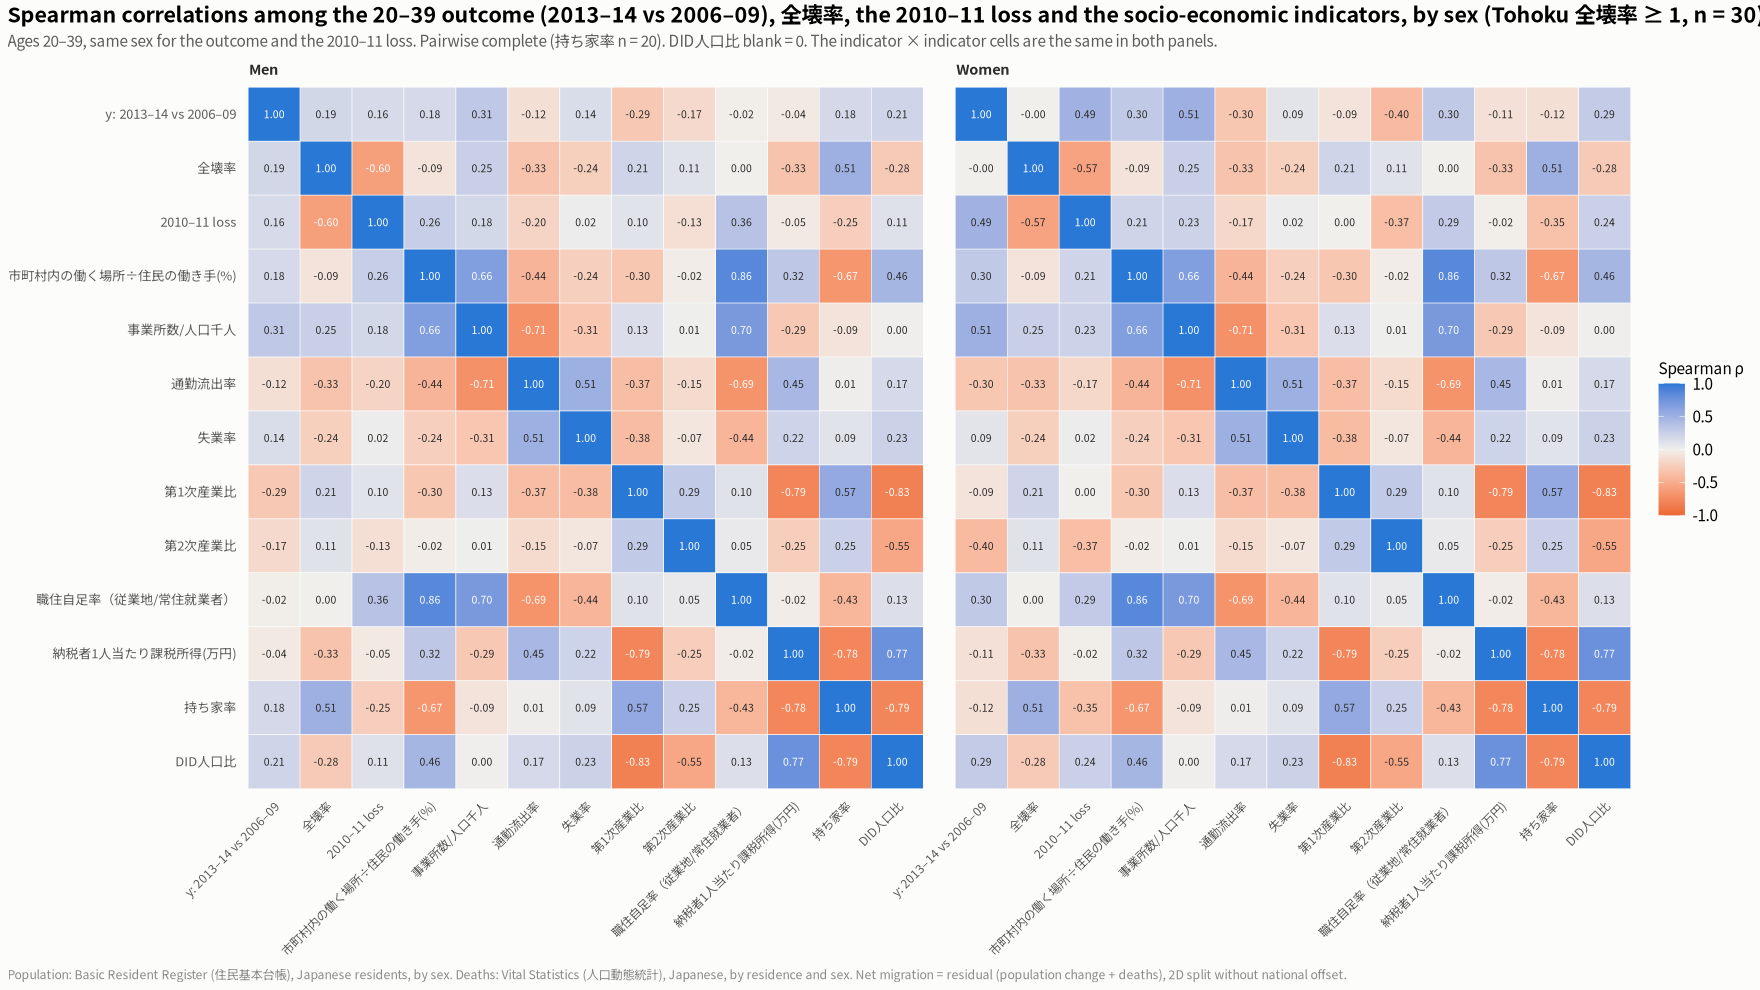

In [12]:
# Figure 7: Spearman correlations among the variables, men and women (Tohoku 全壊率 ≥ 1, n = 30)
cv <- c("y: 2013–14 vs 2006–09" = "y", "全壊率" = "zenkai_rate", "2010–11 loss" = loss_var, setNames(se_vars, se_vars))
cm7 <- bind_rows(lapply(c("Men", "Women"), function(s) {
  cm <- d9 |> filter(sex == s) |> select(all_of(unname(cv))) |> cor(method = "spearman", use = "pairwise.complete.obs")
  dimnames(cm) <- list(names(cv), names(cv))
  as_tibble(cm, rownames = "a") |> pivot_longer(-a, names_to = "b", values_to = "rho") |> mutate(sex = s)
})) |> mutate(a = factor(a, levels = names(cv)), b = factor(b, levels = rev(names(cv))))
p7 <- ggplot(cm7, aes(a, b, fill = rho)) +
  geom_tile(colour = surface) +
  geom_text(aes(label = sprintf("%.2f", rho), colour = abs(rho) > 0.6), size = 2.4, family = jp_font) +
  facet_wrap(~sex, nrow = 1) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = ink), guide = "none") +
  scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", limits = c(-1, 1), name = "Spearman ρ") +
  labs(title = "Spearman correlations among the 20–39 outcome (2013–14 vs 2006–09), 全壊率, the 2010–11 loss and the socio-economic indicators, by sex (Tohoku 全壊率 ≥ 1, n = 30)",
       subtitle = "Ages 20–39, same sex for the outcome and the 2010–11 loss. Pairwise complete (持ち家率 n = 20). DID人口比 blank = 0. The indicator × indicator cells are the same in both panels.",
       x = NULL, y = NULL, caption = src_note) +
  base_theme() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1, size = 8), axis.text.y = element_text(size = 8.5),
        panel.grid.major.y = element_blank(), legend.position = "right")
show_save(p7, "07_tohoku_2039_socioecon_correlations_by_sex", width = 22, height = 10.5)

# Figures 8–17: age profile, stacked change, heatmaps, by sex (Tohoku and Kumamoto)

The all-ages views of 5r redone by sex. Tohoku uses the sex-specific residual of this notebook (2D split without offset, intervals 2006–2025). Kumamoto uses the **reported movers** by sex (2014–2025, age at the move, published bands). Groups are as in 5r: Tohoku 岩手・宮城 全壊率 ≥ 1, 福島 避難指示 and other listed; Kumamoto high damage, 熊本市 and other listed.

- **Figures 8–9, age profile** (5r figures 4–5).
  - Net migration per 1,000 of the same sex and 5-year band per year, by period: before the quake, the quake interval, after years 1–2, after years 3–5, and after years 6+ (to 2025).
- **Figures 10–11, diverging stacked bars** (5r figures 16–17, ages 50+ combined).
  - Each band's net migration ÷ the group's all-ages population of that sex, minus its pre-quake mean (Tohoku 2006–09, Kumamoto 2014–15).
  - Youngest band next to 0. The segments add up to the dashed all-ages change.
- **Figures 12–13, heatmap by group** (5r figure 22).
  - Each band's own rate minus its pre-quake mean, per 1,000 of the band.
- **Figures 14–17, heatmap by municipality** (5r figure 24), one figure per disaster and sex.
  - Each municipality against its own pre-quake mean.

**Read with care**
- **Older ages, Tohoku:** without the national offset, ages 55–79 carry the 1944–50 band-edge artefact (stripes). The Kumamoto reported data have no such artefact.
- **Small municipalities:** one sex's band can be a few dozen people, so single cells are noisy.
- **Tohoku 2012/2013:** these intervals are affected by the reference-date issue (`doc/caution.md` §1).

In [13]:
bands_c <- c(paste0(seq(0, 75, 5), "–", seq(4, 79, 5)), "80+")
band_of <- function(a) factor(ifelse(a >= 80, "80+", paste0(a %/% 5 * 5, "–", a %/% 5 * 5 + 4)), levels = bands_c)
bands50 <- c(bands_c[1:10], "50+")
band50_of <- function(a) factor(ifelse(a >= 50, "50+", paste0(a %/% 5 * 5, "–", a %/% 5 * 5 + 4)), levels = bands50)
cols50 <- setNames(c("#7fd3a7", "#1baf7a", "#0b6b47", "#f6b26b", "#eb6834", "#c43d1c", "#8a1f0a", "#e8a0b4",
                     "#9cc6f2", "#2a78d6", "#8f86a8"), bands50)
periods9 <- c("Before", "Quake interval", "After, years 1–2", "After, years 3–5", "After, years 6+")
period_cols9 <- setNames(c("#8a8a85", "#eb6834", "#2a78d6", "#0d366b", "#9474c0"), periods9)
sexes2 <- c("Men", "Women")

ev9 <- list(
  tohoku = list(title = "2011 Great East Japan Earthquake", res = res9, base = 2006:2009, q = 2010, starts = 2006:2025,
                grp = study |> select(code, group, short_lab, zenkai_rate), levels = group_levels,
                base_lab = "2006–09", method = "residual", shade = TRUE, caption = src_note,
                age_lab = "Age at the start of the interval", x_lab = "Interval starting count",
                desc = "Net migration = cohort population change + deaths (2D split by sex without national offset), age at the interval start",
                note = "x = the interval's starting count (31 March to 2012, then 1 January). Quake interval = 2010-03-31 → 2011-03-31 (ends 20 days after the quake). 2012/2013: reference-date issue (doc/caution.md §1)."),
  kumamoto = list(title = "2016 Kumamoto Earthquake", res = rep_k, base = 2014:2015, q = 2016, starts = 2014:2025,
                  grp = kstudy |> transmute(code, group, short_lab = short, zenkai_rate), levels = kgroup_levels,
                  base_lab = "2014–15", method = "reported movers", shade = FALSE, caption = kum_note,
                  age_lab = "Age at the move", x_lab = "Calendar year",
                  desc = "Net migration = (in − out) Japanese movers between municipalities (住民基本台帳人口移動報告) ÷ 1 January population of the same sex and band, age at the move",
                  note = "x = calendar year. Quake year = 2016. 2020: Kuma River floods (Other listed)."))
prep9 <- function(e) {
  ev <- ev9[[e]]
  ev$res |> filter(start %in% ev$starts, sex %in% sexes2) |>
    inner_join(ev$grp, by = "code") |>
    mutate(group = factor(group, levels = ev$levels), sex = factor(sex, levels = sexes2))
}
d9e <- lapply(setNames(names(ev9), names(ev9)), prep9)

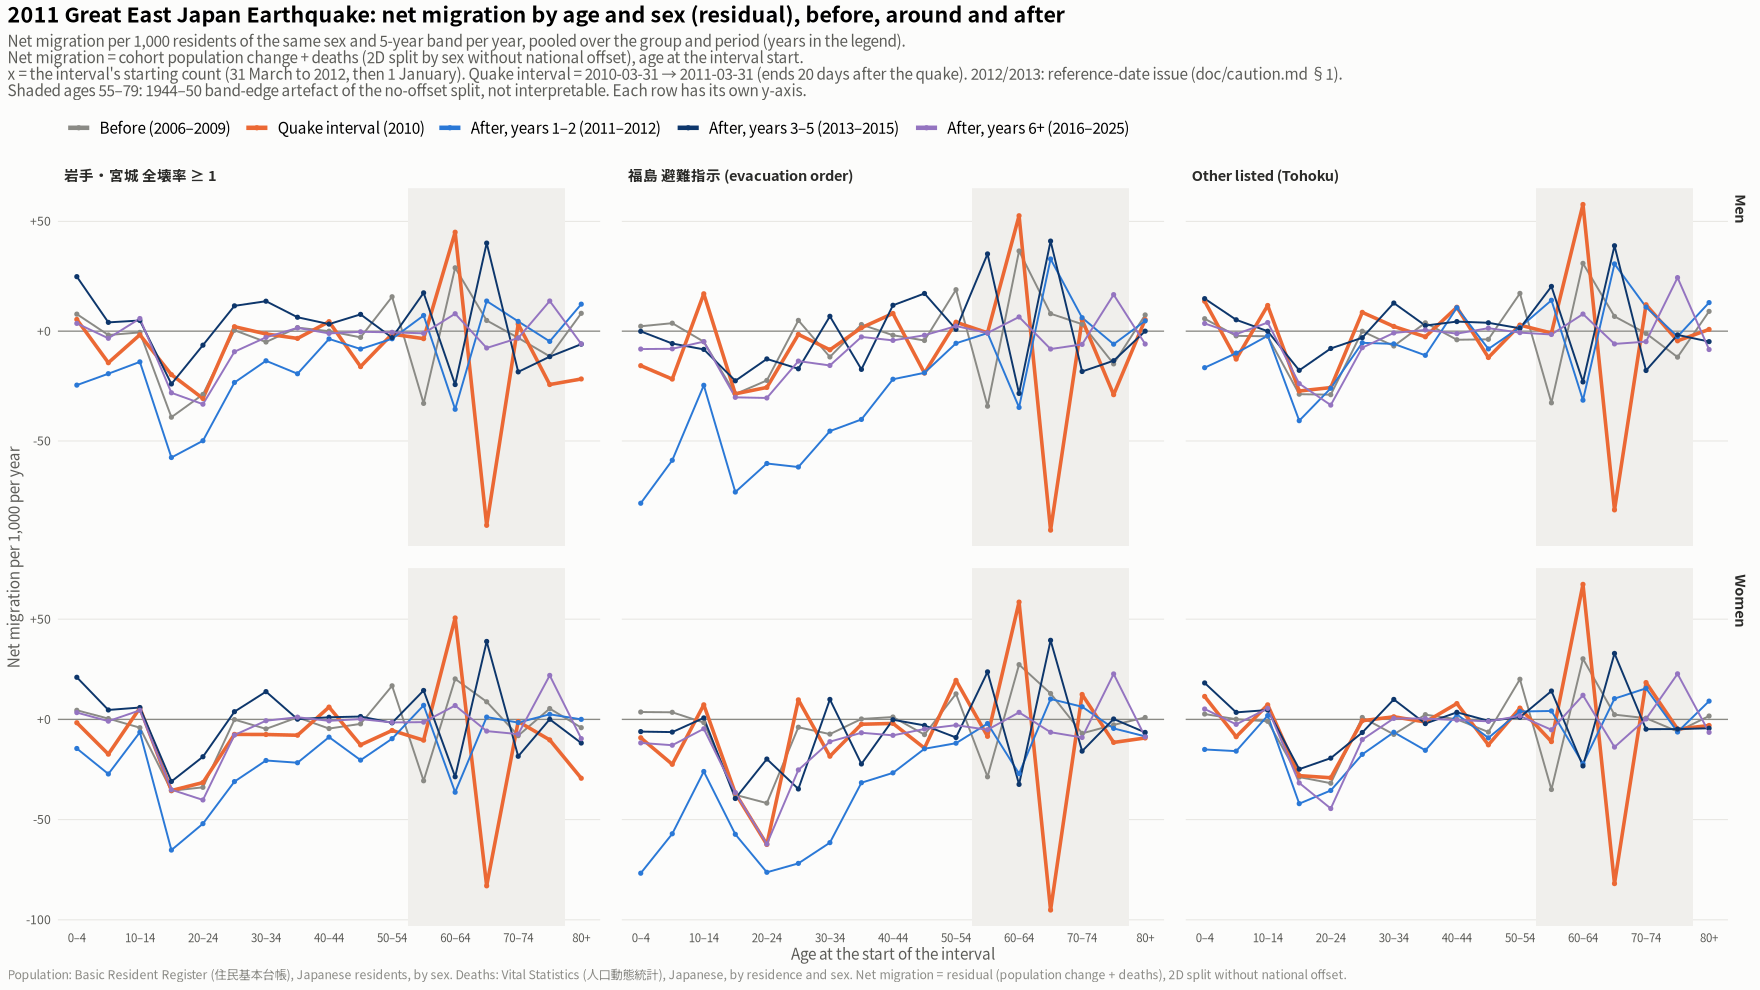

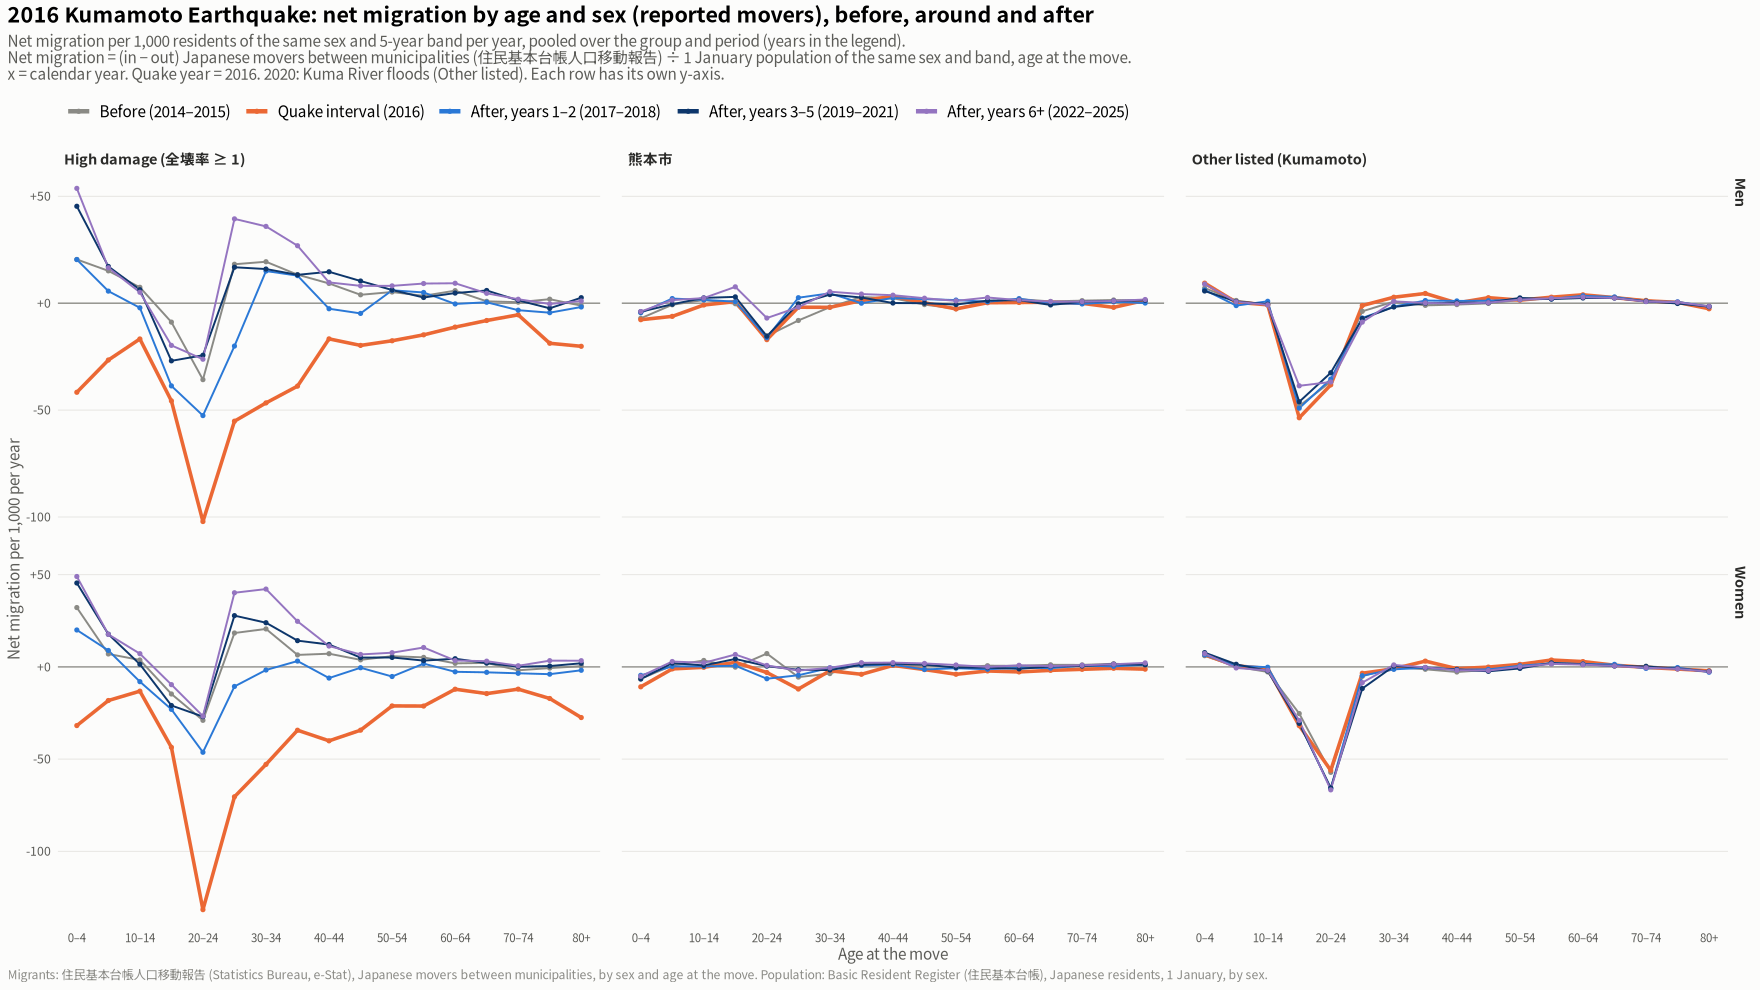

In [14]:
# Figures 8-9: age profile by period, rows = sex
plot_profile9 <- function(e) {
  ev <- ev9[[e]]
  dd <- d9e[[e]] |>
    mutate(period = factor(case_when(start < ev$q ~ periods9[1], start == ev$q ~ periods9[2], start <= ev$q + 2 ~ periods9[3],
                                     start <= ev$q + 5 ~ periods9[4], TRUE ~ periods9[5]), levels = periods9),
           band = band_of(age)) |>
    group_by(sex, group, period, band) |>
    summarise(rate = 1000 * sum(NM) / sum(P0 * span), .groups = "drop")
  yrs <- dd |> distinct(period) |> pull(period)
  rng <- sapply(periods9, function(p) {
    s <- ev$starts[case_when(ev$starts < ev$q ~ periods9[1], ev$starts == ev$q ~ periods9[2], ev$starts <= ev$q + 2 ~ periods9[3],
                             ev$starts <= ev$q + 5 ~ periods9[4], TRUE ~ periods9[5]) == p]
    if (length(s) == 1) as.character(s) else paste0(min(s), "–", max(s))
  })
  ggplot(dd, aes(band, rate, colour = period, group = period)) +
    (if (ev$shade) annotate("rect", xmin = 11.5, xmax = 16.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") else NULL) +
    geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
    geom_line(aes(linewidth = period == periods9[2])) +
    geom_point(size = 1) +
    facet_grid(sex ~ group, scales = "free_y") +
    scale_colour_manual(values = period_cols9, labels = paste0(periods9, " (", rng, ")"), name = NULL) +
    scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1.1), guide = "none") +
    scale_x_discrete(labels = function(b) ifelse(seq_along(b) %% 2 == 1, b, "")) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(ev$title, ": net migration by age and sex (", ev$method, "), before, around and after"),
         subtitle = paste0("Net migration per 1,000 residents of the same sex and 5-year band per year, pooled over the group and period (years in the legend).\n", ev$desc, ".\n", ev$note,
                           if (ev$shade) "\nShaded ages 55–79: 1944–50 band-edge artefact of the no-offset split, not interpretable." else "", " Each row has its own y-axis."),
         x = ev$age_lab, y = "Net migration per 1,000 per year", caption = ev$caption) +
    base_theme() +
    theme(axis.text.x = element_text(size = 7.5)) +
    guides(colour = guide_legend(override.aes = list(linewidth = 1.4)))
}
show_save(plot_profile9("tohoku"), "08_tohoku_age_profile_by_sex", width = 18, height = 10)
show_save(plot_profile9("kumamoto"), "09_kumamoto_age_profile_by_sex", width = 18, height = 10)

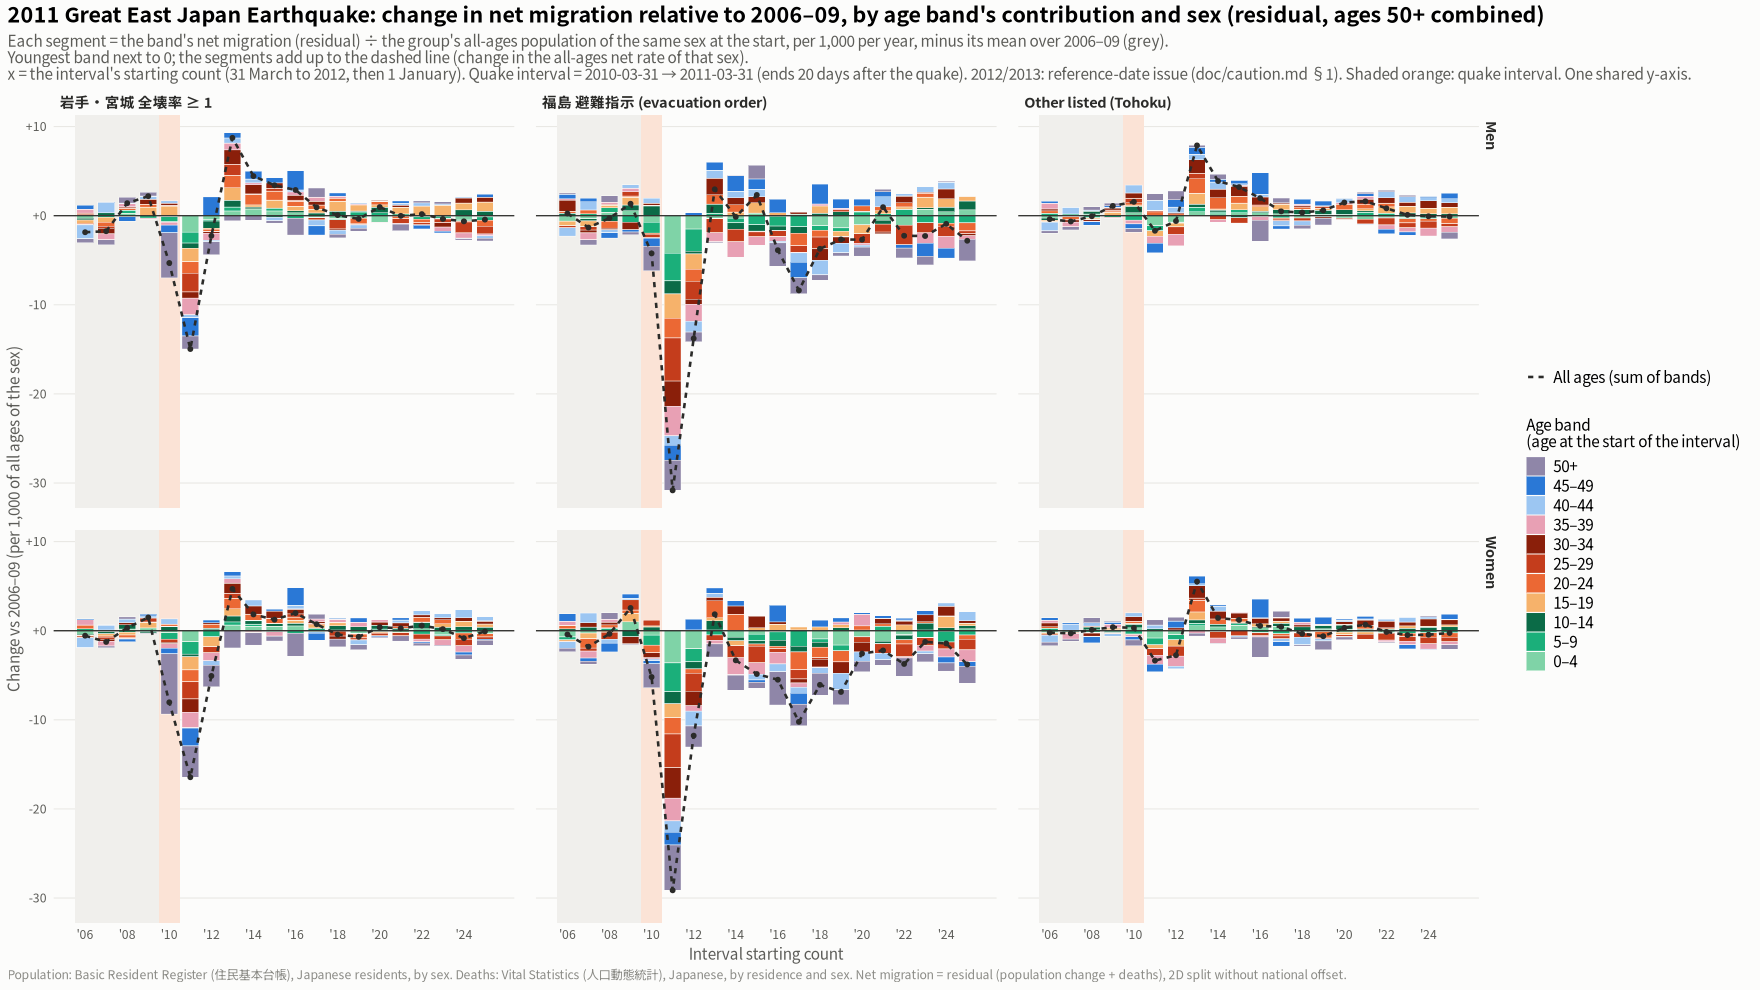

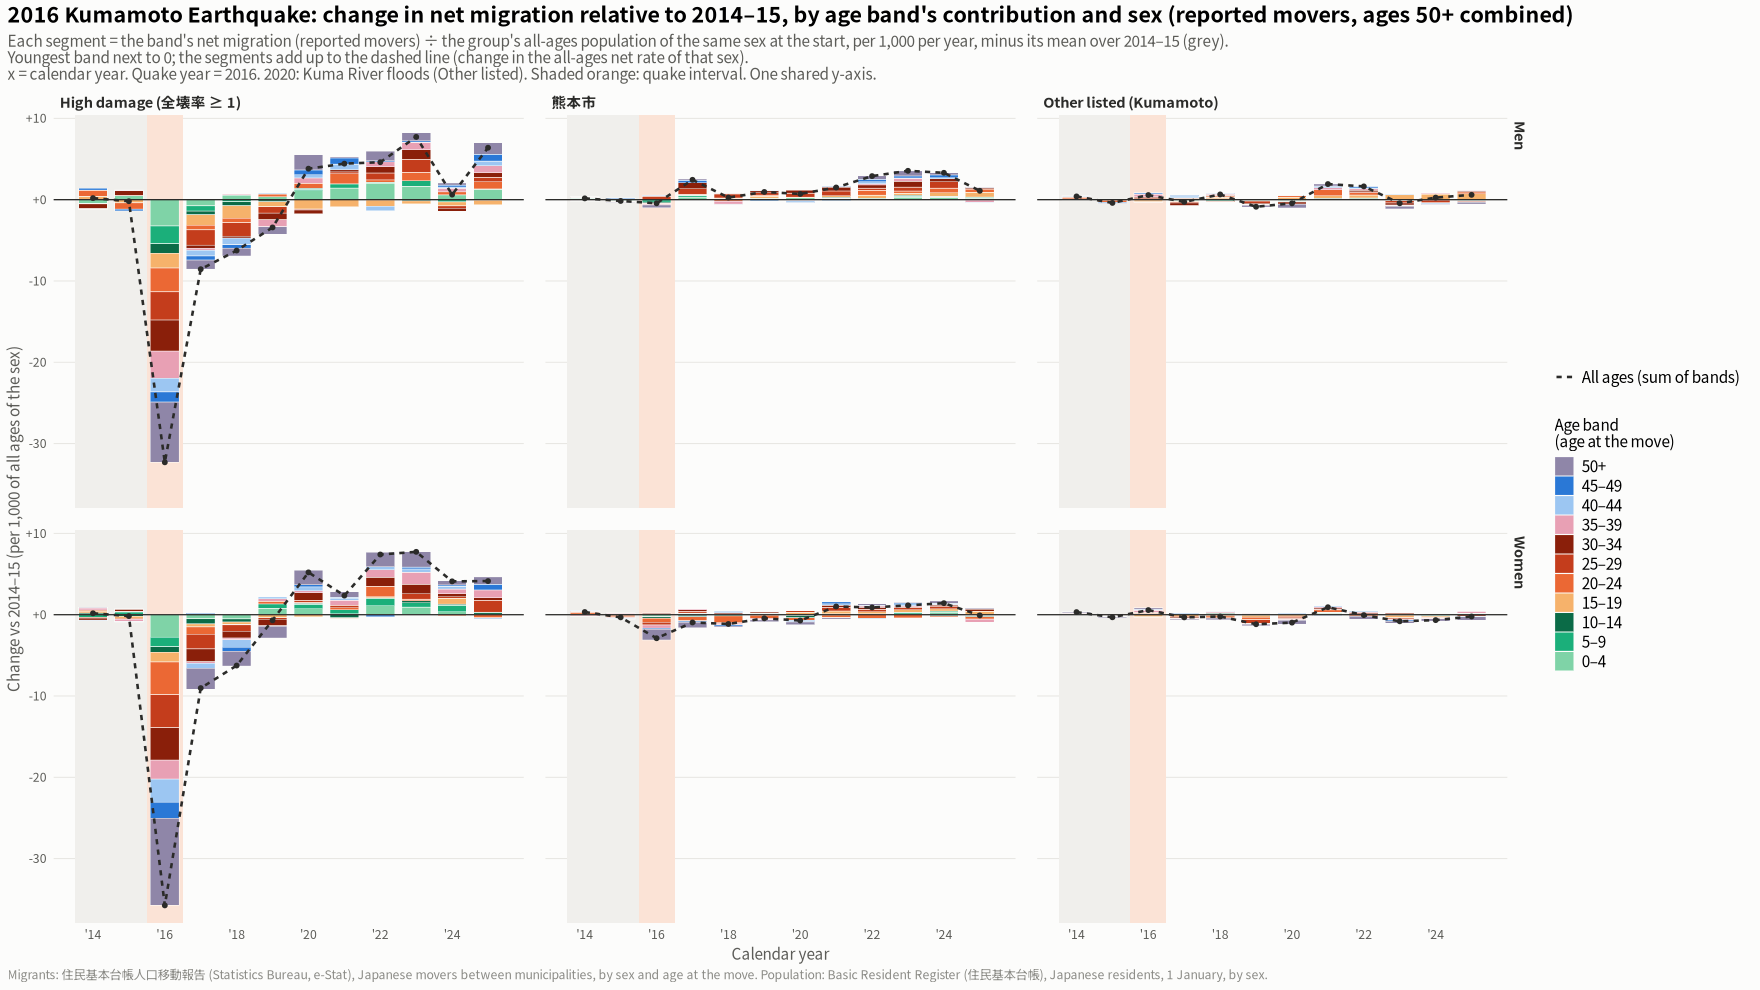

In [15]:
# Figures 10-11: diverging stacked change by band's contribution (ages 50+ combined), rows = sex
plot_stacked9 <- function(e) {
  ev <- ev9[[e]]
  contrib <- d9e[[e]] |> mutate(band = band50_of(age)) |>
    group_by(sex, group, start, span, band) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
    group_by(sex, group, start) |> mutate(contrib = 1000 * NM / (sum(P0) * span)) |>
    group_by(sex, group, band) |> mutate(change = contrib - mean(contrib[start %in% ev$base])) |> ungroup()
  tot <- contrib |> group_by(sex, group, start) |> summarise(change = sum(change), .groups = "drop")
  chk <- d9e[[e]] |> group_by(sex, group, start, span) |>
    summarise(rate = 1000 * sum(NM) / (sum(P0) * first(span)), .groups = "drop") |>
    group_by(sex, group) |> mutate(ch = rate - mean(rate[start %in% ev$base])) |> ungroup() |>
    inner_join(tot, by = c("sex", "group", "start"))
  stopifnot(max(abs(chk$ch - chk$change)) < 1e-9)
  ggplot(contrib, aes(start, change)) +
    annotate("rect", xmin = min(ev$base) - 0.5, xmax = max(ev$base) + 0.5, ymin = -Inf, ymax = Inf, fill = "#f0efec") +
    annotate("rect", xmin = ev$q - 0.5, xmax = ev$q + 0.5, ymin = -Inf, ymax = Inf, fill = "#fbe3d6") +
    geom_col(aes(fill = band), width = 0.8, colour = surface, linewidth = 0.15, position = position_stack(reverse = TRUE)) +
    geom_hline(yintercept = 0, colour = ink, linewidth = 0.4) +
    geom_line(data = tot, aes(linetype = "All ages (sum of bands)"), colour = ink, linewidth = 0.8) +
    geom_point(data = tot, colour = ink, size = 1.2) +
    facet_grid(sex ~ group) +
    scale_fill_manual(values = cols50, name = paste0("Age band\n(", tolower(ev$age_lab), ")"), guide = guide_legend(ncol = 1, reverse = TRUE, order = 2)) +
    scale_linetype_manual(values = c("All ages (sum of bands)" = "22"), name = NULL,
                          guide = guide_legend(order = 1, override.aes = list(linewidth = 0.8))) +
    scale_x_continuous(breaks = seq(min(ev$starts) + (min(ev$starts) %% 2), max(ev$starts), 2), labels = function(v) paste0("'", substr(v, 3, 4))) +
    scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
    labs(title = paste0(ev$title, ": change in net migration relative to ", ev$base_lab, ", by age band's contribution and sex (", ev$method, ", ages 50+ combined)"),
         subtitle = paste0("Each segment = the band's net migration (", ev$method, ") ÷ the group's all-ages population of the same sex at the start, per 1,000 per year, ",
                           "minus its mean over ", ev$base_lab, " (grey).\nYoungest band next to 0; the segments add up to the dashed line (change in the all-ages net rate of that sex).\n",
                           ev$note, " Shaded orange: quake interval. One shared y-axis."),
         x = ev$x_lab, y = paste0("Change vs ", ev$base_lab, " (per 1,000 of all ages of the sex)"), caption = ev$caption) +
    base_theme() +
    theme(legend.position = "right", legend.justification = "center", legend.key.size = unit(0.45, "cm"))
}
show_save(plot_stacked9("tohoku"), "10_tohoku_band_change_stacked_by_sex", width = 20, height = 10)
show_save(plot_stacked9("kumamoto"), "11_kumamoto_band_change_stacked_by_sex", width = 18, height = 10)

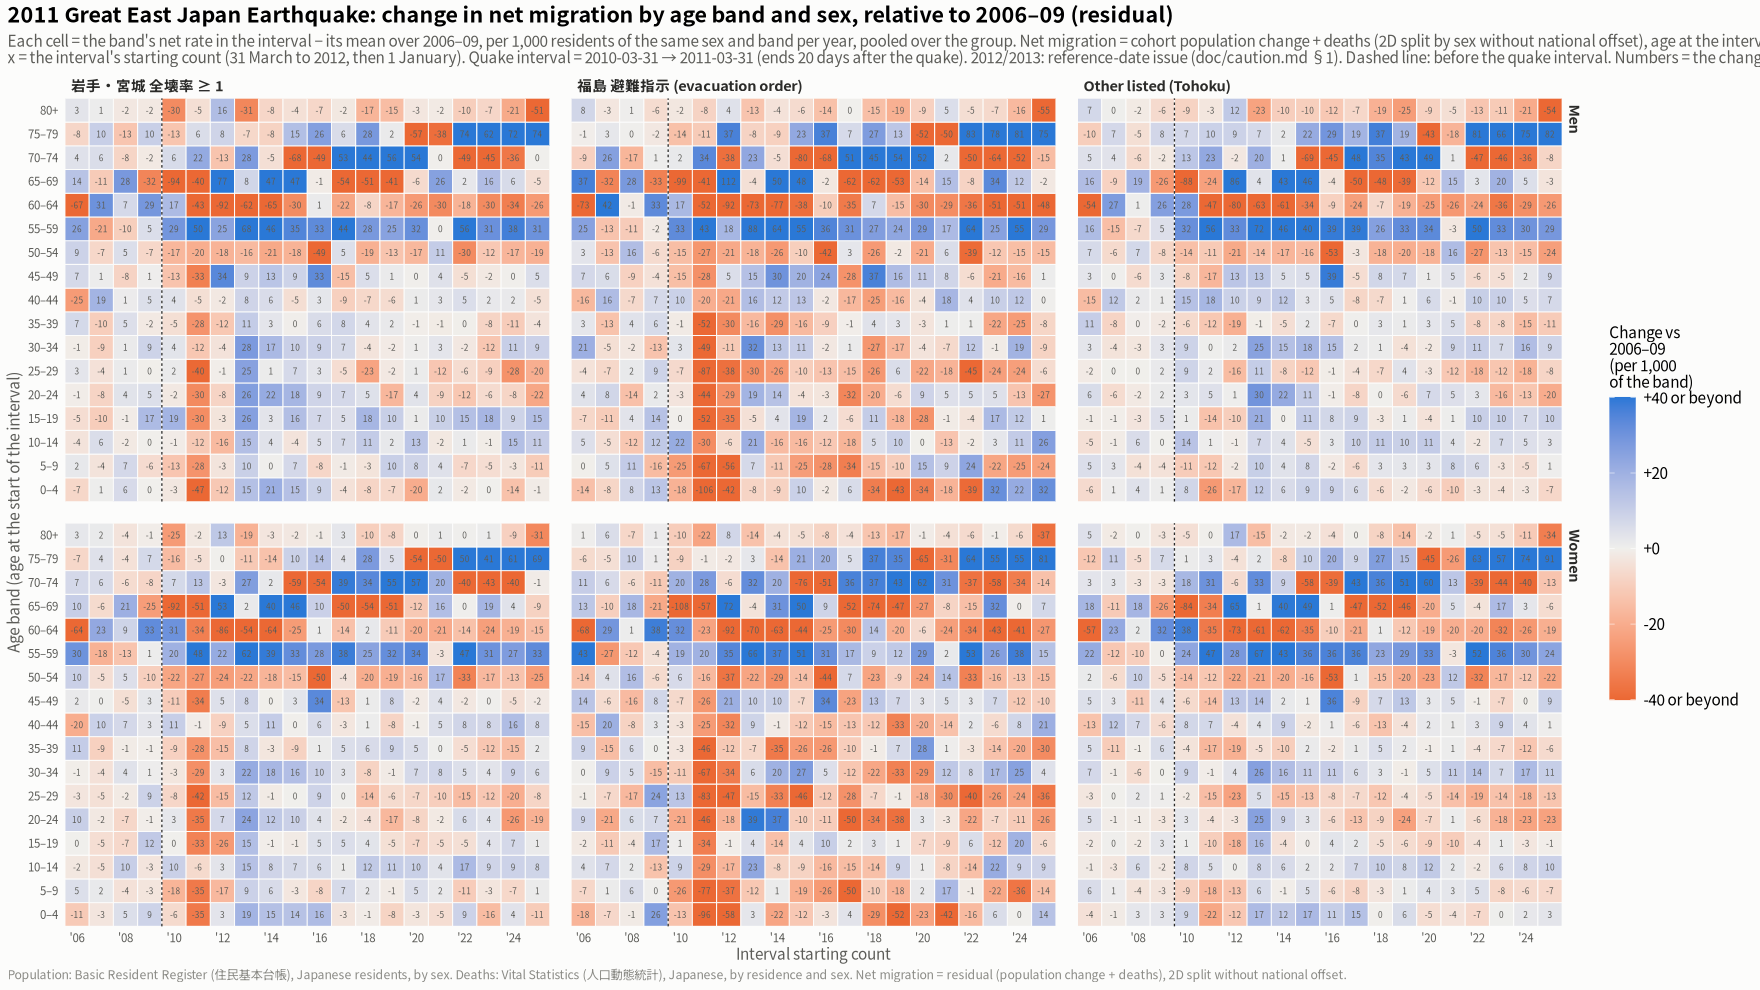

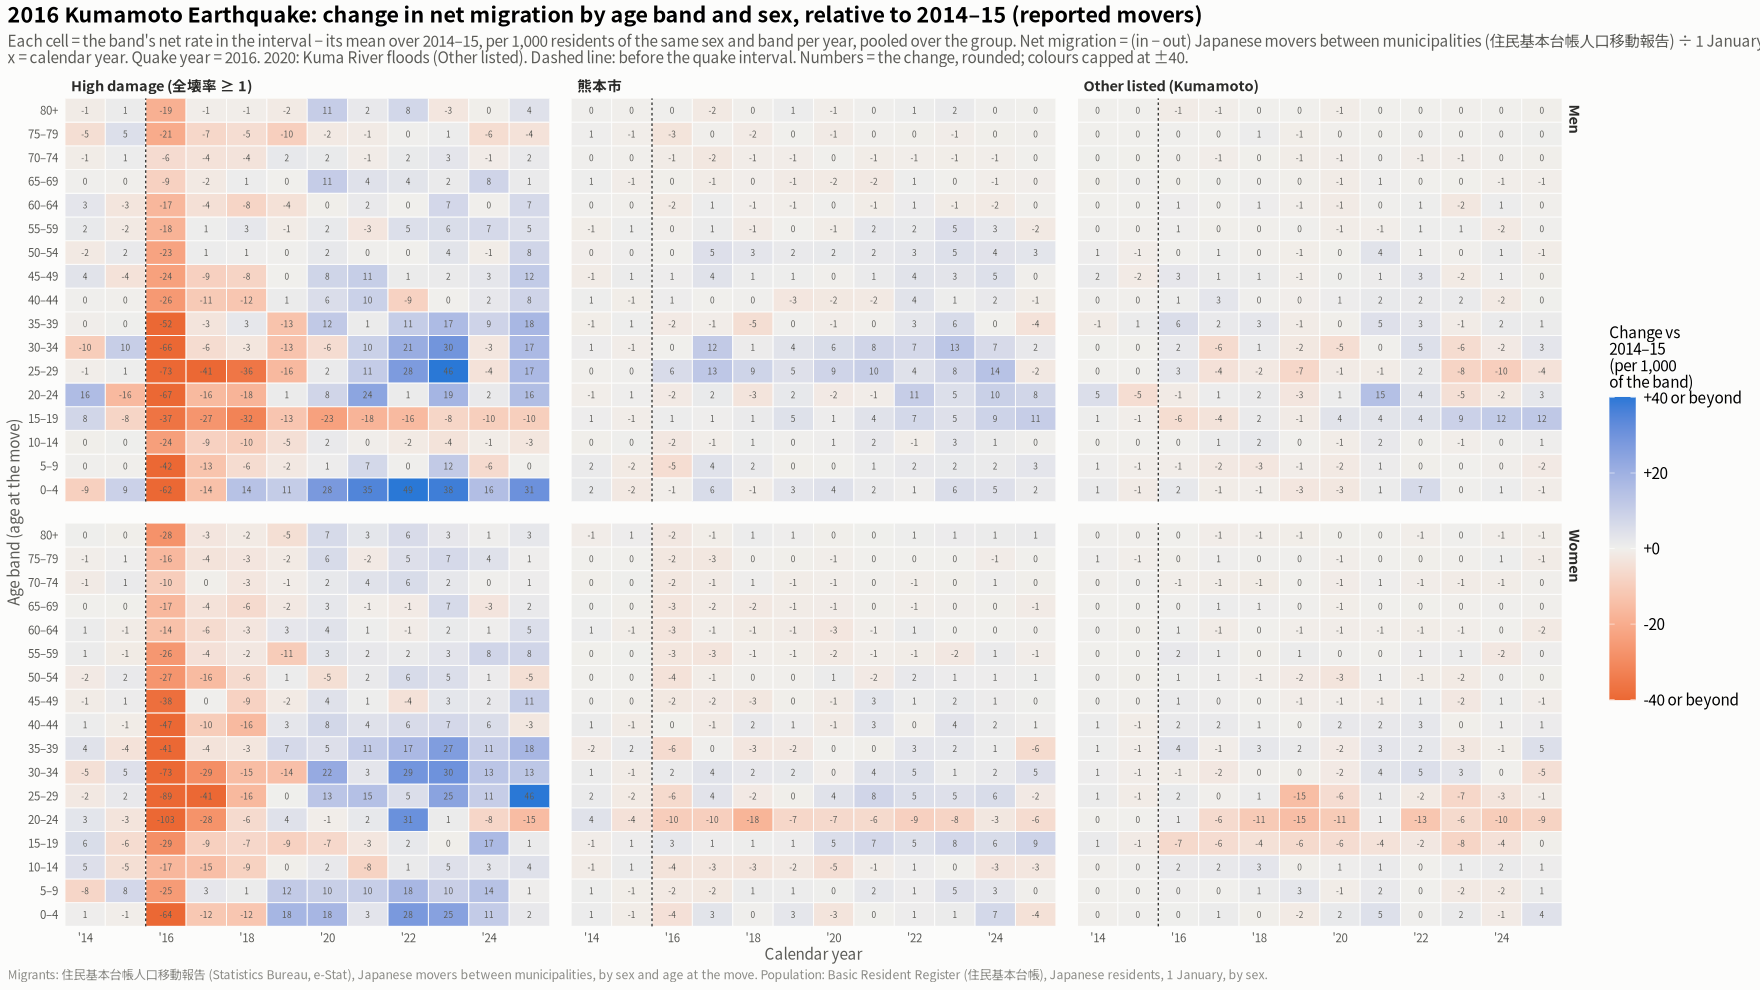

In [16]:
# Figures 12-13: heatmap of each band's own change vs the pre-quake mean, pooled by group, rows = sex
cap_g <- 40
plot_heat9 <- function(e) {
  ev <- ev9[[e]]
  dd <- d9e[[e]] |> mutate(band = band_of(age)) |>
    group_by(sex, group, start, span, band) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
    mutate(rate = 1000 * NM / (P0 * span)) |>
    group_by(sex, group, band) |> mutate(change = rate - mean(rate[start %in% ev$base])) |> ungroup()
  stopifnot(!anyNA(dd$change))
  ggplot(dd, aes(start, band, fill = pmax(pmin(change, cap_g), -cap_g))) +
    geom_tile(colour = surface, linewidth = 0.3) +
    geom_text(aes(label = ifelse(abs(change) < 0.5, "0", sprintf("%.0f", change))), size = 1.9, colour = ink2, family = jp_font) +
    geom_vline(xintercept = ev$q - 0.5, colour = ink, linewidth = 0.4, linetype = "22") +
    facet_grid(sex ~ group) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap_g, cap_g), breaks = seq(-cap_g, cap_g, cap_g / 2),
                         labels = function(v) ifelse(abs(v) == cap_g, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = paste0("Change vs\n", ev$base_lab, "\n(per 1,000\nof the band)")) +
    scale_x_continuous(breaks = seq(min(ev$starts) + (min(ev$starts) %% 2), max(ev$starts), 2),
                       labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    labs(title = paste0(ev$title, ": change in net migration by age band and sex, relative to ", ev$base_lab, " (", ev$method, ")"),
         subtitle = paste0("Each cell = the band's net rate in the interval − its mean over ", ev$base_lab,
                           ", per 1,000 residents of the same sex and band per year, pooled over the group. ", ev$desc, ".\n",
                           ev$note, " Dashed line: before the quake interval. Numbers = the change, rounded; colours capped at ±", cap_g,
                           if (ev$shade) ". Bands 55–79: no-offset band-edge artefact (stripes), not interpretable." else "."),
         x = ev$x_lab, y = paste0("Age band (", tolower(ev$age_lab), ")"), caption = ev$caption) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right", legend.justification = "center",
          legend.key.height = unit(1.4, "cm"), axis.text.x = element_text(size = 7.5), axis.text.y = element_text(size = 7.5))
}
show_save(plot_heat9("tohoku"), "12_tohoku_band_change_heat_by_sex", width = 24, height = 13)
show_save(plot_heat9("kumamoto"), "13_kumamoto_band_change_heat_by_sex", width = 22, height = 13)

2011 Great East Japan Earthquake Men : municipalities 123 ; cells beyond ± 60 : 17.1 %
2011 Great East Japan Earthquake Women : municipalities 123 ; cells beyond ± 60 : 17.3 %


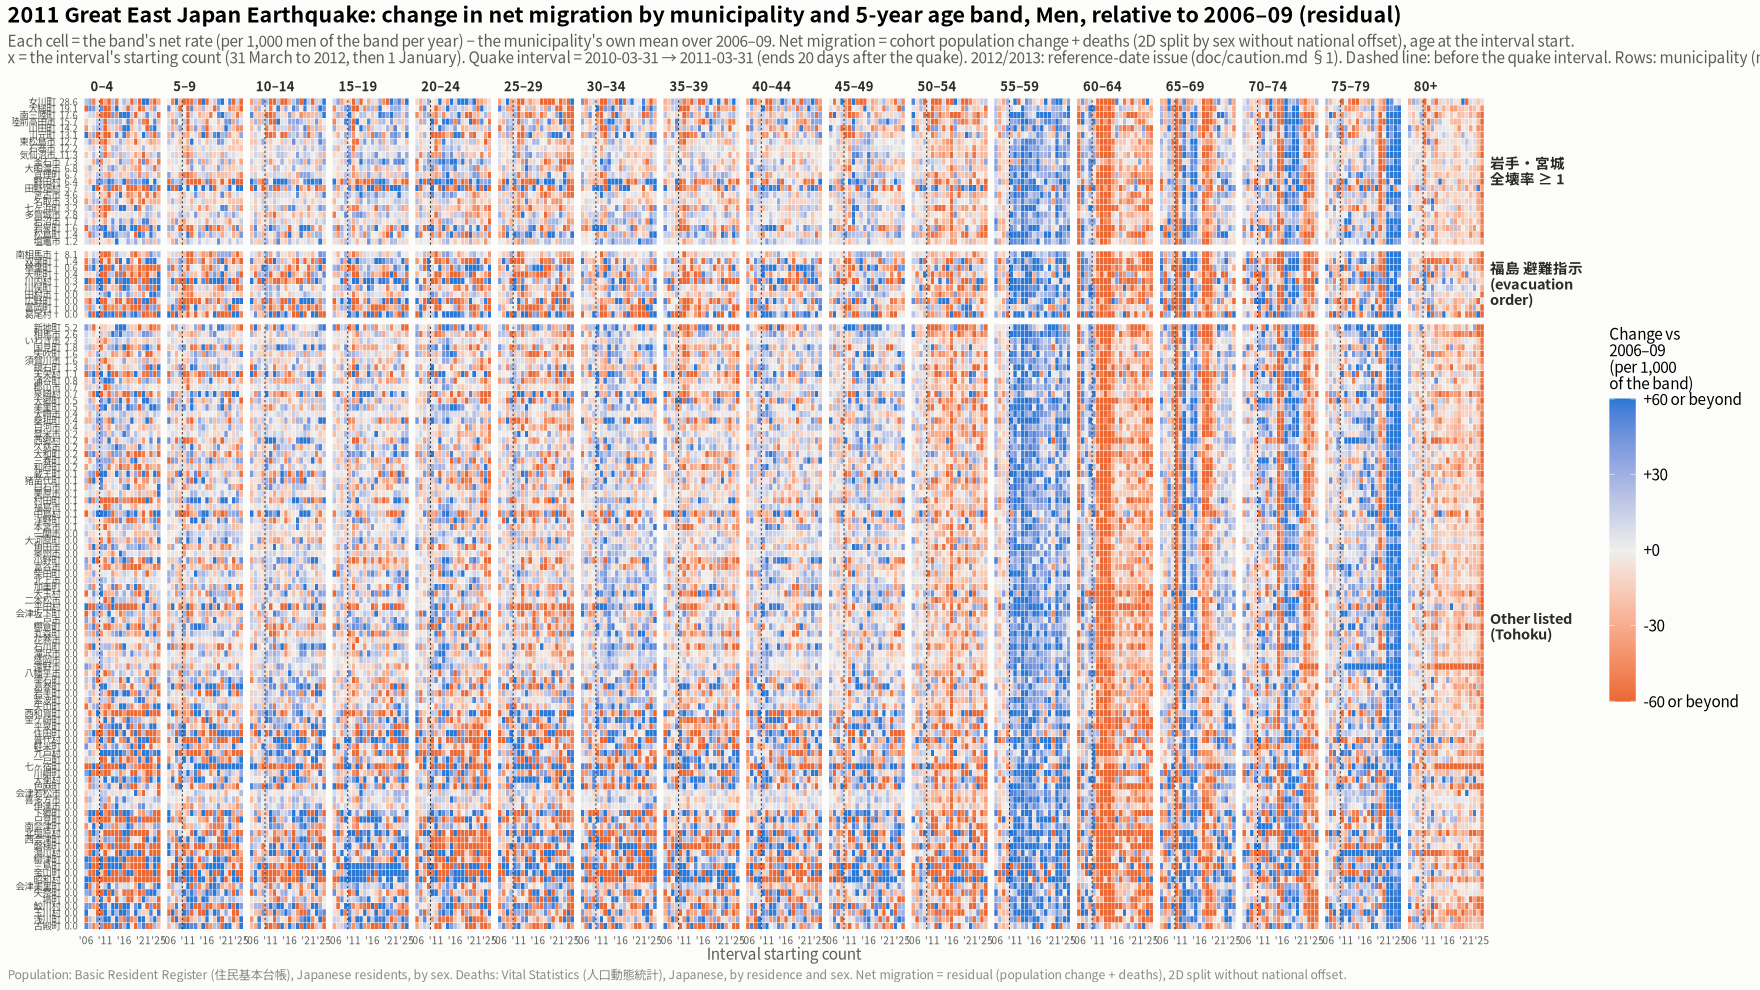

2016 Kumamoto Earthquake Men : municipalities 45 ; cells beyond ± 60 : 5 %


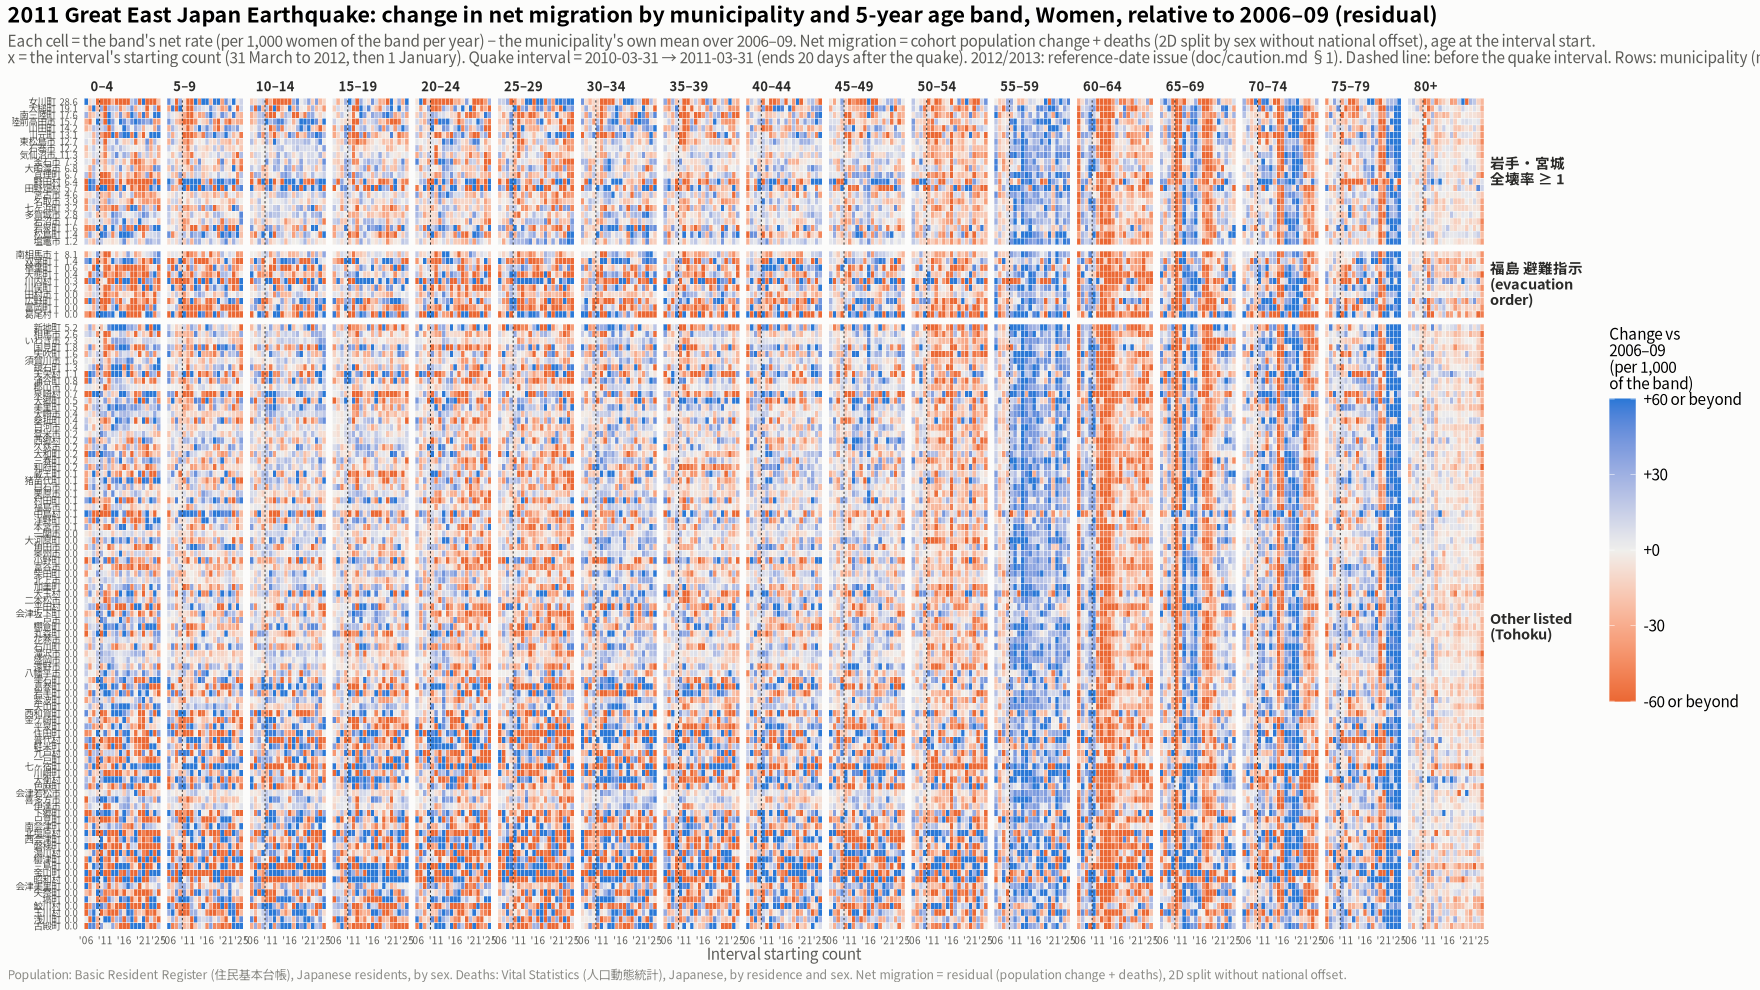

2016 Kumamoto Earthquake Women : municipalities 45 ; cells beyond ± 60 : 5.3 %


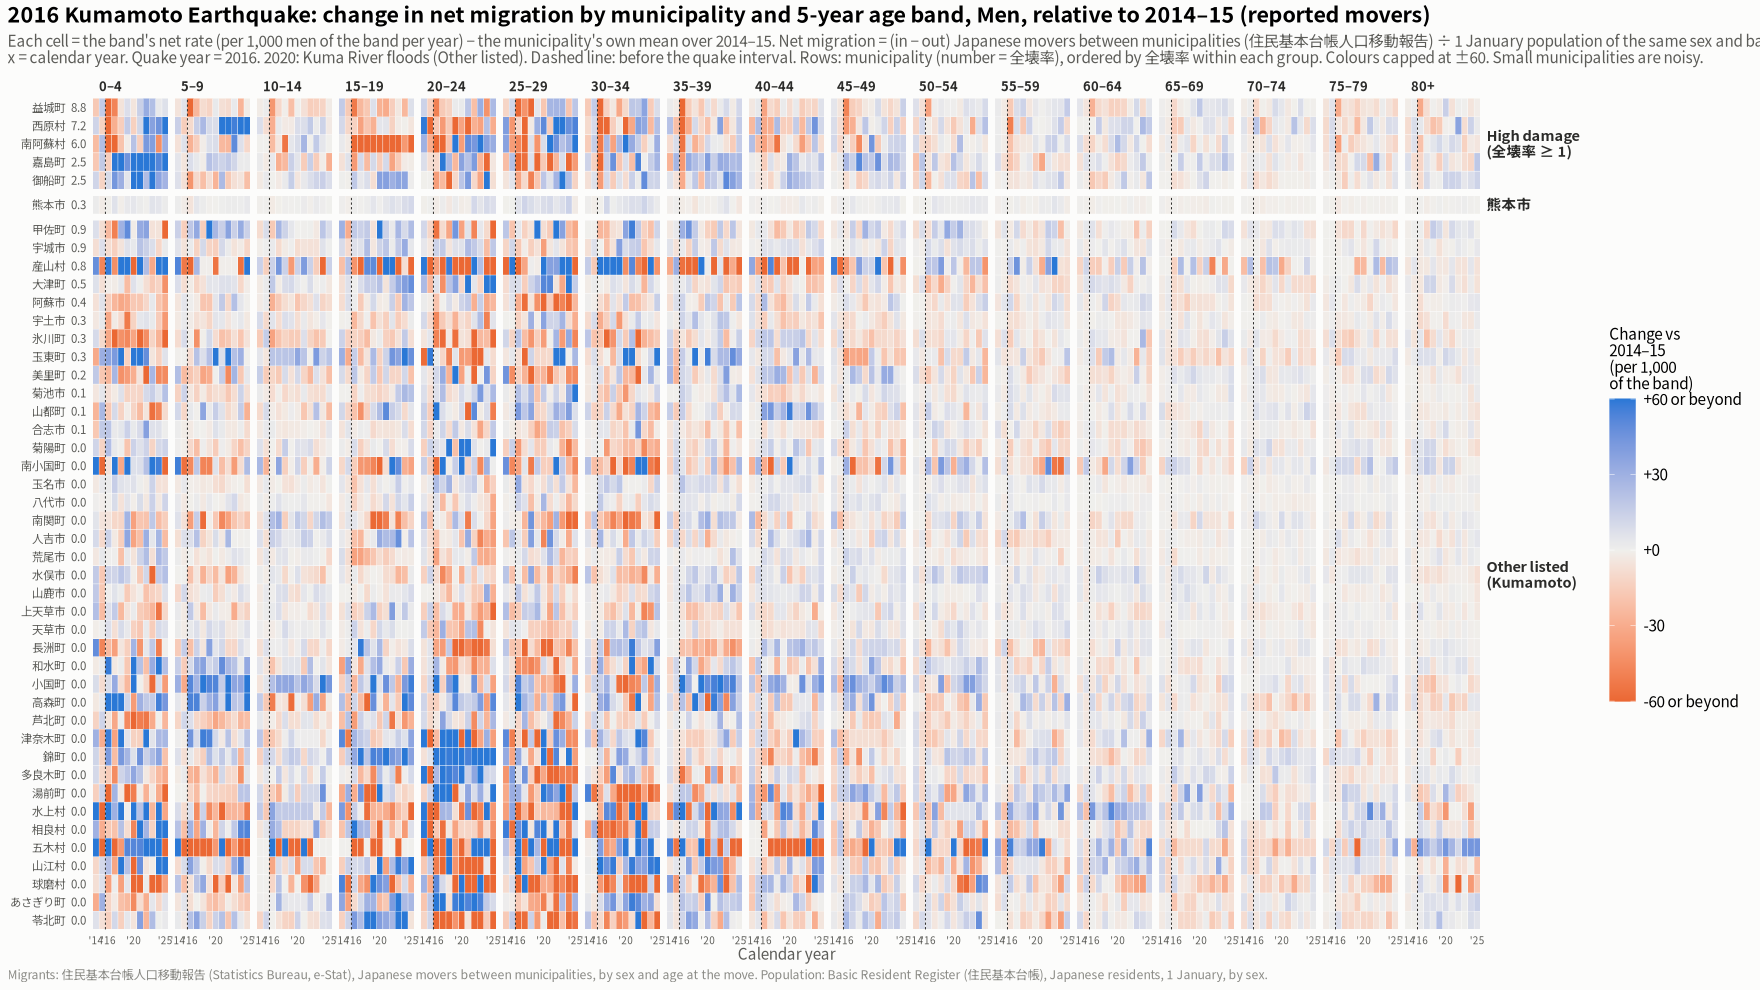

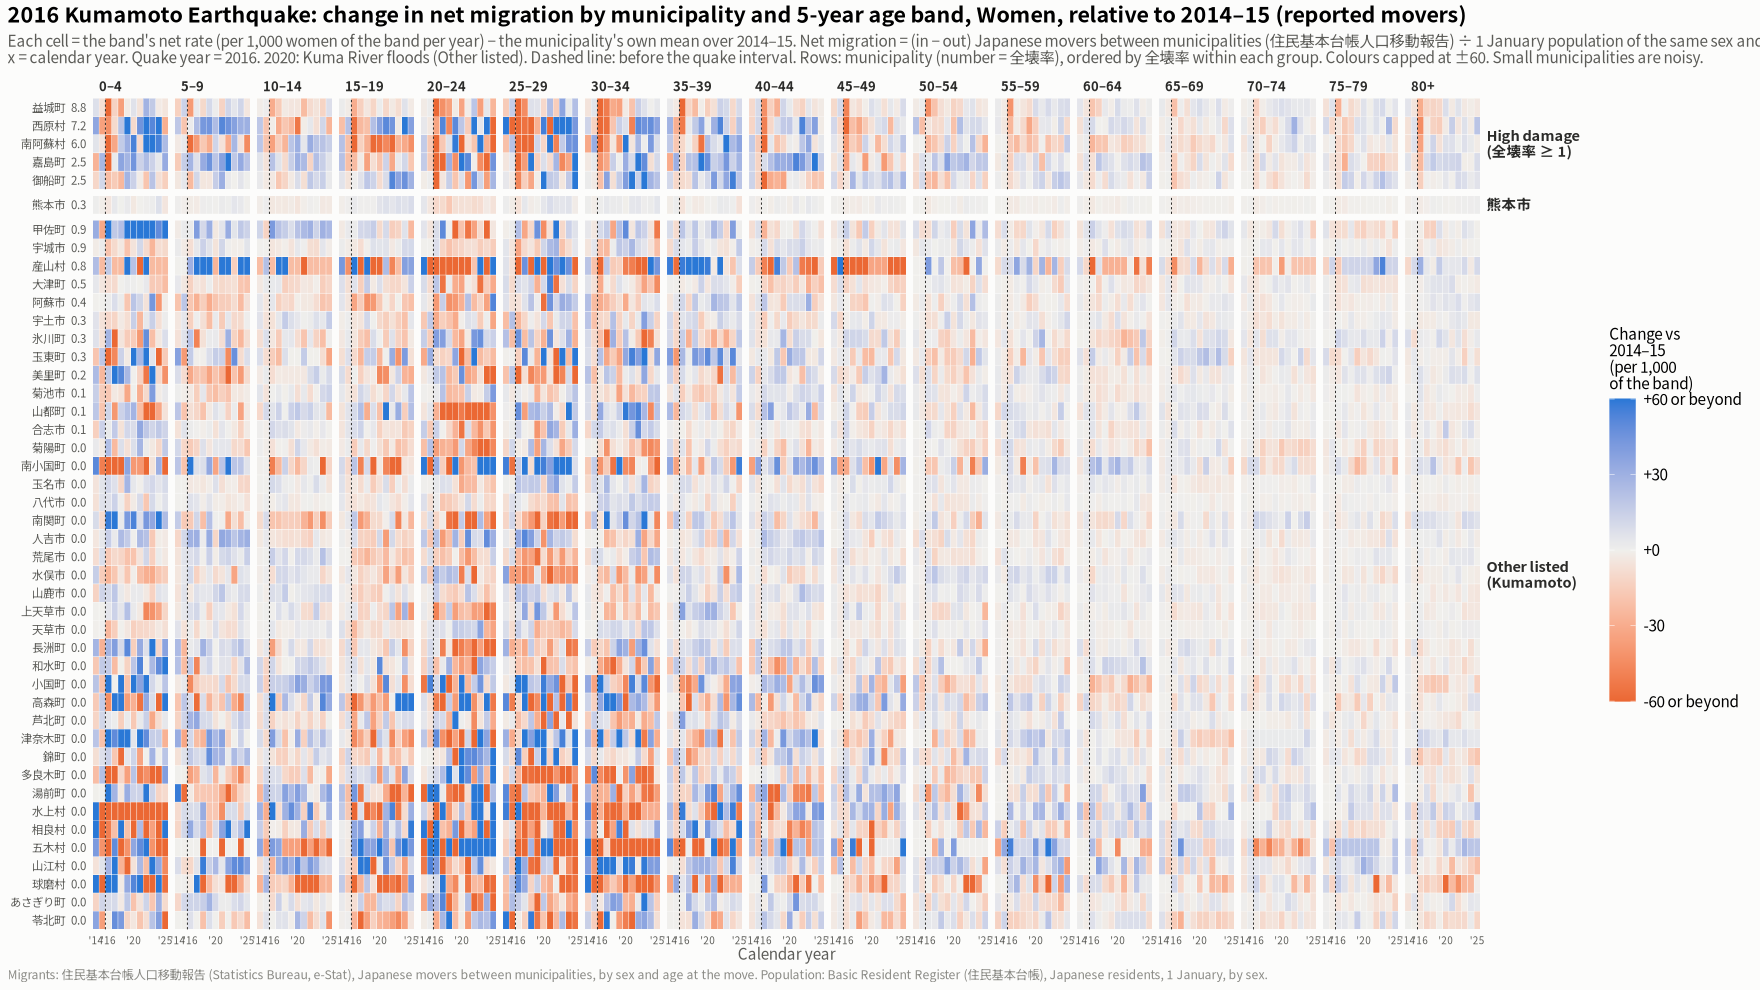

In [17]:
# Figures 14-17: heatmap by municipality and band, one figure per disaster and sex
cap_m <- 60
plot_muni9 <- function(e, s) {
  ev <- ev9[[e]]
  lab_tab <- ev$grp |> mutate(group = factor(group, levels = ev$levels)) |>
    arrange(group, desc(zenkai_rate)) |>
    mutate(label = paste0(short_lab, "  ", sprintf("%.1f", zenkai_rate)))
  dd <- d9e[[e]] |> filter(sex == s) |> mutate(band = band_of(age)) |>
    group_by(code, group, start, span, band) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
    mutate(rate = ifelse(P0 > 0, 1000 * NM / (P0 * span), NA)) |>
    group_by(code, band) |> mutate(change = rate - mean(rate[start %in% ev$base])) |> ungroup() |>
    inner_join(lab_tab |> select(code, label), by = "code") |>
    mutate(label = factor(label, levels = rev(lab_tab$label)))
  cat(ev$title, s, ": municipalities", n_distinct(dd$code), "; cells beyond ±", cap_m, ":",
      round(100 * mean(abs(dd$change) > cap_m, na.rm = TRUE), 1), "%\n")
  ggplot(dd, aes(start, label, fill = pmax(pmin(change, cap_m), -cap_m))) +
    geom_tile(colour = surface, linewidth = 0.1) +
    geom_vline(xintercept = ev$q - 0.5, colour = ink, linewidth = 0.3, linetype = "22") +
    facet_grid(group ~ band, scales = "free_y", space = "free_y", labeller = labeller(group = label_wrap_gen(14))) +
    scale_fill_gradient2(low = "#eb6834", mid = "#f0efec", high = "#2a78d6", midpoint = 0,
                         limits = c(-cap_m, cap_m), breaks = seq(-cap_m, cap_m, 30), na.value = "#d9d8d3",
                         labels = function(v) ifelse(abs(v) == cap_m, sprintf("%+g or beyond", v), sprintf("%+g", v)),
                         name = paste0("Change vs\n", ev$base_lab, "\n(per 1,000\nof the band)")) +
    scale_x_continuous(breaks = if (e == "tohoku") c(2006, 2011, 2016, 2021, 2025) else c(2014, 2016, 2020, 2025),
                       labels = function(v) paste0("'", substr(v, 3, 4)), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    labs(title = paste0(ev$title, ": change in net migration by municipality and 5-year age band, ", s, ", relative to ", ev$base_lab, " (", ev$method, ")"),
         subtitle = paste0("Each cell = the band's net rate (per 1,000 ", tolower(s), " of the band per year) − the municipality's own mean over ", ev$base_lab,
                           ". ", ev$desc, ".\n",
                           ev$note, " Dashed line: before the quake interval. Rows: municipality (number = 全壊率), ordered by 全壊率 within each group",
                           if (e == "tohoku") "; † = evacuation order" else "", ". Colours capped at ±", cap_m,
                           ". Small municipalities are noisy", if (ev$shade) "; bands 55–79 carry the no-offset band-edge artefact." else "."),
         x = ev$x_lab, y = NULL, caption = ev$caption) +
    base_theme() +
    theme(panel.grid.major.y = element_blank(), legend.position = "right", legend.justification = "center",
          legend.key.height = unit(1.4, "cm"), axis.text.y = element_text(size = if (e == "tohoku") 6.2 else 7.5),
          axis.text.x = element_text(size = 6.5), strip.text.y = element_text(angle = 0, hjust = 0),
          strip.text.x = element_text(size = 8.5), panel.spacing = unit(0.15, "cm"))
}
show_save(plot_muni9("tohoku", "Men"), "14_tohoku_band_change_by_muni_men", width = 30, height = 20)
show_save(plot_muni9("tohoku", "Women"), "15_tohoku_band_change_by_muni_women", width = 30, height = 20)
show_save(plot_muni9("kumamoto", "Men"), "16_kumamoto_band_change_by_muni_men", width = 28, height = 11)
show_save(plot_muni9("kumamoto", "Women"), "17_kumamoto_band_change_by_muni_women", width = 28, height = 11)

## Figure 18: figure 3 with √population weights

Figure 3 refitted by weighted least squares. Each municipality is weighted by √(its 20–39 population of the same sex at the 2010-03-31 count; both sexes = men + women).

**Why √population**
- The sampling noise of a rate is roughly proportional to 1/√population, so these weights down-weight the noisy small towns.
- Unlike full population weights, they do not let one city decide the result: the largest, いわき市, gets 11% of the total weight instead of 26% of the population.

**What stays as in figure 3**
- **Predictors:** standardised with the unweighted mean and SD, so the slopes are per 1 SD on the same scale as figure 3.
- **Models:** unadjusted; adjusted for the same sex's 2010–11 loss; and the full model.

**Leave-one-out check.** The table repeats the leave-one-out comparison with the error weighted the same way: weighted RMSE = √(Σ w·e² / Σ w).

Weighted (sqrt population) slope per 1 SD (per 1,000, 2 years), with p; compare with figure 3:


variable,Both sexes_none,Both sexes_loss,Both sexes_full,Men_none,Men_loss,Men_full,Women_none,Women_loss,Women_full
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"2010–11 net migration vs 2006–09 (same sex, 20–39)",+12.6 (p 0.007),+12.6 (p 0.007),+6.9 (p 0.16),+9.7 (p 0.071),+9.7 (p 0.071),+4.4 (p 0.44),+16.5 (p 0.00039),+16.5 (p 0.00039),+10.3 (p 0.03)
市町村内の働く場所÷住民の働き手(%),+7.4 (p 0.084),+4.6 (p 0.26),+6.9 (p 0.44),+7.0 (p 0.16),+4.6 (p 0.37),+13.2 (p 0.24),+7.8 (p 0.07),+5.0 (p 0.17),+0.9 (p 0.91)
事業所数/人口千人,+8.5 (p 0.039),+6.0 (p 0.12),-1.2 (p 0.9),+7.5 (p 0.12),+5.4 (p 0.26),-6.4 (p 0.56),+9.3 (p 0.022),+6.7 (p 0.051),+3.7 (p 0.65)
通勤流出率,-5.4 (p 0.16),-3.2 (p 0.36),-3.0 (p 0.58),-5.1 (p 0.24),-3.1 (p 0.49),-1.8 (p 0.78),-5.4 (p 0.15),-3.7 (p 0.24),-4.6 (p 0.35)
失業率,+6.4 (p 0.19),+4.6 (p 0.31),+3.4 (p 0.53),+6.1 (p 0.27),+5.1 (p 0.35),+1.5 (p 0.82),+7.3 (p 0.14),+4.3 (p 0.29),+6.0 (p 0.23)
第1次産業比,-5.5 (p 0.25),-5.0 (p 0.24),-17.8 (p 0.056),-5.9 (p 0.27),-5.8 (p 0.26),-27.1 (p 0.02),-5.3 (p 0.27),-4.1 (p 0.29),-7.7 (p 0.35)
第2次産業比,-5.5 (p 0.21),-3.3 (p 0.41),-9.5 (p 0.11),-3.9 (p 0.44),-3.2 (p 0.52),-13.3 (p 0.067),-7.3 (p 0.093),-3.4 (p 0.37),-5.3 (p 0.32)
職住自足率（従業地/常住就業者）,+5.2 (p 0.25),+2.0 (p 0.64),NA,+4.5 (p 0.38),+1.3 (p 0.8),NA,+5.7 (p 0.2),+3.1 (p 0.41),NA
納税者1人当たり課税所得(万円),-1.6 (p 0.7),-1.3 (p 0.73),-15.1 (p 0.14),-2.4 (p 0.62),-1.8 (p 0.69),-22.8 (p 0.076),-0.6 (p 0.88),-0.8 (p 0.81),-7.1 (p 0.44)



Weighted model summaries (largest = municipality with the largest weight; LOO = weighted leave-one-out RMSE):


sex,r2_full,adj_r2_full,largest,weight_share,pop_share,loo_null,loo_loss,loo_full
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Both sexes,0.52,0.31,いわき市,0.11,0.26,22.10,20.38,24.32
Men,0.44,0.19,いわき市,0.11,0.26,25.17,25.05,30.23
Women,0.60,0.42,いわき市,0.11,0.26,22.06,18.18,20.83


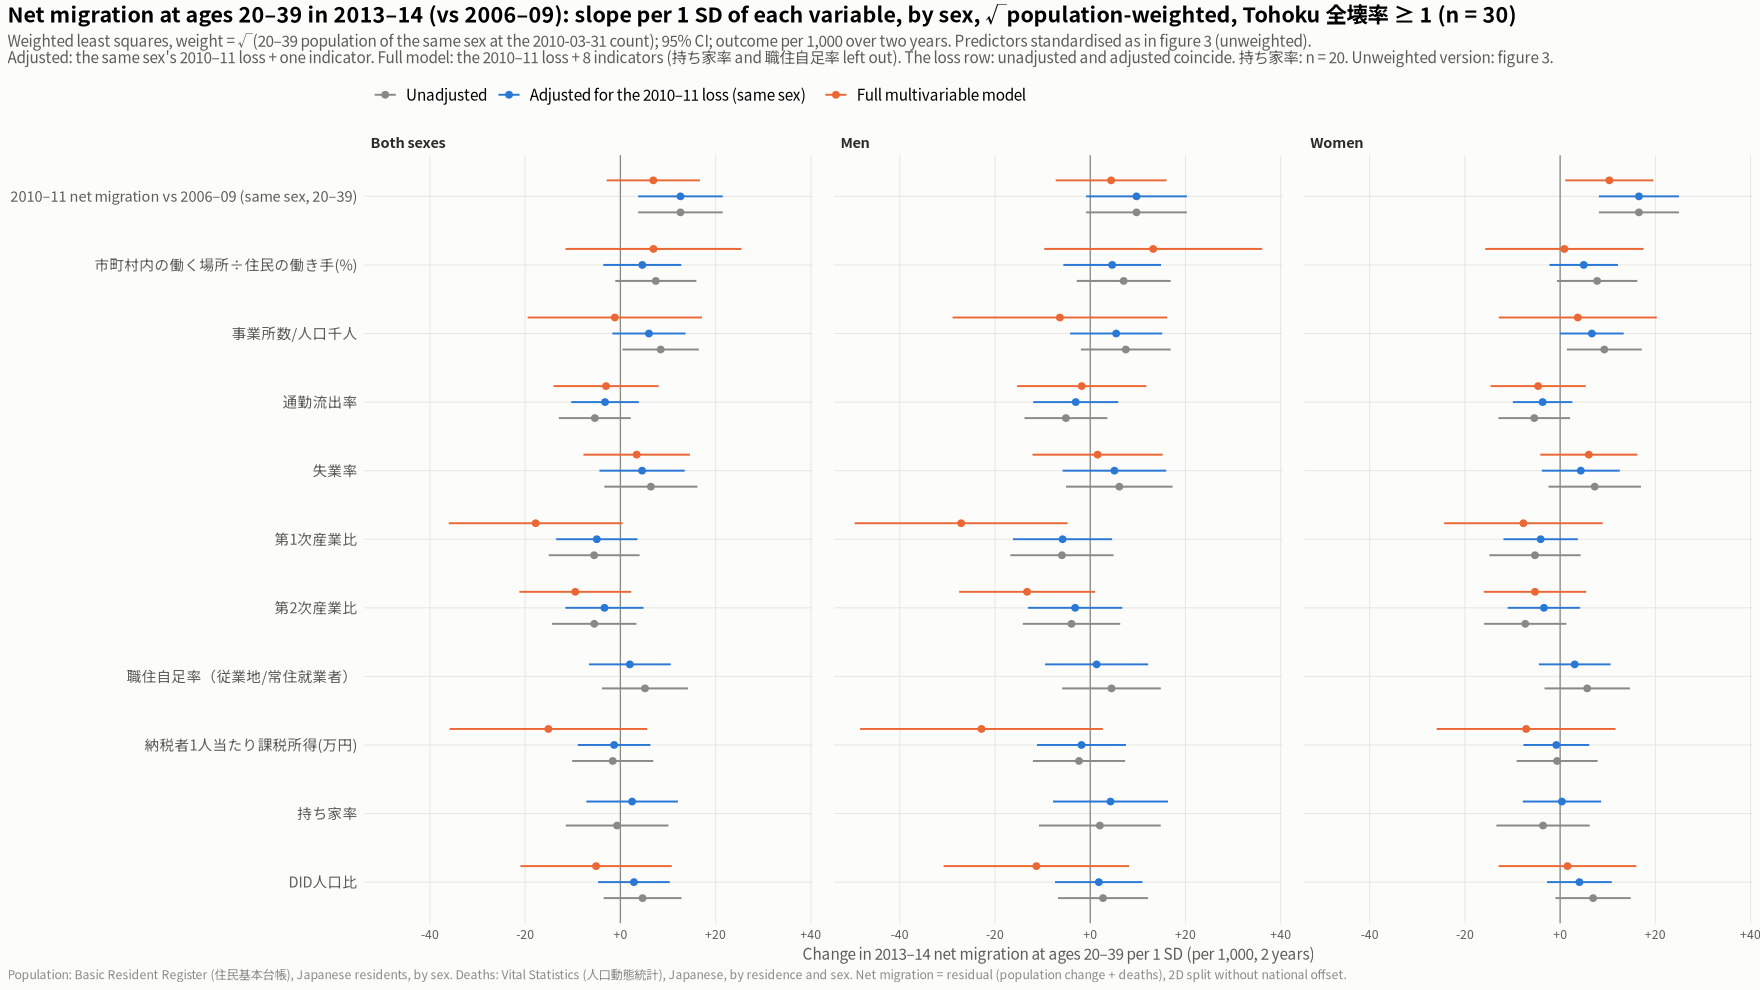

In [18]:
# Figure 18: weighted least squares, weights = sqrt(20-39 population of the same sex at the 2010 count)
fit_one_w <- function(d, v, adj) {
  dd <- d |> transmute(y, w = sqrt(pop2039_2010), v = zs(.data[[v]]), loss = zs(x)) |> filter(!is.na(v))
  f <- if (adj == "none" || v == loss_var) y ~ v else y ~ v + loss
  m <- lm(f, data = dd, weights = w); ci <- confint(m)["v", ]
  tibble(variable = v, model = adj, n = nrow(dd), beta = coef(m)[["v"]], lo = ci[[1]], hi = ci[[2]],
         p = summary(m)$coefficients["v", 4])
}
outw <- lapply(sex_levels, function(s) {
  d <- d9 |> filter(sex == s)
  adj <- bind_rows(lapply(c("none", "loss"), function(a) bind_rows(lapply(expl9, fit_one_w, d = d, adj = a))))
  X <- d |> transmute(y, w = sqrt(pop2039_2010), across(all_of(full_vars), zs)); names(X) <- c("y", "w", names(key9))
  m_full <- lm(reformulate(names(key9), "y"), data = X, weights = w)
  full <- tibble(term = names(key9), variable = unname(key9), model = "full", n = nrow(X), beta = coef(m_full)[term],
                 lo = confint(m_full)[term, 1], hi = confint(m_full)[term, 2], p = summary(m_full)$coefficients[term, 4])
  wloo <- function(form) {
    e2 <- sapply(seq_len(nrow(X)), function(i) { m <- lm(form, data = X[-i, ], weights = w); (X$y[i] - predict(m, X[i, ]))^2 })
    sqrt(sum(X$w * e2) / sum(X$w))
  }
  share <- d |> mutate(sh = sqrt(pop2039_2010) / sum(sqrt(pop2039_2010)), shp = pop2039_2010 / sum(pop2039_2010)) |>
    slice_max(sh, n = 1)
  list(adj = bind_rows(adj, select(full, -term)) |> mutate(sex = s),
       summary = tibble(sex = s, r2_full = summary(m_full)$r.squared, adj_r2_full = summary(m_full)$adj.r.squared,
                        largest = share$short_lab, weight_share = share$sh, pop_share = share$shp,
                        loo_null = wloo(y ~ 1), loo_loss = wloo(y ~ v1), loo_full = wloo(reformulate(names(key9), "y"))))
})
adjw <- bind_rows(lapply(outw, `[[`, "adj")); sumw <- bind_rows(lapply(outw, `[[`, "summary"))

cat("Weighted (sqrt population) slope per 1 SD (per 1,000, 2 years), with p; compare with figure 3:\n")
adjw |> transmute(sex, variable, model, est = sprintf("%+.1f (p %.2g)", beta, p)) |>
  pivot_wider(names_from = c(sex, model), values_from = est) |> as.data.frame()
cat("\nWeighted model summaries (largest = municipality with the largest weight; LOO = weighted leave-one-out RMSE):\n")
sumw |> mutate(across(where(is.numeric), \(v) round(v, 2))) |> as.data.frame()

f18 <- adjw |> mutate(model = factor(mlabs9[model], levels = mlabs9), variable = factor(variable, levels = rev(expl9)),
                      sex = factor(sex, levels = sex_levels))
p18 <- p3; p18$data <- f18
p18 <- p18 +
  labs(title = "Net migration at ages 20–39 in 2013–14 (vs 2006–09): slope per 1 SD of each variable, by sex, √population-weighted, Tohoku 全壊率 ≥ 1 (n = 30)",
       subtitle = paste0("Weighted least squares, weight = √(20–39 population of the same sex at the 2010-03-31 count); 95% CI; outcome per 1,000 over two years. ",
                         "Predictors standardised as in figure 3 (unweighted).\n",
                         "Adjusted: the same sex's 2010–11 loss + one indicator. Full model: the 2010–11 loss + 8 indicators (持ち家率 and 職住自足率 left out). ",
                         "The loss row: unadjusted and adjusted coincide. 持ち家率: n = 20. Unweighted version: figure 3."))
show_save(p18, "18_2039_socioecon_slopes_by_sex_sqrtw", width = 20, height = 9)

# Figures 19–22: reproductive-value-weighted net migration (women, Tohoku)

The 20–39 outcome treats a 21-year-old and a 38-year-old woman alike. Here each woman who moves is weighted by her **reproductive value** (再生産価値; Fisher 1930), so the outcome measures how much of a municipality's future births leaves or arrives through migration.

**Reproductive value, national and identical for every municipality**
- **Schedule:** Japan 2010–2015 from UN WPP 2019 (R package `wpp2019`, pinned in the Dockerfile).
  - Female mortality `mxF` (abridged ages, constant within each age group).
  - TFR × the age pattern `percentASFR` (uniform within each 5-year band 15–49).
  - Sex ratio at birth `sexRatio`.
- **Survival:** l(a) = Π exp(−m<sub>x</sub>). **Maternity:** m(x) = daughters per woman per year at age x.
- **Intrinsic growth rate r:** solved from Euler–Lotka, Σ e<sup>−r(x+½)</sup> l(x+½) m(x) = 1.
- **Reproductive value at exact age a:** v(a) = Σ<sub>x≥a</sub> e<sup>−r(x+½−a)</sup> · l(x+½)/l(a) · m(x).
  - v(0) = 1, and v = 0 from age 50.
  - With r < 0 (a declining population), future daughters count for more.
  - **Shape:** for Japan (r ≈ −1.2%/yr), v(a) is highest at birth and falls with age: 0.89 at 10, 0.77 at 20, 0.41 at 30, 0.15 at 35, about 0 from 45. It peaks in the 20s only when r > 0.
  - **Consequence:** girls (0–14) carry almost full weight, so the outcome counts families moving with daughters as heavily as young women. It measures the future-births potential leaving or arriving, not only women of childbearing age.

**Outcome (women, all ages, residual of this notebook)**
- rate<sub>RV</sub> = 1000 · Σ<sub>a</sub> v(a)·NM(a) ÷ Σ<sub>a</sub> v(a)·P<sub>0</sub>(a), per year (a = age at the interval start). This is the change in the municipality's female reproductive-value stock through migration, per 1,000.
- x and y as in figure 1, relative to the mean over the intervals starting 2006–09:
  - x = intervals 2010 + 2011;
  - y = intervals 2013 + 2014;
  - per 1,000 of the reproductive-value stock, two years.

**Analyses**
- Figure 19: v(a) and m(x).
- Figure 20: x vs y for all listed Tohoku municipalities (as figure 1).
- Figure 21: the outcome against the socio-economic indicators of the 30 municipalities with 全壊率 ≥ 1 (as figure 2). The RV-weighted 2010–11 loss is the first panel.
- Figure 22: slopes per 1 SD, unweighted and √-weighted side by side (as figures 3 and 18). The weight is √(the reproductive-value stock in 2010).

TFR,SRB,NRR,r_per_year,mean_age_childbearing,peak_age,v_peak
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
1.4087,1.056,0.68,-0.0124,30.8,0,1


age,v,m
<int>,<dbl>,<dbl>
0,1.000,0.000
10,0.886,0.000
15,0.833,0.002
20,0.773,0.016
25,0.651,0.042
30,0.410,0.048
35,0.153,0.025
40,0.024,0.004
45,0.001,0.000


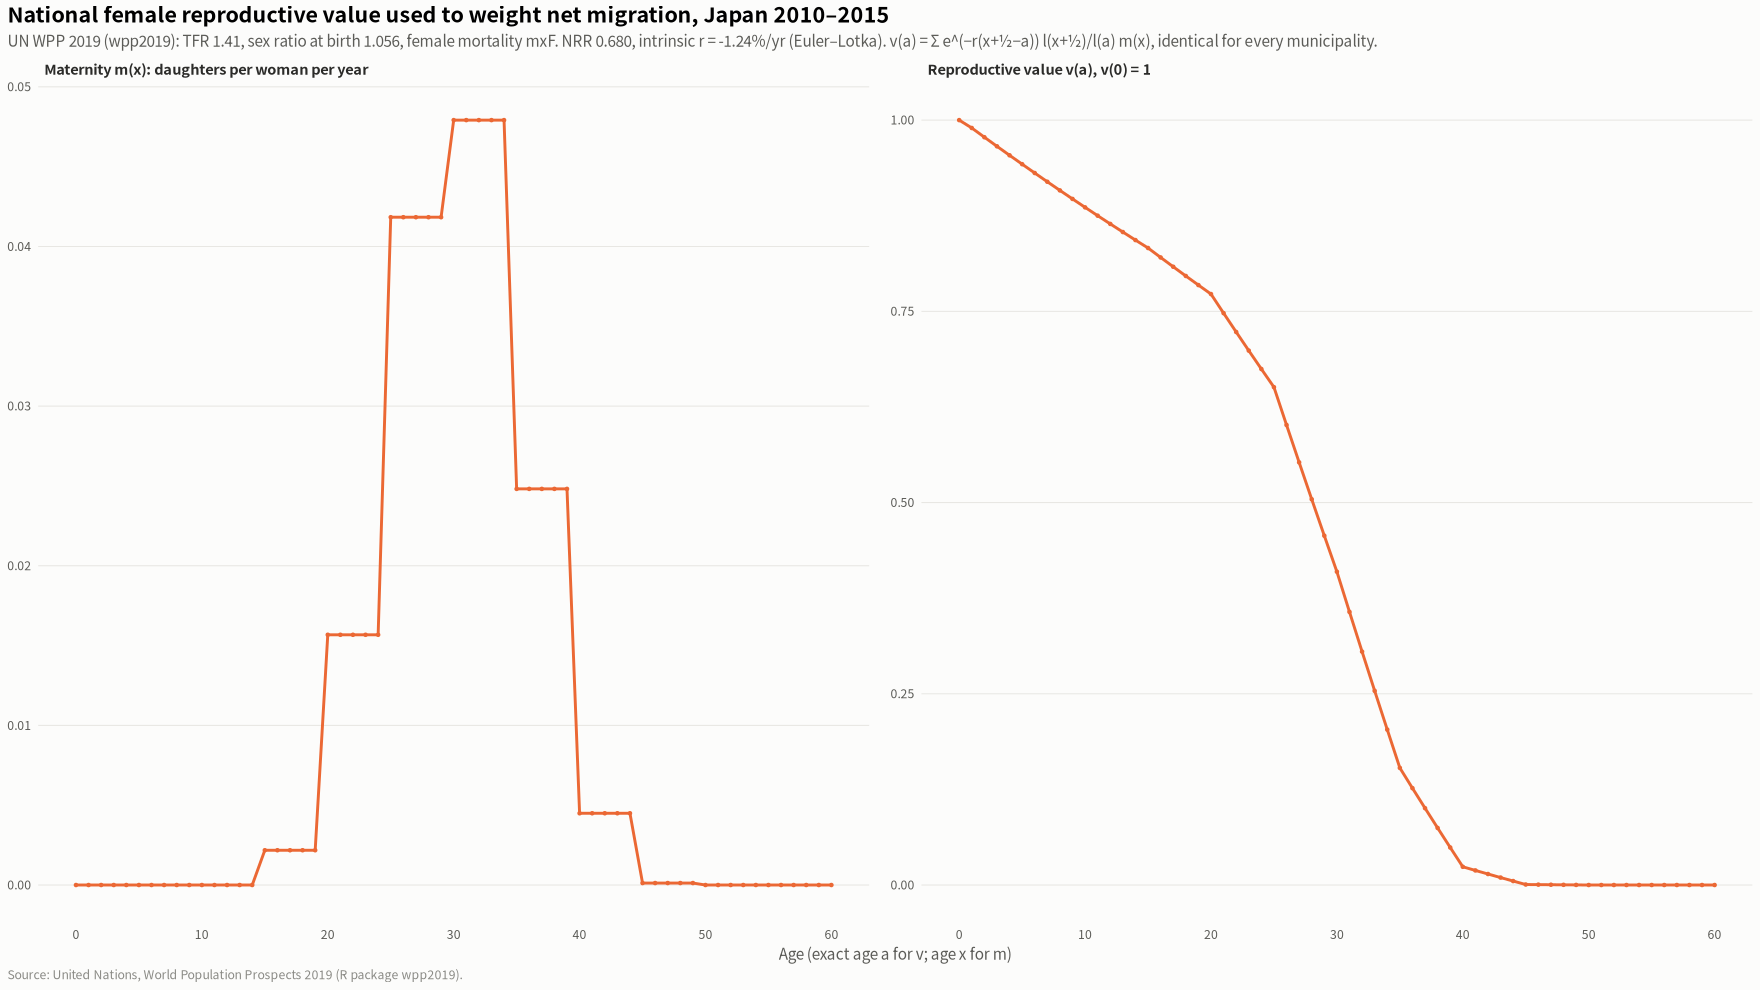

In [19]:
# Figure 19: national female reproductive value, Japan 2010-2015 (WPP 2019)
suppressPackageStartupMessages(library(wpp2019))
data(tfr, package = "wpp2019"); data(percentASFR, package = "wpp2019"); data(mxF, package = "wpp2019"); data(sexRatio, package = "wpp2019")
per <- "2010-2015"; jp <- 392
tfr_jp <- tfr[tfr$country_code == jp, per]
srb_jp <- sexRatio[sexRatio$country_code == jp, per]
asfr_pct <- percentASFR[percentASFR$country_code == jp, c("age", per)]
mx_ab <- mxF[mxF$country_code == jp, c("age", per)]
ages <- 0:(top_age - 1)
mx1 <- mx_ab[[per]][findInterval(ages, as.numeric(mx_ab$age))]          # constant within each abridged group
l1 <- c(1, cumprod(exp(-mx1)))                                           # l(0) ... l(105)
lmid <- sqrt(head(l1, -1) * tail(l1, -1))                                # l(x + 1/2)
band_lo <- as.integer(sub("-.*", "", asfr_pct$age))
mat <- ifelse(ages >= 15 & ages <= 49,
              tfr_jp * asfr_pct[[per]][match(ages %/% 5 * 5, band_lo)] / 100 / 5 / (1 + srb_jp), 0)
mat[is.na(mat)] <- 0
el <- function(r) sum(exp(-r * (ages + 0.5)) * lmid * mat) - 1
r_jp <- uniroot(el, c(-0.1, 0.1), tol = 1e-12)$root
nrr <- sum(lmid * mat)
v_age <- sapply(ages, function(a) { x <- ages >= a; sum(exp(-r_jp * (ages[x] + 0.5 - a)) * lmid[x] / l1[a + 1] * mat[x]) })
v_age <- v_age / v_age[1]
rv <- tibble(age = ages, v = v_age, m = mat)
stopifnot(abs(v_age[1] - 1) < 1e-9, all(v_age[ages >= 50] == 0))
tibble(TFR = tfr_jp, SRB = srb_jp, NRR = round(nrr, 3), r_per_year = round(r_jp, 4),
       mean_age_childbearing = round(sum((ages + 0.5) * lmid * mat) / nrr, 1),
       peak_age = ages[which.max(v_age)], v_peak = round(max(v_age), 3)) |> as.data.frame()
rv |> filter(age %in% c(0, 10, 15, 20, 25, 30, 35, 40, 45)) |> mutate(across(c(v, m), \(x) round(x, 3))) |> as.data.frame()

p19 <- rv |> filter(age <= 60) |>
  transmute(age, `Reproductive value v(a), v(0) = 1` = v, `Maternity m(x): daughters per woman per year` = m) |>
  pivot_longer(-age, names_to = "what", values_to = "val") |>
  ggplot(aes(age, val)) +
  geom_line(colour = "#eb6834", linewidth = 0.9) + geom_point(colour = "#eb6834", size = 0.8) +
  facet_wrap(~what, nrow = 1, scales = "free_y") +
  scale_x_continuous(breaks = seq(0, 60, 10)) +
  labs(title = "National female reproductive value used to weight net migration, Japan 2010–2015",
       subtitle = sprintf("UN WPP 2019 (wpp2019): TFR %.2f, sex ratio at birth %.3f, female mortality mxF. NRR %.3f, intrinsic r = %.2f%%/yr (Euler–Lotka). v(a) = Σ e^(−r(x+½−a)) l(x+½)/l(a) m(x), identical for every municipality.",
                          tfr_jp, srb_jp, nrr, 100 * r_jp),
       x = "Age (exact age a for v; age x for m)", y = NULL, caption = "Source: United Nations, World Population Prospects 2019 (R package wpp2019).") +
  base_theme()
show_save(p19, "19_reproductive_value_japan", width = 14, height = 5.5)

Spearman, RV-weighted vs women 20-39 outcome: x 0.74  y 0.78 


group,n,median_base,median_x,median_y
<fct>,<int>,<dbl>,<dbl>,<dbl>
岩手・宮城 全壊率 ≥ 1,22,-19.7,-31.9,23.3
福島 避難指示 (evacuation order),10,-13.3,-47.9,0.6
Other listed (Tohoku),91,-15.7,2.7,14.5


Spearman ρ = 0.19, permutation p = 0.048;  OLS slope 0.14 (n = 113, excl. evacuation order) 


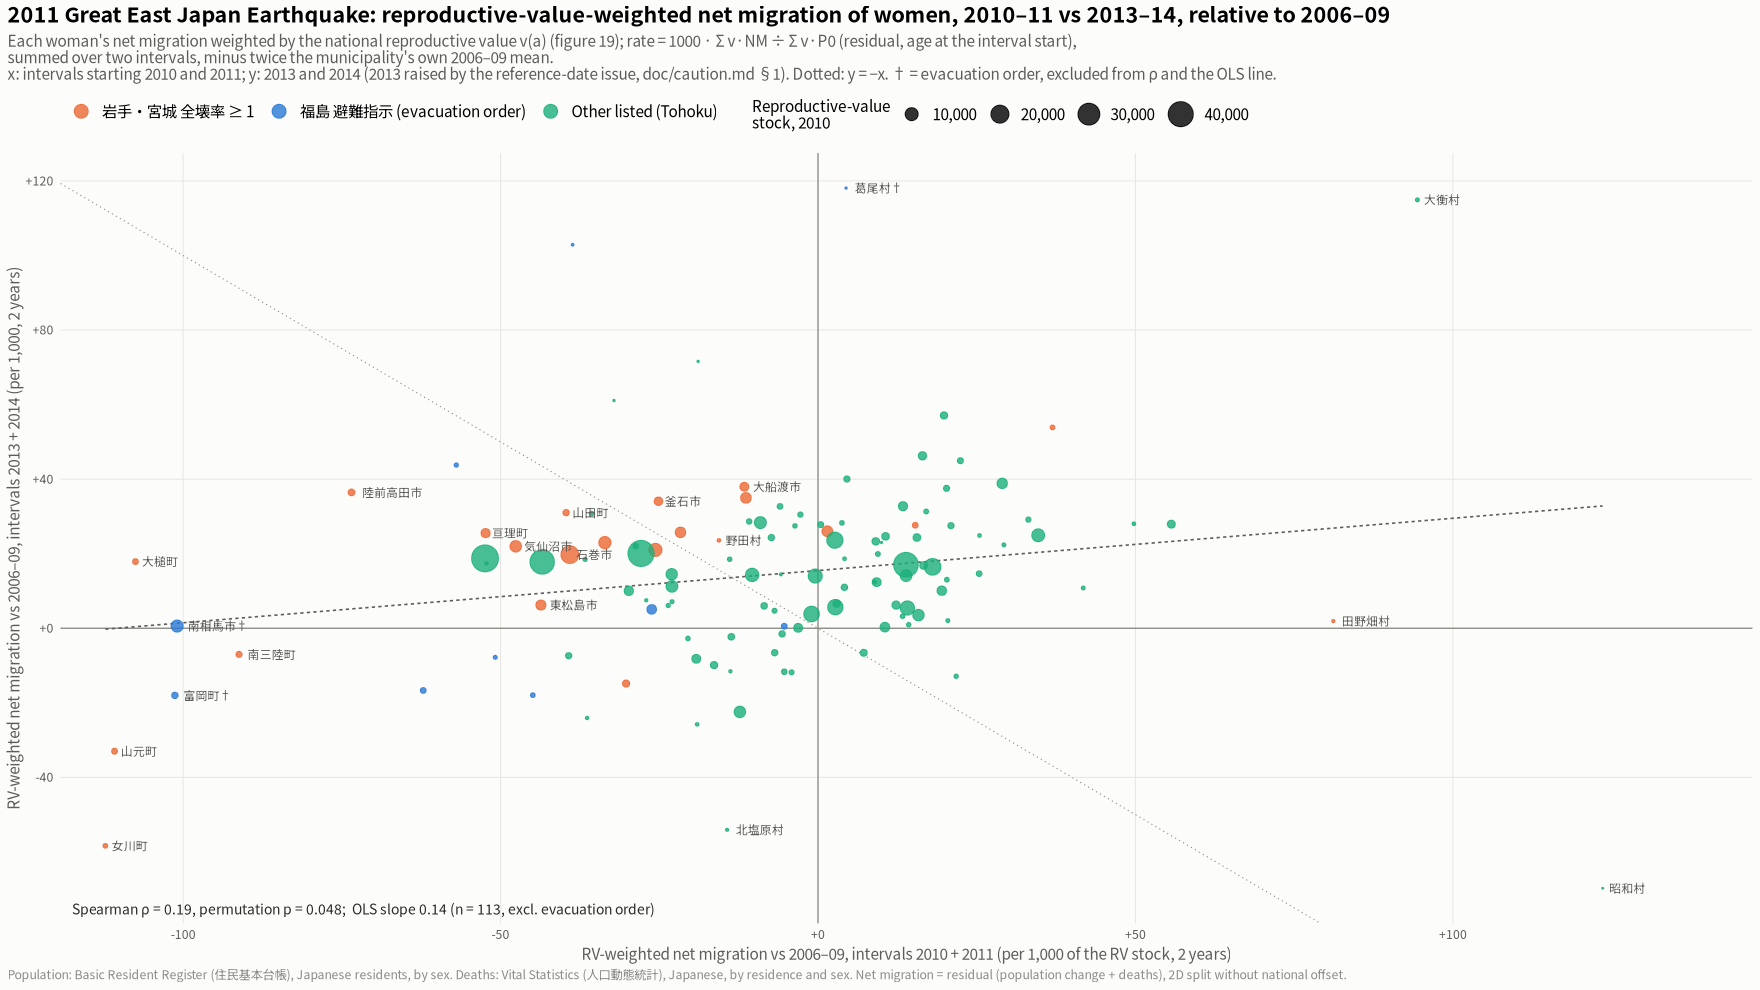

In [20]:
# RV-weighted net migration rate, women, Tohoku
rvm <- res9 |> filter(sex == "Women") |> inner_join(rv |> select(age, v), by = "age") |>
  group_by(code, start, span) |> summarise(NMv = sum(v * NM), Pv = sum(v * P0), .groups = "drop") |>
  mutate(cum = 1000 * NMv / Pv, rate = cum / span) |>
  group_by(code) |> mutate(base = mean(rate[start %in% 2006:2009])) |> ungroup()
scv <- rvm |> group_by(code) |>
  summarise(base = first(base), x = sum(cum[start %in% 2010:2011]) - 2 * first(base),
            y = sum(cum[start %in% 2013:2014]) - 2 * first(base),
            n_int = sum(start %in% c(2010, 2011, 2013, 2014)), pv2010 = Pv[start == 2010], .groups = "drop") |>
  inner_join(study, by = "code") |> mutate(group = factor(group, levels = group_levels))
stopifnot(all(scv$n_int == 4), nrow(scv) == nrow(study))
# Agreement with the women 20-39 outcome of figure 1
chkv <- scv |> select(code, x_rv = x, y_rv = y) |> inner_join(sc9 |> filter(sex == "Women") |> select(code, x, y), by = "code")
cat("Spearman, RV-weighted vs women 20-39 outcome: x", round(cor(chkv$x_rv, chkv$x, method = "spearman"), 2),
    " y", round(cor(chkv$y_rv, chkv$y, method = "spearman"), 2), "\n")
scv |> group_by(group) |>
  summarise(n = n(), median_base = round(median(base), 1), median_x = round(median(x), 1), median_y = round(median(y), 1), .groups = "drop") |>
  as.data.frame()

# Figure 20: x vs y (as figure 1), women, RV-weighted
fitv <- scv |> filter(!evacuation)
prv <- perm_rho(fitv$x, fitv$y)
labv_stat <- sprintf("Spearman ρ = %.2f, permutation p %s;  OLS slope %.2f (n = %d, excl. evacuation order)",
                     prv[["rho"]], ifelse(prv[["p"]] < 0.001, "< 0.001", sprintf("= %.3f", prv[["p"]])), coef(lm(y ~ x, fitv))[[2]], nrow(fitv))
cat(labv_stat, "\n")
labv <- scv |> filter(zenkai_rate >= 5 | rank(x) <= 5 | rank(y) <= 3 | rank(-y) <= 2)
p20 <- ggplot(scv, aes(x, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) + geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_abline(slope = -1, intercept = 0, colour = ink3, linewidth = 0.35, linetype = "13") +
  geom_smooth(data = fitv, method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pv2010), alpha = 0.8) +
  geom_text(data = labv, aes(label = short_lab), size = 2.7, colour = ink2, family = jp_font, hjust = -0.18, check_overlap = TRUE) +
  annotate("text", x = -Inf, y = -Inf, label = labv_stat, hjust = -0.02, vjust = -0.8, size = 3.2, colour = ink, family = jp_font) +
  scale_x_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.03, 0.1))) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_size_area(max_size = 8, labels = scales::comma, name = "Reproductive-value\nstock, 2010") +
  labs(title = "2011 Great East Japan Earthquake: reproductive-value-weighted net migration of women, 2010–11 vs 2013–14, relative to 2006–09",
       subtitle = paste0("Each woman's net migration weighted by the national reproductive value v(a) (figure 19); rate = 1000 · Σ v·NM ÷ Σ v·P0 (residual, age at the interval start),\n",
                         "summed over two intervals, minus twice the municipality's own 2006–09 mean.\n",
                         "x: intervals starting 2010 and 2011; y: 2013 and 2014 (2013 raised by the reference-date issue, doc/caution.md §1). Dotted: y = −x. † = evacuation order, excluded from ρ and the OLS line."),
       x = "RV-weighted net migration vs 2006–09, intervals 2010 + 2011 (per 1,000 of the RV stock, 2 years)",
       y = "RV-weighted net migration vs 2006–09, intervals 2013 + 2014 (per 1,000, 2 years)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p20, "20_rv_women_net_1011_vs_1314", width = 14, height = 10)

In [21]:
# Regression on the RV-weighted outcome (women), 30 municipalities with 全壊率 >= 1
loss_rv <- "2010–11 RV-weighted net migration vs 2006–09 (women)"
dv <- scv |> filter(!evacuation) |> inner_join(se9, by = "code") |> mutate(!!loss_rv := x, w = sqrt(pv2010))
stopifnot(nrow(dv) == 30)
cat("Spearman of y with the protocol's 女性20-39 recovery outcome:", round(cor(dv$y, dv$prot_f2039, method = "spearman"), 2), "\n")
expl_rv <- c(loss_rv, se_vars)
full_rv <- setdiff(expl_rv, c("持ち家率", "職住自足率（従業地/常住就業者）"))
key_rv <- setNames(full_rv, paste0("v", seq_along(full_rv)))

uni_rv <- bind_rows(lapply(expl_rv, function(v) {
  dd <- dv |> filter(!is.na(.data[[v]])); pr <- perm_rho(dd[[v]], dd$y)
  tibble(variable = v, n = nrow(dd), rho = pr[["rho"]], p_perm = pr[["p"]])
})) |> mutate(p_holm = p.adjust(p_perm, "holm"))
cat("\nUnivariate Spearman (n = 30; 持ち家率 n = 20):\n")
uni_rv |> mutate(rho = round(rho, 2), p_perm = signif(p_perm, 2), p_holm = signif(p_holm, 2)) |> as.data.frame()

slopes_rv <- function(weighted) {
  one <- function(v, adj) {
    dd <- dv |> transmute(y, w, v = zs(.data[[v]]), loss = zs(x)) |> filter(!is.na(v))
    f <- if (adj == "none" || v == loss_rv) y ~ v else y ~ v + loss
    m <- if (weighted) lm(f, data = dd, weights = w) else lm(f, data = dd)
    ci <- confint(m)["v", ]
    tibble(variable = v, model = adj, beta = coef(m)[["v"]], lo = ci[[1]], hi = ci[[2]], p = summary(m)$coefficients["v", 4])
  }
  X <- dv |> transmute(y, w, across(all_of(full_rv), zs)); names(X) <- c("y", "w", names(key_rv))
  fml <- reformulate(names(key_rv), "y")
  m_full <- if (weighted) lm(fml, data = X, weights = w) else lm(fml, data = X)
  full <- tibble(term = names(key_rv), variable = unname(key_rv), model = "full", beta = coef(m_full)[term],
                 lo = confint(m_full)[term, 1], hi = confint(m_full)[term, 2], p = summary(m_full)$coefficients[term, 4])
  wl <- if (weighted) X$w else rep(1, nrow(X))
  loo <- function(form) sqrt(sum(wl * sapply(seq_len(nrow(X)), function(i) {
    m <- if (weighted) lm(form, data = X[-i, ], weights = w) else lm(form, data = X[-i, ]); (X$y[i] - predict(m, X[i, ]))^2 })) / sum(wl))
  step_keep <- paste(key_rv[attr(terms(step(m_full, trace = 0)), "term.labels")], collapse = "; ")
  lab <- if (weighted) "√-weighted" else "Unweighted"
  list(slopes = bind_rows(bind_rows(lapply(c("none", "loss"), function(a) bind_rows(lapply(expl_rv, one, adj = a)))), select(full, -term)) |>
         mutate(weighting = lab),
       summary = tibble(weighting = lab, r2_full = summary(m_full)$r.squared, adj_r2_full = summary(m_full)$adj.r.squared,
                        step_keeps = step_keep, loo_null = loo(y ~ 1), loo_loss = loo(y ~ v1), loo_full = loo(fml)))
}
rv_u <- slopes_rv(FALSE); rv_w <- slopes_rv(TRUE)
sl_rv <- bind_rows(rv_u$slopes, rv_w$slopes)
cat("\nSlope per 1 SD (per 1,000 of the RV stock, 2 years), with p:\n")
sl_rv |> transmute(weighting, variable, model, est = sprintf("%+.1f (p %.2g)", beta, p)) |>
  pivot_wider(names_from = c(weighting, model), values_from = est) |> as.data.frame()
cat("\nModel summaries (LOO = leave-one-out RMSE; weighted in the √-weighted rows):\n")
bind_rows(rv_u$summary, rv_w$summary) |> mutate(across(where(is.numeric), \(v) round(v, 2))) |> as.data.frame()

Spearman of y with the protocol's 女性20-39 recovery outcome: 0.76 

Univariate Spearman (n = 30; 持ち家率 n = 20):


variable,n,rho,p_perm,p_holm
<chr>,<int>,<dbl>,<dbl>,<dbl>
2010–11 RV-weighted net migration vs 2006–09 (women),30,0.28,0.120,1.00
市町村内の働く場所÷住民の働き手(%),30,0.28,0.140,1.00
事業所数/人口千人,30,0.42,0.017,0.19
通勤流出率,30,-0.15,0.430,1.00
失業率,30,0.13,0.500,1.00
第1次産業比,30,-0.10,0.590,1.00
第2次産業比,30,-0.25,0.180,1.00
職住自足率（従業地/常住就業者）,30,0.23,0.220,1.00
納税者1人当たり課税所得(万円),30,-0.04,0.830,1.00



Slope per 1 SD (per 1,000 of the RV stock, 2 years), with p:


variable,Unweighted_none,Unweighted_loss,Unweighted_full,√-weighted_none,√-weighted_loss,√-weighted_full
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2010–11 RV-weighted net migration vs 2006–09 (women),+10.6 (p 0.0078),+10.6 (p 0.0078),+10.8 (p 0.022),+11.5 (p 0.0057),+11.5 (p 0.0057),+10.1 (p 0.031)
市町村内の働く場所÷住民の働き手(%),+3.7 (p 0.38),+3.7 (p 0.32),-6.0 (p 0.5),+5.3 (p 0.13),+4.3 (p 0.17),+0.9 (p 0.91)
事業所数/人口千人,+5.1 (p 0.23),+5.2 (p 0.16),+9.8 (p 0.29),+5.4 (p 0.11),+5.1 (p 0.085),+3.3 (p 0.68)
通勤流出率,-4.2 (p 0.31),-3.8 (p 0.31),-6.6 (p 0.31),-3.6 (p 0.24),-3.7 (p 0.17),-4.1 (p 0.38)
失業率,+6.8 (p 0.1),+6.3 (p 0.088),+9.7 (p 0.073),+4.6 (p 0.24),+3.2 (p 0.37),+5.0 (p 0.29)
第1次産業比,-1.9 (p 0.66),-3.6 (p 0.34),-3.2 (p 0.74),-2.4 (p 0.54),-1.9 (p 0.57),-5.4 (p 0.49)
第2次産業比,-6.2 (p 0.14),-3.0 (p 0.45),-2.2 (p 0.71),-4.8 (p 0.18),-2.4 (p 0.48),-4.7 (p 0.34)
職住自足率（従業地/常住就業者）,+1.5 (p 0.73),+0.7 (p 0.85),NA,+4.0 (p 0.27),+3.0 (p 0.36),NA
納税者1人当たり課税所得(万円),-0.5 (p 0.91),+0.3 (p 0.94),+4.6 (p 0.64),-0.0 (p 0.99),-0.8 (p 0.8),-1.4 (p 0.87)



Model summaries (LOO = leave-one-out RMSE; weighted in the √-weighted rows):


weighting,r2_full,adj_r2_full,step_keeps,loo_null,loo_loss,loo_full
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
Unweighted,0.48,0.24,2010–11 RV-weighted net migration vs 2006–09 (women); 事業所数/人口千人; 失業率,22.58,22.49,29.51
√-weighted,0.44,0.18,2010–11 RV-weighted net migration vs 2006–09 (women); 通勤流出率; 失業率,17.77,16.68,21.27


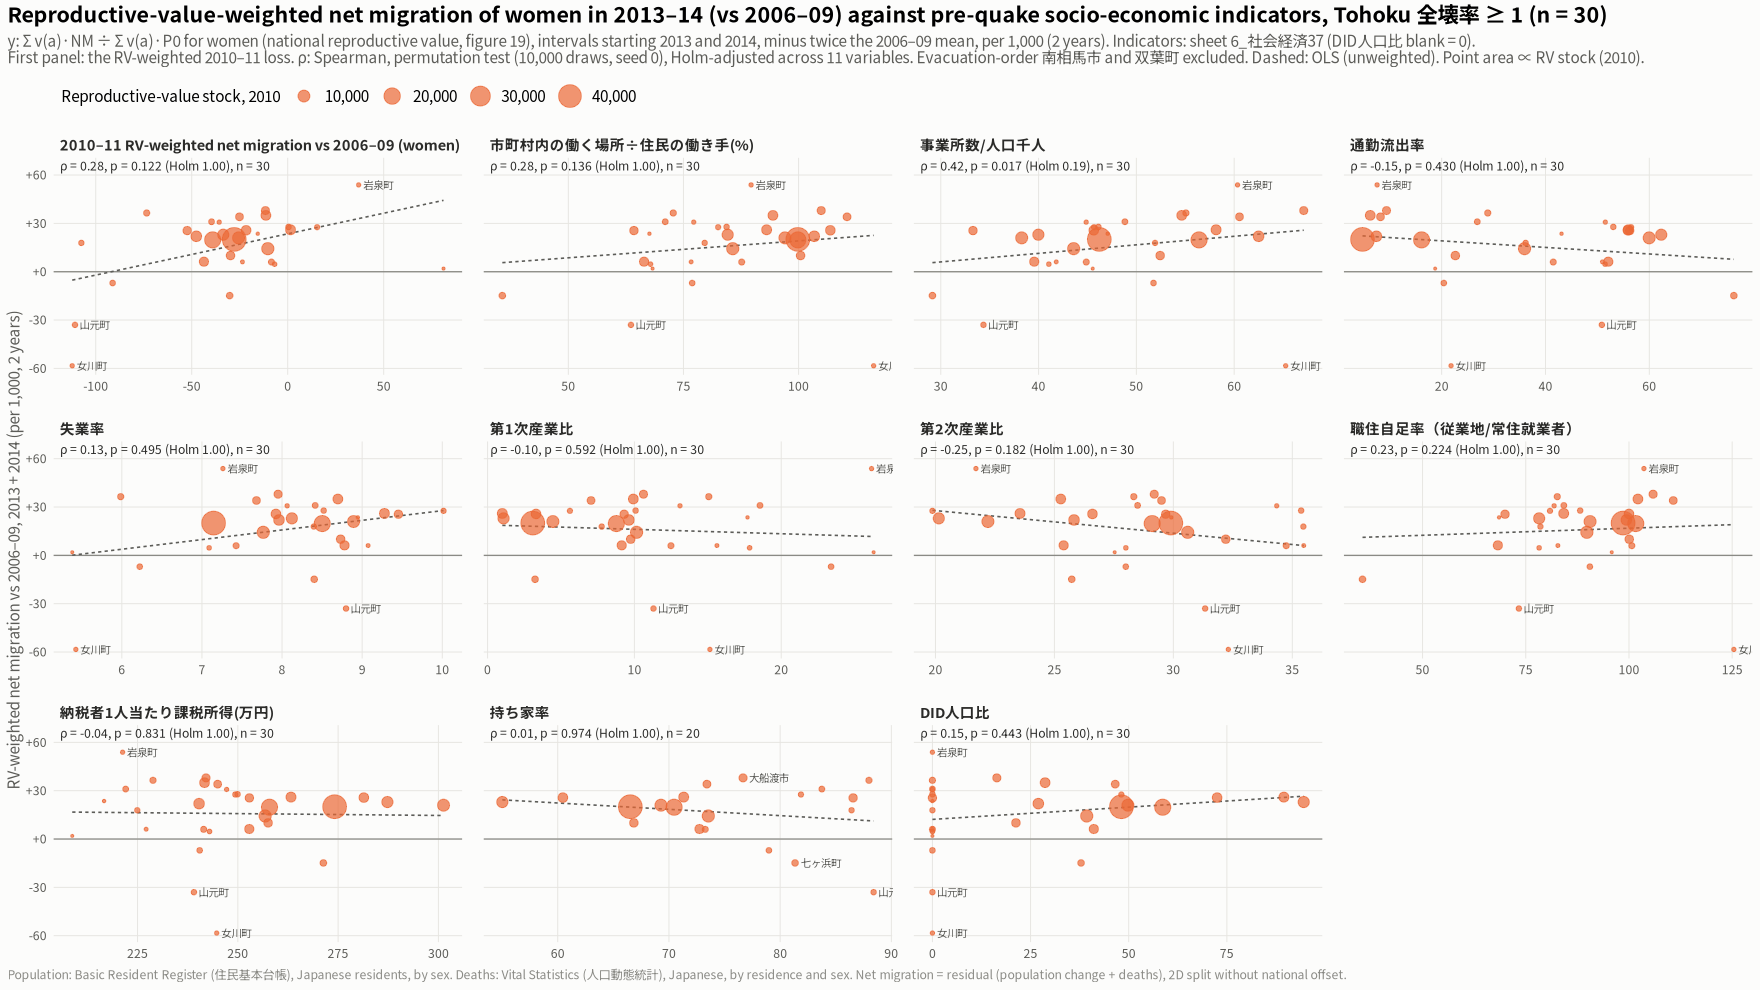

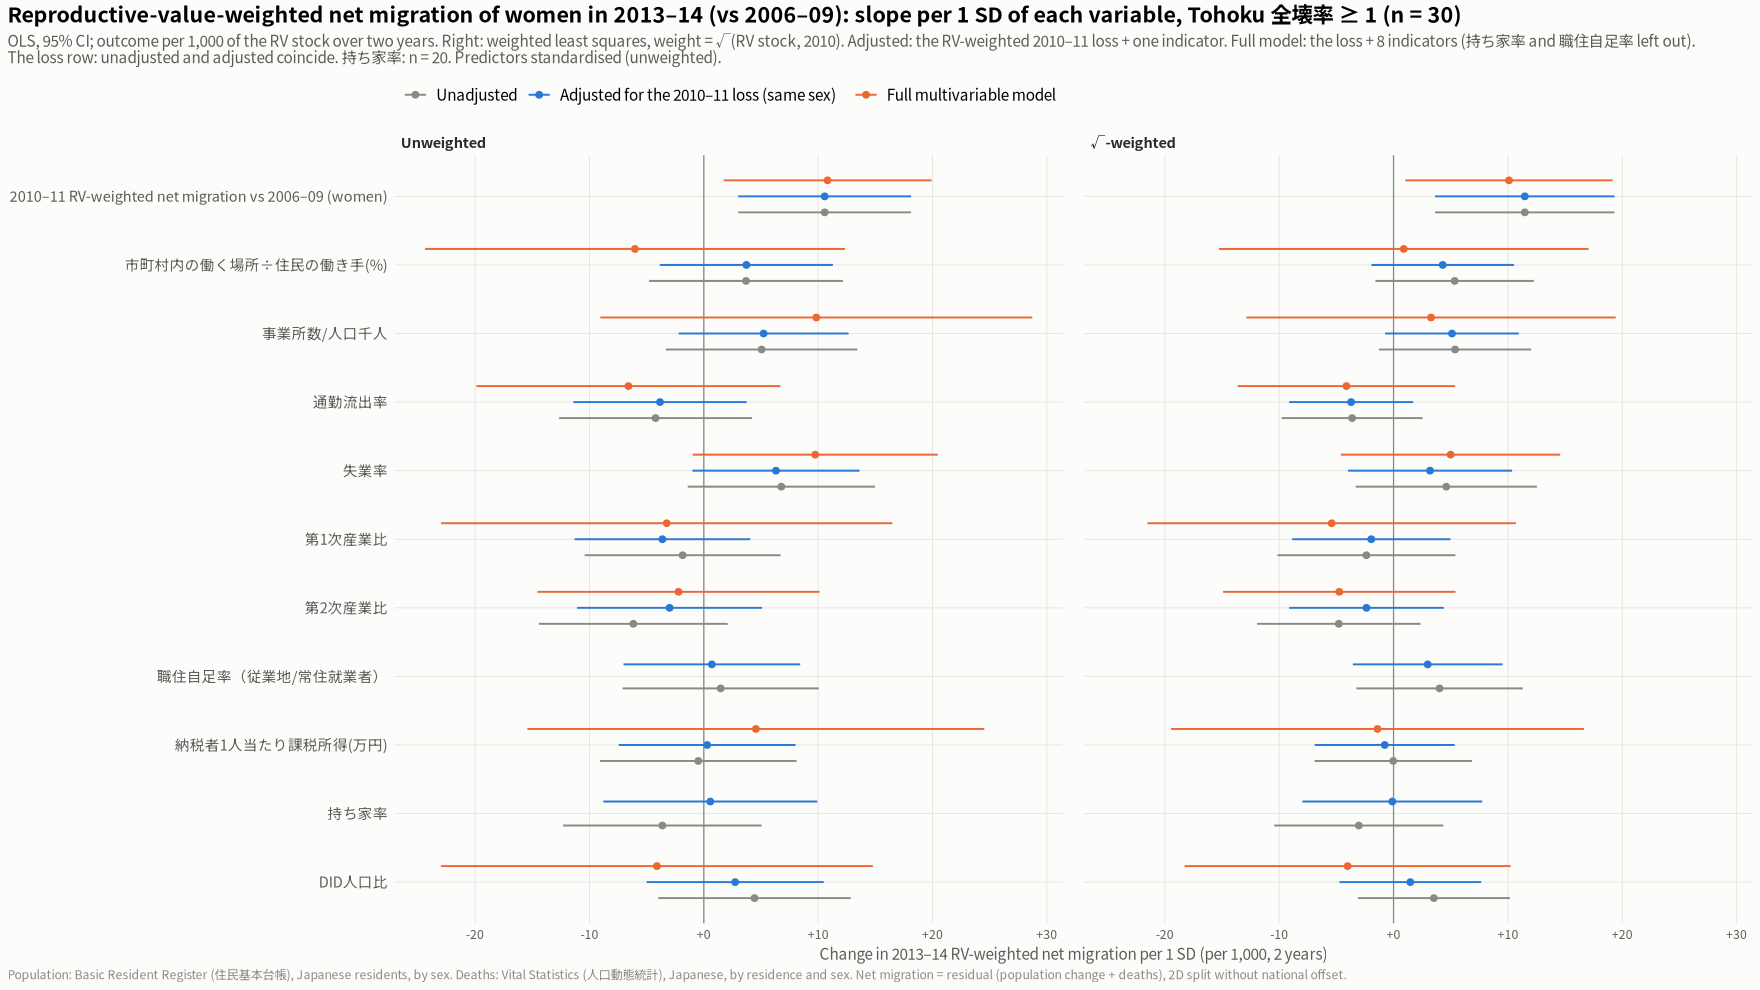

In [22]:
# Figure 21: outcome vs each variable (as figure 2), point area = RV stock
long_rv <- dv |> select(code, short_lab, y, pv2010, all_of(expl_rv)) |>
  pivot_longer(all_of(expl_rv), names_to = "variable", values_to = "value") |>
  filter(!is.na(value)) |> mutate(variable = factor(variable, levels = expl_rv))
st_rv <- uni_rv |> mutate(variable = factor(variable, levels = expl_rv),
                          lab = sprintf("ρ = %.2f, p %s (Holm %s), n = %d", rho, ifelse(p_perm < 0.001, "< 0.001", sprintf("= %.3f", p_perm)),
                                        ifelse(p_holm < 0.001, "< 0.001", sprintf("%.2f", p_holm)), n))
p21 <- ggplot(long_rv, aes(value, y)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(size = pv2010), colour = sex_cols[["Women"]], alpha = 0.7) +
  geom_text(data = long_rv |> group_by(variable) |> filter(rank(y) <= 2 | rank(-y) <= 1) |> ungroup(),
            aes(label = short_lab), size = 2.4, colour = ink2, family = jp_font, hjust = -0.15, check_overlap = TRUE) +
  geom_text(data = st_rv, aes(x = -Inf, y = Inf, label = lab), inherit.aes = FALSE, hjust = -0.03, vjust = 1.4, size = 2.8, colour = ink, family = jp_font) +
  facet_wrap(~variable, scales = "free_x", ncol = 4) +
  scale_size_area(max_size = 7, labels = scales::comma, name = "Reproductive-value stock, 2010") +
  scale_y_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.05, 0.15))) +
  labs(title = "Reproductive-value-weighted net migration of women in 2013–14 (vs 2006–09) against pre-quake socio-economic indicators, Tohoku 全壊率 ≥ 1 (n = 30)",
       subtitle = paste0("y: Σ v(a)·NM ÷ Σ v(a)·P0 for women (national reproductive value, figure 19), intervals starting 2013 and 2014, minus twice the 2006–09 mean, per 1,000 (2 years). ",
                         "Indicators: sheet 6_社会経済37 (DID人口比 blank = 0).\n",
                         "First panel: the RV-weighted 2010–11 loss. ρ: Spearman, permutation test (10,000 draws, seed 0), Holm-adjusted across 11 variables. ",
                         "Evacuation-order 南相馬市 and 双葉町 excluded. Dashed: OLS (unweighted). Point area ∝ RV stock (2010)."),
       x = NULL, y = "RV-weighted net migration vs 2006–09, 2013 + 2014 (per 1,000, 2 years)", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), strip.text = element_text(size = 9.5))
show_save(p21, "21_rv_women_socioecon_vs_net_1314", width = 18, height = 12.5)

# Figure 22: slopes per 1 SD, unweighted and sqrt-weighted (as figures 3 and 18)
f22 <- sl_rv |> mutate(model = factor(mlabs9[model], levels = mlabs9), variable = factor(variable, levels = rev(expl_rv)),
                       weighting = factor(weighting, levels = c("Unweighted", "√-weighted")))
p22 <- ggplot(f22, aes(beta, variable, colour = model)) +
  geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_errorbar(aes(xmin = lo, xmax = hi), width = 0, orientation = "y", linewidth = 0.6, position = position_dodge(width = 0.7)) +
  geom_point(size = 1.8, position = position_dodge(width = 0.7)) +
  facet_wrap(~weighting, nrow = 1) +
  scale_colour_manual(values = setNames(c("#8a8a85", "#2a78d6", "#eb6834"), mlabs9), name = NULL) +
  scale_x_continuous(labels = function(v) sprintf("%+g", v)) +
  labs(title = "Reproductive-value-weighted net migration of women in 2013–14 (vs 2006–09): slope per 1 SD of each variable, Tohoku 全壊率 ≥ 1 (n = 30)",
       subtitle = paste0("OLS, 95% CI; outcome per 1,000 of the RV stock over two years. Right: weighted least squares, weight = √(RV stock, 2010). ",
                         "Adjusted: the RV-weighted 2010–11 loss + one indicator. Full model: the loss + 8 indicators (持ち家率 and 職住自足率 left out).\n",
                         "The loss row: unadjusted and adjusted coincide. 持ち家率: n = 20. Predictors standardised (unweighted)."),
       x = "Change in 2013–14 RV-weighted net migration per 1 SD (per 1,000, 2 years)", y = NULL, caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3), axis.text.y = element_text(size = 9.5))
show_save(p22, "22_rv_women_socioecon_slopes", width = 18, height = 9)

## Figure 23: women aged 20–39 vs everyone else, Tohoku

How closely does the net migration of women aged 20–39 follow the rest of the population? Each point is one listed Tohoku municipality. The residual is the one of this notebook (age at the interval start).
- **x:** women aged 20–39, 1000 · ΣNM ÷ ΣP<sub>0</sub> over those women.
- **y:** everyone else (men of all ages + women under 20 or 40 and over). The women 20–39 part is left out, so the two rates share no people.
- **Rows:** the intervals starting 2010 + 2011, and 2013 + 2014 (summed, per 1,000, two years).
- **Columns:** the raw rate, and the rate minus twice its own 2006–09 annual mean.
- **Statistics:** Spearman ρ (permutation test) and OLS, excluding the evacuation-order municipalities. The dotted line is y = x.

window,measure,n,rho,p,pearson,slope
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Intervals 2010 + 2011,"Net migration (per 1,000, 2 years)",113,0.67,1e-04,0.76,0.34
Intervals 2010 + 2011,Minus twice the 2006–09 annual mean,113,0.58,1e-04,0.69,0.32
Intervals 2013 + 2014,"Net migration (per 1,000, 2 years)",113,0.50,1e-04,0.47,0.15
Intervals 2013 + 2014,Minus twice the 2006–09 annual mean,113,0.44,1e-04,0.26,0.08


window,measure,n_岩手・宮城 全壊率 ≥ 1,n_Other listed (Tohoku),rho_岩手・宮城 全壊率 ≥ 1,rho_Other listed (Tohoku)
<fct>,<fct>,<int>,<int>,<dbl>,<dbl>
Intervals 2010 + 2011,"Net migration (per 1,000, 2 years)",22,91,0.86,0.62
Intervals 2010 + 2011,Minus twice the 2006–09 annual mean,22,91,0.93,0.40
Intervals 2013 + 2014,"Net migration (per 1,000, 2 years)",22,91,0.72,0.47
Intervals 2013 + 2014,Minus twice the 2006–09 annual mean,22,91,0.68,0.35


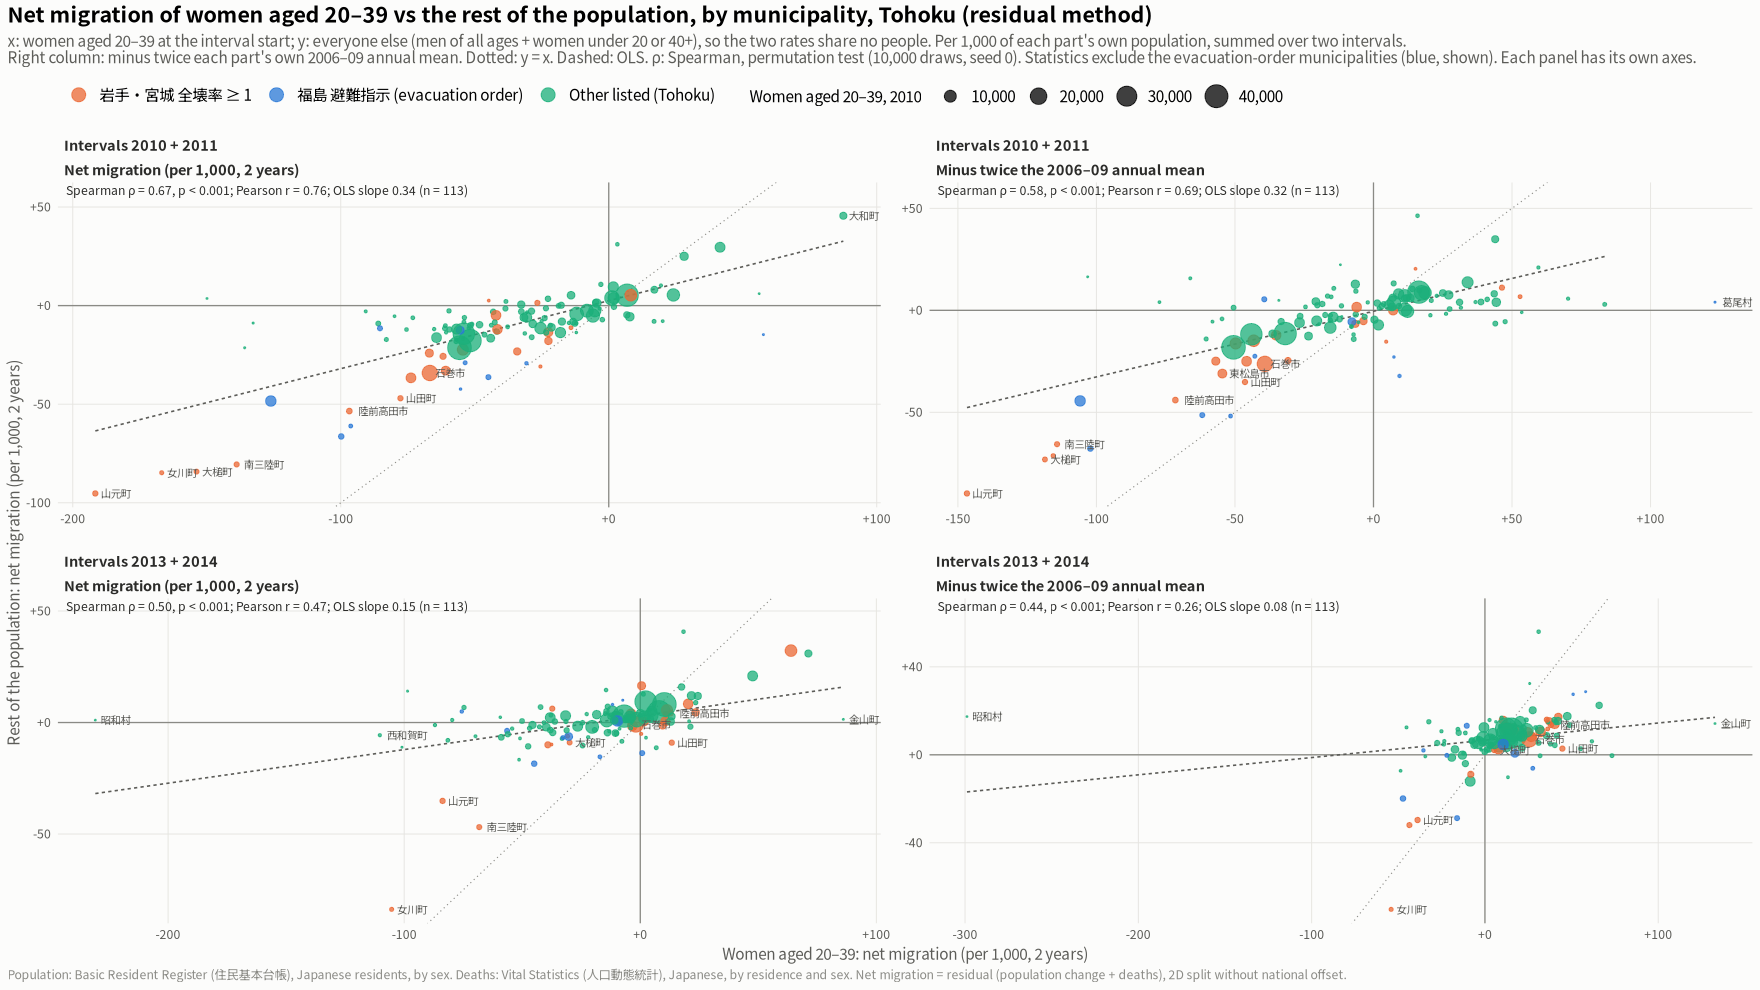

In [23]:
# Women 20-39 vs the rest of the population (men all ages + women outside 20-39), Tohoku
grp23 <- res9 |> mutate(part = ifelse(sex == "Women" & age >= 20 & age <= 39, "w2039", "rest")) |>
  group_by(code, part, start, span) |> summarise(NM = sum(NM), P0 = sum(P0), .groups = "drop") |>
  mutate(cum = 1000 * NM / P0, rate = cum / span) |>
  group_by(code, part) |> mutate(base = mean(rate[start %in% 2006:2009])) |> ungroup()
win23 <- c("Intervals 2010 + 2011" = "2010:2011", "Intervals 2013 + 2014" = "2013:2014")
meas23 <- c(raw = "Net migration (per 1,000, 2 years)", rel = "Minus twice the 2006–09 annual mean")
d23 <- bind_rows(lapply(names(win23), function(w) {
  yy <- eval(parse(text = win23[[w]]))
  grp23 |> group_by(code, part) |>
    summarise(raw = sum(cum[start %in% yy]), rel = raw - 2 * first(base), .groups = "drop") |> mutate(window = w)
})) |>
  pivot_longer(c(raw, rel), names_to = "measure", values_to = "val") |>
  pivot_wider(names_from = part, values_from = val) |>
  inner_join(study, by = "code") |>
  inner_join(sc9 |> filter(sex == "Women") |> select(code, pop2039_2010), by = "code") |>
  mutate(window = factor(window, levels = names(win23)), measure = factor(meas23[measure], levels = meas23),
         group = factor(group, levels = group_levels))
stopifnot(!anyNA(d23$w2039), !anyNA(d23$rest), nrow(d23) == 4 * nrow(study))

st23 <- d23 |> filter(!evacuation) |> group_by(window, measure) |> group_modify(function(d, k) {
  pr <- perm_rho(d$w2039, d$rest)
  tibble(n = nrow(d), rho = pr[["rho"]], p = pr[["p"]], pearson = cor(d$w2039, d$rest), slope = coef(lm(rest ~ w2039, d))[[2]])
}) |> ungroup() |>
  mutate(lab = sprintf("Spearman ρ = %.2f, p %s; Pearson r = %.2f; OLS slope %.2f (n = %d)",
                       rho, ifelse(p < 0.001, "< 0.001", sprintf("= %.3f", p)), pearson, slope, n))
st23 |> select(-lab) |> mutate(across(c(rho, pearson, slope), \(v) round(v, 2)), p = signif(p, 2)) |> as.data.frame()
# Same, by group (excluding evacuation order)
d23 |> filter(!evacuation) |> group_by(window, measure, group) |>
  summarise(n = n(), rho = round(cor(w2039, rest, method = "spearman"), 2), .groups = "drop") |>
  pivot_wider(names_from = group, values_from = c(n, rho)) |> as.data.frame()

lab23 <- d23 |> group_by(window, measure) |> filter(zenkai_rate >= 10 | evacuation & rank(rest) <= 3 | rank(w2039) <= 2 | rank(-w2039) <= 1) |> ungroup()
p23 <- ggplot(d23, aes(w2039, rest)) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) + geom_vline(xintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_abline(slope = 1, intercept = 0, colour = ink3, linewidth = 0.35, linetype = "13") +
  geom_smooth(data = d23 |> filter(!evacuation), method = "lm", formula = y ~ x, se = FALSE, colour = ink2, linewidth = 0.5, linetype = "22") +
  geom_point(aes(colour = group, size = pop2039_2010), alpha = 0.75) +
  geom_text(data = lab23, aes(label = short_lab), size = 2.4, colour = ink2, family = jp_font, hjust = -0.18, check_overlap = TRUE) +
  geom_text(data = st23, aes(x = -Inf, y = Inf, label = lab), inherit.aes = FALSE, hjust = -0.02, vjust = 1.4, size = 2.8, colour = ink, family = jp_font) +
  facet_wrap(window ~ measure, scales = "free", ncol = 2) +
  scale_x_continuous(labels = function(v) sprintf("%+g", v)) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v), expand = expansion(mult = c(0.05, 0.12))) +
  scale_colour_manual(values = group_cols, name = NULL) +
  scale_size_area(max_size = 7, labels = scales::comma, name = "Women aged 20–39, 2010") +
  labs(title = "Net migration of women aged 20–39 vs the rest of the population, by municipality, Tohoku (residual method)",
       subtitle = paste0("x: women aged 20–39 at the interval start; y: everyone else (men of all ages + women under 20 or 40+), so the two rates share no people. ",
                         "Per 1,000 of each part's own population, summed over two intervals.\n",
                         "Right column: minus twice each part's own 2006–09 annual mean. Dotted: y = x. Dashed: OLS. ρ: Spearman, permutation test (10,000 draws, seed 0). ",
                         "Statistics exclude the evacuation-order municipalities (blue, shown). Each panel has its own axes."),
       x = "Women aged 20–39: net migration (per 1,000, 2 years)", y = "Rest of the population: net migration (per 1,000, 2 years)",
       caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3)) +
  guides(colour = guide_legend(order = 1, override.aes = list(size = 4)), size = guide_legend(order = 2))
show_save(p23, "23_tohoku_women2039_vs_rest", width = 16, height = 13)